<a href="https://colab.research.google.com/github/nsix-colab/nestor/blob/main/UNIDAD_2_DISEN%CC%83O_ed2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Notas sobre autoría y acceso.** Materiales docentes desarrollados por A.M.Mayoral (2026) con la asistencia de Gemini 3.0 Pro, para el curso Diseño de Experimentos y Análisis Estadístico en Algoritmos con Python. Licencia [CC BY-SA]

Versión revisada (noviembre de 2026) con la asistencia de Claude.

#  📊  Unidad 2. Recolección de datos, diseños básicos y análisis exploratorio

## 🔰 **Descripción**

Introducimos estrategias para la planificación y almacenamiento eficiente de los resultados experimentales. Presentamos a continuación los diseños de experimentos más habituales, junto con ejemplos de aplicación. Finalizamos la unidad con un repaso de los procedimientos descriptivos numéricos y gráficos con los que realizar una primera inspección de los resultados experimentales, en busca del modelo estadístico a emplear y las relaciones a detectar.





## 🔥 **Conceptos clave**
1. Orquestación y Almacenamiento: La Ingeniería del Dato Experimental.
1. Diseños Experimentales: factorial, bloqueo, superficies de respuesta y relleno de espacio.
1. Exploración visual y Estadística Descriptiva.

## 🎯 **Objetivos**

Al finalizar esta unidad, serás capaz de:

1.  **Profesionalizar la captura de datos** (*Data Logging*), implementando rutinas de orquestación que almacenen no solo los resultados, sino también los metadatos y configuraciones del entorno para garantizar la trazabilidad.

1.  **Seleccionar la estrategia de experimentación óptima**, en función de los objetivos de investigación y los recursos disponibles para la experimentación.

3.  **Inspeccionar los datos**, aplicando técnicas de **Análisis Exploratorio de Datos (EDA)** para obtener descriptivos básicos y detectar anomalías, *outliers* imposibles y valores perdidos antes de que contaminen tus modelos.
4.  **Identificar sospechas de asociaciones e interacciones** entre factores a la hora de explicar la variación de la métrica de respuestas, utilizando gráficos de asociación, condicionados y mapas de calor.

## 🧭 **Cómo usar este cuaderno**

- Cada apartado sigue el ciclo Reto → Herramientas → Referencias → Solución.
- Los bloques marcados con 📖 son **lecturas opcionales**: amplían el contenido, pero no hacen falta para seguir la sesión.
- Las celdas tituladas **Plantilla** están escritas con factores genéricos (un diccionario de factores y niveles). Cambia el diccionario y sirven para tu propio problema.
- Las funciones `construir_plan` y `ejecutar_plan` se definen en el apartado 1.2 y se reutilizan en toda la unidad: ejecuta las celdas en orden.

In [ ]:
# Preparación del entorno (ejecutar primero)
try:
    import pyDOE3
except ImportError:
    !pip install -q pyDOE3
    import pyDOE3

import os, time, platform, itertools
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 🟤  **1. Orquestación y Almacenamiento: La Ingeniería del Dato Experimental**

### ℹ️ Introducción

Antes de decidir qué experimento ejecutar o qué test estadístico aplicar, debemos resolver el problema más fundamental de la ciencia de datos: **¿Cómo vamos a capturar la realidad?**

Un error común en investigación es centrarse en el algoritmo y dejar el almacenamiento de resultados como una tarea secundaria ("ya copiaré los logs de la consola a un Excel"). Esto lleva a:

1.  **Pérdida de metadatos:** Olvidas anotar qué versión del código o qué hardware se usó.
2.  **Formatos incompatibles:** Datos "anchos" (Wide) difíciles de procesar por librerías estadísticas.
3.  **Irreproducibilidad:** La imposibilidad de volver a generar los gráficos meses después.

En esta sección, definiremos la arquitectura de datos que usaremos para **cualquier** diseño experimental posterior.



### 🔶 **1.1 El Principio de los Datos Ordenados (*Tidy Data*)**

#### 🚀 **Reto 1**

**La Hoja de Cálculo Humana**

Es natural anotar los resultados pensando en cómo *leerlos* nosotros mismos. Típicamente creamos tablas "anchas" donde cada columna es una ejecución.

*Ejemplo de Mala Praxis (Formato Wide):*
| Algoritmo | Run 1 (ms) | Run 2 (ms) | Run 3 (ms) |
|-----------|------------|------------|------------|
| A         | 100        | 102        | 98         |
| B         | 150        | 155        | 149        |

**El Problema:**

Este formato es tóxico para la automatización. Si quieres comparar 50 "Runs" o añadir una variable nueva (ej. temperatura), tienes que rediseñar toda la tabla. Librerías como `seaborn` o `scikit-learn` no saben interpretar esto.

#### 🧰 **Herramientas 1**

**Tidy Data: formato Long**

Para que nuestros experimentos sean escalables, debemos abandonar la forma humana de anotar datos (matrices visuales) y adoptar el formato **Long (Tidy)**.

Las tres reglas de oro del Tidy Data (Wickham, 2014):
1.  Cada **variable** debe tener su propia **columna**.
2.  Cada **observación** (o ejecución experimental) debe tener su propia **fila**.
3.  Cada **valor** debe tener su propia **celda**.

Este es el estándar que usaremos. Repite identificadores, pero permite filtrar, agrupar y visualizar sin reestructurar la tabla.

| Algoritmo | Run_ID | Tiempo_ms | Fecha       | Versión |
|-----------|--------|-----------|-------------|---------|
| A         | 1      | 100       | 2023-10-01  | v1.0    |
| A         | 2      | 102       | 2023-10-01  | v1.0    |
| B         | 1      | 150       | 2023-10-01  | v1.0    |

#### 🔑 **Solución 1**

**El Formato Long**

Transformamos la estructura para que sea escalable. Repetimos etiquetas, pero ganamos flexibilidad total.



In [ ]:
import pandas as pd

# Datos "Humanos" (Malos para programar)
datos_wide = {
    'Algoritmo': ['A', 'B'],
    'Run_1': [100, 150],
    'Run_2': [102, 155]
}

# Transformación a Tidy Data (Melt)
df_wide = pd.DataFrame(datos_wide)
df_tidy = df_wide.melt(id_vars='Algoritmo', var_name='Run_ID', value_name='Tiempo_ms')

print("--- Estructura Wide ---")
print(df_wide)
print("\n")

print("--- Estructura Tidy (Lista para Análisis) ---")
print(df_tidy)
# Nota cómo ahora 'Run_ID' es una variable que podemos filtrar,
# y 'Tiempo_ms' es una columna única que podemos promediar.

--- Estructura Wide ---
  Algoritmo  Run_1  Run_2
0         A    100    102
1         B    150    155


--- Estructura Tidy (Lista para Análisis) ---
  Algoritmo Run_ID  Tiempo_ms
0         A  Run_1        100
1         B  Run_1        150
2         A  Run_2        102
3         B  Run_2        155


### 🔶 **1.2. Orquestación: Automatizando la Recolección (*Logging*)**



#### 🚀 **Reto 2**

**"El Cowboy de la Consola"**

Ejecutas tu código, miras la terminal, copias el resultado y lo pegas en un txt o Excel.

El **Problema**:

* **Irreproducibilidad**: ¿Qué parámetros usaste para ese resultado? Se te olvidó anotarlo.

* **Contexto perdido**: ¿Se ejecutó en la GPU o en la CPU? ¿Qué versión de la librería tenías?

#### 🧰 **Herramientas 2**

**El Patrón "Experiment Logger"**

Nunca confíes en la recolección manual. En lugar de imprimir (print), el experimento debe retornar datos estructurados. Debemos programar nuestros experimentos para que el código **se auto-documente**.


En lugar de imprimir `print()` a la consola, guardaremos cada evento, junto con su contexto, en una lista de diccionarios que luego se convertirá en un DataFrame:


**Buenas prácticas**

- Es recomendable crear siempre un **esquema de columnas** estable, con nombres claros, que se respete en todos los experimentos.

- **Log de parámetros**. Cada ejecución debe generar una fila en una tabla (o una entrada JSON) con al menos:

  - nombre del experimento
  - algoritmo
  - valores de los parámetros
  - seed/semilla
  - métricas de rendimiento (tiempo, precisión, etc.)
  - información de hardware.

- Conviene también fijar o registrar:
  - versión de Python.
  - versiones de librerías (por ejemplo, `pip freeze`).
  - número de hilos / uso de BLAS.
  - hardware (CPU, RAM, GPU).
  - seed de todos los generadores aleatorios relevantes (NumPy, PyTorch, etc.).

- Interesa definir un *runner* que reciba una configuración y devuelva un registro completo de resultados.

**Esquema de una fila por ejecución**

Un esquema que sirve para casi cualquier experimento con algoritmos:

| Columna | Qué guarda |
|--|--|
| `orden` | Posición de la ejecución en el plan aleatorizado |
| `id_config` | Identificador de la configuración (combinación de niveles de los factores) |
| una columna por factor | Nivel de cada factor en esa ejecución |
| `instancia` (u otro bloque) | Sobre qué instancia, dataset o máquina se ejecutó |
| `replica` | Número de réplica dentro de la configuración |
| `semilla` | Semilla del generador aleatorio de esa ejecución (Unidad 1, apartado 4) |
| una columna por respuesta | Valor de cada variable respuesta |
| `estado` | `ok`, `timeout` o `error` |
| `duracion_s` y metadatos | Duración, fecha, versiones y máquina |

Dos reglas:

- **El plan se escribe antes de ejecutar.** La tabla con todas las ejecuciones previstas (configuración, réplica, semilla y orden) se genera primero; el *runner* solo la recorre y rellena las respuestas.
- **Las ejecuciones fallidas también son filas.** Si una ejecución agota el tiempo o da error, se registra con su `estado` y la respuesta vacía (`NaN`). Si se omite, el diseño queda desbalanceado sin que nadie lo sepa y las configuraciones difíciles parecen mejores de lo que son.

**Guardado incremental y reanudación**

Una campaña larga se interrumpe: se corta la sesión de Colab, falla un nodo. Si cada ejecución se añade al fichero en cuanto termina, al relanzar basta con saltarse las filas cuyo `orden` ya está guardado.

**Registrar no es fijar**

Aquí solo *registramos* el entorno (versiones, máquina, fecha) junto a cada resultado. Cómo *fijarlo* para que otra persona pueda reproducir el experimento (ficheros de dependencias, contenedores, opciones de determinismo) se trata en la Unidad 4, apartado 2.


#### 🔑 **Solución 2**

**El plan y la función orquestadora**

Separamos el trabajo en dos funciones que reutilizaremos en toda la unidad:

- `construir_plan`: a partir de una tabla de configuraciones (una fila por configuración), añade bloques y réplicas, asigna una semilla a cada ejecución y sortea el orden.
- `ejecutar_plan`: recorre el plan, llama al sistema a medir y guarda una fila por ejecución, con su estado y los metadatos del entorno. Si se le da un fichero, guarda cada ejecución al terminar y, si el fichero ya existe, reanuda donde se quedó.

In [ ]:
def construir_plan(diseno, n_replicas=1, bloques=None, semilla=2026, semillas_comunes=False):
    """Convierte una tabla de configuraciones en un plan de ejecución.

    diseno           : DataFrame con una fila por configuración y una columna por factor.
    n_replicas       : réplicas de cada configuración (dentro de cada bloque, si los hay).
    bloques          : diccionario {nombre_del_bloque: [niveles]}, por ejemplo
                       {'instancia': ['I1', 'I2', 'I3']}. Todas las configuraciones se
                       ejecutan en todos los bloques y el orden se sortea dentro de cada uno.
    semilla          : semilla raíz del experimento (hace reproducible el plan).
    semillas_comunes : si es True, todas las configuraciones comparten semilla dentro de
                       cada bloque y réplica (la semilla actúa como bloque).

    Devuelve un DataFrame con una fila por ejecución y las columnas
    orden, id_config, [bloques], factores, replica y semilla.
    """
    factores = list(diseno.columns)
    plan = diseno.reset_index(drop=True).copy()
    plan.insert(0, 'id_config', np.arange(1, len(plan) + 1))

    # 1. Bloques: cada configuración se repite en cada bloque
    nombres_bloque = list(bloques) if bloques else []
    if nombres_bloque:
        tabla_bloques = pd.DataFrame(list(itertools.product(*bloques.values())),
                                     columns=nombres_bloque)
        plan = tabla_bloques.merge(plan, how='cross')

    # 2. Réplicas
    plan = pd.concat([plan.assign(replica=r + 1) for r in range(n_replicas)],
                     ignore_index=True)

    # 3. Semillas: enteros independientes derivados de la semilla raíz
    raiz = np.random.SeedSequence(semilla)
    if semillas_comunes:
        claves = nombres_bloque + ['replica']
        grupos = plan[claves].drop_duplicates().reset_index(drop=True)
        grupos['semilla'] = raiz.generate_state(len(grupos))
        plan = plan.merge(grupos, on=claves)
    else:
        plan['semilla'] = raiz.generate_state(len(plan))

    # 4. Aleatorización del orden (dentro de cada bloque, si los hay)
    rng = np.random.default_rng(semilla)
    plan['_sorteo'] = rng.random(len(plan))
    plan = plan.sort_values(nombres_bloque + ['_sorteo']).drop(columns='_sorteo')
    plan = plan.reset_index(drop=True)
    plan.insert(0, 'orden', np.arange(1, len(plan) + 1))
    return plan[['orden', 'id_config'] + nombres_bloque + factores + ['replica', 'semilla']]


def metadatos_entorno():
    """Metadatos mínimos del entorno que acompañan a cada resultado."""
    return {'fecha': datetime.now().isoformat(timespec='seconds'),
            'python': platform.python_version(),
            'numpy': np.__version__,
            'sistema': platform.system(),
            'maquina': platform.machine()}


def ejecutar_plan(plan, sistema, respuestas, archivo=None):
    """Recorre el plan y devuelve una fila por ejecución.

    sistema    : función que recibe una fila del plan (diccionario con los factores y
                 la semilla) y devuelve un diccionario con las respuestas.
                 Si lanza TimeoutError, la ejecución se registra como 'timeout';
                 con cualquier otra excepción, como 'error'.
    respuestas : nombres de las variables respuesta que devuelve `sistema`.
    archivo    : CSV al que se añade cada ejecución al terminar. Si ya existe,
                 se saltan las ejecuciones guardadas (reanudación).
    """
    hechas = set()
    if archivo and os.path.exists(archivo):
        hechas = set(pd.read_csv(archivo)['orden'])

    registros = []
    for fila in plan.to_dict('records'):
        if fila['orden'] in hechas:
            continue
        salida = {r: np.nan for r in respuestas}
        inicio = time.perf_counter()
        try:
            salida.update(sistema(fila))
            estado = 'ok'
        except TimeoutError:
            estado = 'timeout'
        except Exception:
            estado = 'error'
        registro = {**fila, **salida, 'estado': estado,
                    'duracion_s': time.perf_counter() - inicio, **metadatos_entorno()}
        registros.append(registro)
        if archivo:   # guardado incremental: una línea por ejecución
            pd.DataFrame([registro]).to_csv(archivo, mode='a', index=False,
                                            header=not os.path.exists(archivo))

    if archivo:
        return pd.read_csv(archivo)
    return pd.DataFrame(registros)

Probamos las dos funciones con un sistema hipotético. El plan se imprime antes de ejecutar nada; después simulamos una interrupción y relanzamos.

In [ ]:
# 1. La "caja negra" o sistema a medir
# (En un caso real sería tu algoritmo, tu red neuronal, tu consulta a la base de datos...)
def proceso_simulado(fila):
    """Simula un proceso que tarda más cuanto mayor es la carga de trabajo."""
    rng = np.random.default_rng(fila['semilla'])     # aleatoriedad controlada por la semilla
    tiempo = 0.05 + fila['Carga_Trabajo'] * 0.02 + rng.normal(0, 0.01)
    return {'Tiempo_s': tiempo}

# 2. El plan: 3 configuraciones x 3 réplicas, con semilla propia y orden sorteado
configuraciones = pd.DataFrame({'Carga_Trabajo': [1, 5, 10]})   # Factor controlable
plan = construir_plan(configuraciones, n_replicas=3, semilla=2026)
print("--- Plan de ejecución (se escribe ANTES de ejecutar) ---")
print(plan)

# 3. Ejecución con guardado incremental
archivo = "resultados_carga.csv"
if os.path.exists(archivo):
    os.remove(archivo)          # en esta demostración empezamos de cero

_ = ejecutar_plan(plan.head(3), proceso_simulado, ['Tiempo_s'], archivo)      # "se corta" tras 3 ejecuciones
print(f"\nTras la interrupción hay {len(pd.read_csv(archivo))} ejecuciones guardadas.")
df_parcial = pd.read_csv(archivo)
display(df_parcial)

df_resultados = ejecutar_plan(plan, proceso_simulado, ['Tiempo_s'], archivo)  # relanzamos el plan completo
print(f"Tras relanzar hay {len(df_resultados)}: solo se han ejecutado las que faltaban.")

# 4. Dataset resultante: una fila por ejecución (formato tidy)
print("\n--- Dataset resultante ---")
display(df_resultados.head())

--- Plan de ejecución (se escribe ANTES de ejecutar) ---
   orden  id_config  Carga_Trabajo  replica     semilla
0      1          2              5        3  1857762792
1      2          1              1        1  2727543821
2      3          2              5        2  1703033196
3      4          1              1        2  1505698380
4      5          3             10        1   508070823
5      6          2              5        1  2207150826
6      7          3             10        3  3160045732
7      8          3             10        2  1600338967
8      9          1              1        3  1277837829

Tras la interrupción hay 3 ejecuciones guardadas.


,orden,id_config,Carga_Trabajo,replica,semilla,Tiempo_s,estado,duracion_s,fecha,python,numpy,sistema,maquina
0,1,2,5,3,1857762792,0.141632,ok,0.000170,2026-11-17T12:42:53,3.13.18,2.4.6,Linux,x86_64
1,2,1,1,1,2727543821,0.070252,ok,0.000118,2026-11-17T12:42:53,3.13.18,2.4.6,Linux,x86_64
2,3,2,5,2,1703033196,0.149704,ok,0.000078,2026-11-17T12:42:53,3.13.18,2.4.6,Linux,x86_64


Tras relanzar hay 9: solo se han ejecutado las que faltaban.

--- Dataset resultante ---


,orden,id_config,Carga_Trabajo,replica,semilla,Tiempo_s,estado,duracion_s,fecha,python,numpy,sistema,maquina
0,1,2,5,3,1857762792,0.141632,ok,0.000170,2026-11-17T12:42:53,3.13.18,2.4.6,Linux,x86_64
1,2,1,1,1,2727543821,0.070252,ok,0.000118,2026-11-17T12:42:53,3.13.18,2.4.6,Linux,x86_64
2,3,2,5,2,1703033196,0.149704,ok,0.000078,2026-11-17T12:42:53,3.13.18,2.4.6,Linux,x86_64
3,4,1,1,2,1505698380,0.073290,ok,0.000089,2026-11-17T12:42:53,3.13.18,2.4.6,Linux,x86_64
4,5,3,10,1,508070823,0.238722,ok,0.000076,2026-11-17T12:42:53,3.13.18,2.4.6,Linux,x86_64


### 🔶 **1.3. Persistencia y Almacenamiento**


#### 🚀 **Reto 3**
**El Infierno del CSV**

Guardas tus gigabytes de experimentos en .csv.

El Problema:

* Pérdida de Tipos: Al volver a leerlo, las fechas son strings ("2023-10-01") y los números a veces se leen como texto si hay algún error.

* Ineficiencia: Ocupa mucho espacio y es lento de leer en Big Data.

####  🧰 **Herramientas 3**


Una vez tenemos el DataFrame en memoria, debemos persistirlo en disco. Elegir el formato incorrecto puede costarnos gigabytes de espacio u horas de lectura.

**CSV (`.csv`)**
* **Formato:** Texto, con campos separados por `,` o `;`.
* **Pros:** Legible por humanos, compatible con Excel, universal.
* **Contras:** Lento de leer/escribir, pierde tipos de datos (una fecha puede volverse texto), ocupa mucho espacio.
* **Uso:** Datasets pequeños (< 100MB) o reportes finales.


Podemos optar (recomendable) por una serialización binaria (Parquet). Abandonamos el texto plano para usar formatos binarios de ingeniería de datos.

**Parquet (`.parquet`)**
* **Formato** columnar, comprimido y tipado.
* **Pros:** Binario, comprimido (ocupa muy poco), conserva el esquema (tipos de datos), extremadamente rápido. Estándar industrial y en Big Data (Hadoop, Spark, Pandas).
* **Contras:** Necesita librerías especializadas para leerse.
* **Uso:** Datasets grandes, logs de entrenamiento de Deep Learning, históricos.



#### 🔑 **Solución 3**

**Guardado Dual**

Guardamos en CSV solo si necesitamos mirarlo rápido con ojos humanos, pero usamos Parquet como fuente de la verdad.

In [ ]:
nombre_archivo = "resultados_v1"
df_resultados['fecha'] = pd.to_datetime(df_resultados['fecha'])   # la fecha, con tipo fecha

# 1. CSV: solo para inspección humana (pequeño)
df_resultados.to_csv(f"{nombre_archivo}.csv", index=False)

# 2. Parquet: persistencia real y análisis posterior (requiere pyarrow)
try:
    df_resultados.to_parquet(f"{nombre_archivo}.parquet", index=False)
except ImportError:
    !pip install -q pyarrow
    df_resultados.to_parquet(f"{nombre_archivo}.parquet", index=False)

# 3. ¿Qué tipos recuperamos al leer cada fichero?
tipos = pd.DataFrame({
    'CSV': pd.read_csv(f"{nombre_archivo}.csv").dtypes.astype(str),
    'Parquet': pd.read_parquet(f"{nombre_archivo}.parquet").dtypes.astype(str)
})
print(tipos.loc[['Carga_Trabajo', 'Tiempo_s', 'estado', 'fecha']])
print("\nEl CSV devuelve la fecha como texto; Parquet conserva su tipo.")

                   CSV         Parquet
Carga_Trabajo    int64           int64
Tiempo_s       float64         float64
estado          object          object
fecha           object  datetime64[ns]

El CSV devuelve la fecha como texto; Parquet conserva su tipo.


#### 📌 **Resumiendo ...**

Hemos establecido la base de ingeniería necesaria para investigar:
1.  Pensamos la estructura de datos sobre el diseño. Los datos se recolectan en formato **Long/Tidy**.
2.  Se incluyen **metadatos** de contexto automáticamente, con un 'orquestador' automático.
3.  Se persiste en formatos adecuados.
4.  El plan se escribe antes de ejecutar, y las ejecuciones fallidas también se registran.

Con esta infraestructura lista, en las siguientes secciones podremos centrarnos en la pregunta científica: **¿Qué valores debemos probar?** Cuántas réplicas son necesarias lo calcularemos en la Unidad 4 (análisis de potencia). Conformaremos así nuestro **Diseño Experimental**.

### 📚 **Referencias**

- Feitelson, D. G. (2007) *Experimental Computer Science: A Practical Guide*. Cambridge University Press. [Accesible en ResearchGate, enero 2026](https://www.researchgate.net/publication/278366016_Experimental_computer_science).

  💎 **Interés:** Es la guía moderna de metodología. Se centra menos en las fórmulas y más en la validez del experimento: ¿Es tu carga de trabajo (workload) realista o sintética? ¿Estás cometiendo sesgos de evaluación?


- Jain, R. (1991) *The Art of Computer Systems Performance Analysis*. Wiley.

  💎 **Interés:** Es la referencia de autoridad absoluta para entender la matemática detrás de los diseños factoriales ($2^k$), la teoría de colas y los intervalos de confianza. Si necesitas citar una fórmula de comparación, citas a Jain.

- Pavlo, A., et al. (2009). A Comparison of Approaches to Large-Scale Data Analysis. SIGMOD '09. ([Open Access](https://www.cs.cmu.edu/~pavlo/papers/benchmarks-sigmod09.pdf)).

  💎 **Interés:** Aunque es más antiguo, sienta las bases de por qué las bases de datos modernas y los sistemas de archivos (como los que usan Parquet) superan a los ficheros de texto plano (CSV) en entornos de investigación intensiva en datos.

- Pineau, J., et al. (2021). Improving Reproducibility in Machine Learning Research (A Report from the NeurIPS 2019 Reproducibility Program). Journal of Machine Learning Research, 22(164), 1-20. ([Open Access](https://jmlr.org/papers/volume22/20-303/20-303.pdf)).

  💎 **Interés:** Aborda el problema de las "semillas aleatorias" y la falta de metadatos en los experimentos computacionales modernos.

- Vohra, D. (2016). Apache Parquet.
En Practical Hadoop Ecosystem: A Definitive Guide to Hadoop Related Frameworks and Tools, pp. 325-336. Apress ([Accesible desde ResearchGate](https://www.researchgate.net/publication/308844523_Apache_Parquet)).

  💎 **Interés:** Explica el almacenamiento columnar. A diferencia de CSV (orientado a filas), Parquet permite leer solo las columnas necesarias (ahorro de I/O) y conserva el esquema de tipos (int, float, date), evitando errores de parseo.

- Wickham, H. (2014). Tidy Data. Journal of Statistical Software, 59(10), 1–23. ([Open Acces](https://www.jstatsoft.org/article/view/v059i10)).

  💎 **Interés:** Explica matemáticamente y con ejemplos por qué el formato "Largo" es superior al "Ancho" para el análisis vectorial y por qué el 80% del tiempo se pierde en limpieza de datos si no se sigue este principio.

- Wilson, G., et al. (2014). Best Practices for Scientific Computing. PLoS Biology, 12(1), e1001745. ([Open Access](https://journals.plos.org/plosbiology/article?id=10.1371/journal.pbio.1001745)).

  💎 **Interés:** Establece que "hacer que el ordenador repita las tareas" (automatización) y "guardar la historia" (logging/versiones) son requisitos éticos de la investigación, no solo conveniencias técnicas.

## 🟣 **2. Diseños Factoriales y Bloqueo**

### 🚀 **Reto**


#### **"La Optimización del Servidor de Streaming"**

Eres el ingeniero de rendimiento de una plataforma de video (tipo Netflix). Tu objetivo final es reducir la Latencia (tiempo de carga) del video. Tienes varias ideas para mejorarla, pero cada situación requiere un diseño distinto. Tu jefe te lanza cuatro desafíos secuenciales:

#### **1. Desafío A:** El test A/B (Diseño de un Factor / CRD)

- Situación: Tienes un nuevo algoritmo de compresión (`H.265`) y quieres ver si es más rápido que el actual (`H.264`).
- El Problema: Solo te importa una variable (el **Códec**). Tienes 100 usuarios disponibles para probar.
- Pregunta: ¿Cómo asignas los usuarios?

#### **2. Desafío B:** El Problema de la Región (Diseño por Bloques - RBD)

- Situación: Quieres repetir la prueba anterior, pero sabes que los usuarios de Europa tienen mejor internet que los de Latam.
- El Problema: Si asignas al azar y, por mala suerte, todos los usuarios de `H.265` caen en Europa, el algoritmo parecerá rapidísimo, pero será mentira (Factor de Confusión).
- Pregunta: ¿Cómo neutralizas el efecto "Región"?

#### **3. Desafío C:** La Combinatoria Perfecta (Factorial Completo)
- Situación: Ahora quieres probar 3 mejoras a la vez: **Códec** (`H.264` vs `H.265`), **Caché** (Activada vs Desactivada), **Protocolo** (HTTP/2 vs HTTP/3).
- El Problema: Si pruebas una cosa a la vez (OFAT), no verás si el Caché solo funciona bien con HTTP/3 (Interacción).
- Pregunta: ¿Cómo capturamos las interacciones?
- ¿Y si quisiéramos probar tres algoritmos: **Códec** (`H.264`,`H.265`, `H_266`)?

#### **4. Desafío D:** La Combinatoria Infernal (Factorial Fraccional)
- Situación: Ahora quieres probar 5 mejoras a la vez: Códec (`H.264` vs `H.265`), Caché (Redis vs. Memcached).Protocolo (HTTP/2 vs. HTTP/3), CDN (Proveedor A vs. Proveedor B) y Tamaño de Chunk de vídeo (2seg. vs. 6seg.)
- El Problema: Probar todas las configuraciones supone $2^5=32$ pruebas.
- Pregunta: ¿Es viable probar 32 configuraciones, o podemos reducirlas sin perder rigor para descubrir qué factores afectan?
- ¿Cómo podríamos ahorrar aún más si tuviéramos 10 factores posibles de variación y quisiéramos descubrir cuáles influyen sin probar una infinidad de configuraciones?

###  🧰 **Herramientas**


#### **El Mapa de Diseños**

Para resolver estos retos, necesitamos definir formalmente nuestras "arquitecturas" de prueba o tipos de diseños experimentales básicos, asumiendo siempre un **diseño balanceado**, esto es, con igual número de replicaciones en todas las configuraciones de factores propuestos. Es el diseño recomendado para facilitar el análisis posterior.

>Hablamos de un **Diseño Completamente Aleatorizado**, (*CRD Completely Randomized Design*) cuando asignamos totalmente al azar las unidades experimentales en los diferentes grupos o configuraciones a probar.

#### **A. Test A/B**

Es el diseño más simple, conocido en el ámbito científico como **Ensayo Controlado Aleatorizado** *(Randomized Controlled Trial, RCT)*.

- Estructura: Tienes un factor con dos niveles posibles (ej. dos algoritmos).
- Estrategia: Repartes las unidades experimentales (usuarios, ejecuciones) entre los dos niveles totalmente al azar y en igual número (estrategia CRD).
- Cuándo usarlo: Cuando el entorno es homogéneo y no hay factores de ruido grandes.


#### **B. Diseño en Bloques Completos Aleatorizados** (*RCBD, Randomized Complete Block Design*)

Es la evolución del CRD para entornos ruidosos.

- Estructura: Factores de Interés + Factores de Bloqueo (Nuisance).

- Estrategia: Divides la población en bloques. Dentro de cada bloque, haces el CRD con el otro factor.

- Cuándo usarlo: Cuando sabes que algo externo (región, día de la semana, navegador) afecta mucho a la respuesta, y es preciso controlarlo.

- Instancia y semilla como bloque: En algoritmia el bloque habitual es la **instancia** (o el dataset): todas las configuraciones se ejecutan sobre las mismas instancias y la comparación se hace dentro de cada una (Unidad 1, apartado 5). También la **semilla** puede actuar como bloque: si todas las configuraciones usan las mismas semillas, comparten punto de partida y parte del ruido se cancela al compararlas. Tiene sentido cuando la semilla fija algo común a todas ellas (la población inicial, la partición de los datos).

#### **C. Diseño Factorial Completo** (*Full Factorial Design*)

Aquí entramos en las "Grandes Ligas". Estudiamos $k$ factores simultáneamente.
- Estructura: Pruebas todas las combinaciones posibles: todos los niveles de los $k$ factores.
- Estrategia: Para ahorrar se pueden proponer 2 niveles en cada factor, $(-1/1)$, con el fin básico de encontrar variación y/o interacciones a grandes rasgos. Conseguimos entonces un diseño con $2^k$ configuraciones: **Diseño Factorial Completo a 2 niveles $2^k$**.
- Cuándo usarlo: Sospechas que hay interferencias/(interacciones) entre dos factores (p.e. la Caché solo mejora la velocidad si usas HTTP/3).
- Puntos centrales: Si los factores son numéricos, conviene añadir al $2^k$ unas pocas ejecuciones en el **punto central** (todos los factores en su valor medio, nivel 0). Con dos niveles solo se puede ajustar una recta; si la respuesta en el centro se aleja de la media de las esquinas, hay **curvatura** y hará falta un diseño de superficie de respuesta (apartado 2.2). Repetido varias veces, el punto central da además una estimación del error experimental.
- Presupuesto: El número de ejecuciones de la campaña es

$$N = \text{configuraciones} \times \text{bloques (instancias)} \times \text{réplicas}$$

  Multiplícalo por el coste de una ejecución antes de lanzar nada. Si no cabe en el presupuesto, reduce niveles o pasa a un diseño fraccional antes que recortar réplicas.
  


#### **D. Diseño Factorial Fraccional** (*Fractional Factorial Design*)

Es útil cuando el objetivo es hacer un  **Screening** o cribado para descartar factores que no afectan a la respuesta, y así poder centrar los recursos en los factores importantes. Se representan con la notación $2^{k-p}_{R}$ donde $k-p$ es el número de factores **generadores** y $R$ representa la **resolución** del diseño, escrita en números romanos.

- Estructura: Se consideran $N=2^{k-p}$ configuraciones de $k$ factores, con $p$ el grado de fraccionamiento, y lanzamos cada configuración una única vez o con pocas réplicas. Podemos ejecutar solo la mitad ($2^{k-1}$) o un cuarto ($2^{k-2}$) de los experimentos y aun así estimar los efectos principales correctamente.

- Estrategia: Seleccionamos $k-p$ factores que actúen como base (generadores) y se escribe el factorial completo para ellos, fijando así el número de configuraciones (filas en la matriz de diseño). Las columnas para los factores restantes se construyen multiplicando las columnas previas en función de la resolución $R$ del diseño, según los generadores del diseño. Así, cualquier efecto de orden $i$ quedará confundido con efectos de orden $R-i$: la resolución del diseño cuantifica la gravedad de la confusión en la estimación de los efectos.


Por ejemplo, en el diseño fraccional $2^{3-1}_{III}$ de resolución $III$ para tres factores $A,B,C$, como el grado $p=1$, construimos el factorial completo para $A$ y $B$, y la columna para $C$ se construye con $A\times B$. Los generadores son pues `a b ab`. Así tenemos que $C\times C = A\times B \times C=I$ es la **relación definitoria** del diseño. La resolución es la longitud de la palabra más corta en la relación definitoria $I$ ($III$ en este caso). Resulta pues, que los efectos principales se confunden (se alían) con las interacciones de orden 2:
$$C=AB; \ A \times I = A\times ABC = A^2 BC \rightarrow A=BC; \ B = AC$$


Mostramos en la tabla siguiente las posibles resoluciones con 6 factores, y el impacto que tienen respecto a los efectos que se estarán confundiendo:

|Resolución|Exp (N)|Tipo|Generadores (pyDOE3)|Calidad y Estructura de Alias|
|--|--|--|--|:--|
| VI|32|$2^{6−1}$|'a b c d e abcde'|💎 ÓPTIMA (Gold Standard). El mejor diseño posible para 32 corridas.|
|||||Efectos principales: Limpios |
||||| Interacciones dobles: Limpias.|
|||||  Confusión: Solo interacciones triples entre sí (ABC=DEF).|
| V|32|$2^{6−1}$|'a b c d e abcd'|⚠️ SUB-ÓPTIMA|
|||||Tiene el mismo coste económico que la Res VI| pero peor calidad estadística.|
||||| Nota: Se incluye solo para ilustrar que una mala elección de generadores desperdicia recursos."|
| IV|16|$2^{6−2}$|'a b c d abc bcd'|✅ ESTÁNDAR (Cribado). El equilibrio perfecto coste/beneficio.|
||||| Efectos principales: Limpios (solo confundidos con triples).|
||||| Interacciones dobles: Confundidas con otras dobles (AB=CE).|
||||| Ideal para descartar factores no influyentes.|
| III|8|$2^{6−3}$|'a b c ab ac bc'|"☢️ PELIGROSA (Saturado). Diseño de alto riesgo.|
||||| Efectos principales: Confundidos con interacciones dobles (A=BD).|
||||| Uso: Solo para ""tanteo"" preliminar o emergencias de presupuesto extremo."|

- El arte del diseño fraccional consiste en empujar el "aliasing" (confusión) hacia las interacciones más altas y complejas posibles, dejando los efectos principales y las interacciones dobles lo más limpias que se pueda con los recursos disponibles.

- Cuándo usarlo: Cuando tenemos muchos factores potenciales que pueden afectar a la respuesta, contamos con recursos escasos para la experimentación (tiempo/dinero) y podemos asumir que las interacciones de orden alto son despreciables. Se basa en el **Principio de Pareto**: en el mundo real, el 80% de los efectos se deben a un 20% de las causas, asumiendo que los efectos principales suelen ser los más importantes, algo menos las interacciones de orden 2 y la mayoría de interacciones de orden superior suelen ser despreciables. Sacrificando interacciones complejas se puede reducir drásticamente el número de experimentos.

- **Regla de decisión para elegir la resolución ($R$)**. Dado un número de factores $k$ y un presupuesto de configuraciones $N = 2^{k-p}$:

  1. **¿Tu presupuesto es $N \ge 1 + k + \frac{k(k-1)}{2}$?** $\rightarrow$ Usa **Resolución V** (estimas efectos principales e interacciones dobles limpias).
  2. **¿Tu presupuesto está entre $2k \le N < 1 + k + \frac{k(k-1)}{2}$?** $\rightarrow$ Usa **Resolución IV** (efectos principales blindados, aunque las interacciones dobles se mezclen entre sí).
  3. **¿Tu presupuesto es $k + 1 \le N < 2k$?** $\rightarrow$ Usa **Resolución III** (solo cribado rápido asumiendo que no hay interacciones dobles).

  > **Nota práctica:** En experimentación computacional rara vez se busca **Resolución VI o VII**. El máximo teórico absoluto es $R = k$ (que solo se alcanza en medias fracciones $2^{k-1}$), pero si ya tienes presupuesto para pagar tantas configuraciones, suele compensar más ejecutar el **factorial completo $2^k$** o invertir esas ejecuciones extra en **réplicas o más instancias** para reducir la varianza.




📖 **Lectura opcional. Plackett-Burman.**
Otro modo de generar un diseño factorial fraccional es con el **diseño de Plackett-Burman**. A diferencia de los diseños factoriales fraccionales clásicos ($2^{k-p}$), cuyo número de configuraciones debe ser siempre una potencia de 2 ($4, 8, 16, 32\dots$), estos diseños construyen matrices en las que el número de filas (configuraciones, $N$) es siempre un **múltiplo de 4** ($4, 8, 12, 16, 20\dots$).

El máximo número de factores ($k$) que puede soportar cada tamaño de diseño es siempre una unidad menor que el número de filas ($k_{\max} = N - 1$):

* **Para $k = 3$ factores:** El siguiente múltiplo de 4 estrictamente mayor es $N = 4$. Se construye una matriz ortogonal (de Hadamard) de $4 \times 4$, se descarta su primera columna (la columna constante de unos correspondiente a la media global) y nos quedamos con las **$k = 3$ columnas de factores** (un diseño de $4 \times 3$).

```
from scipy.linalg import hadamard
hadamard(4)[,1]
```

* **Para $k = 4$ factores:** Como ya superamos el límite de 3, necesitamos saltar al siguiente múltiplo de 4 ($N = 8$ filas). Al descartar la columna de la media, esta matriz de $8 \times 8$ ofrece hasta $7$ columnas útiles ($8 - 1$), por lo que para 4 factores simplemente tomamos las 4 primeras columnas (y podemos evaluar hasta 7 factores sin aumentar las 8 configuraciones). De hecho, el diseño de Plackett-Burman para 7 factores ($8 \times 7$) coincide exactamente con el factorial fraccional $2^{7-4}$ de resolución III.

La verdadera ventaja de Plackett-Burman aparece cuando el número de factores cae entre dos potencias de 2. Por ejemplo, para **10 factores**, existen tres opciones habituales de cribado:
1. La fracción clásica $2^{10-6}$ (**16 configuraciones**, resolución III).
2. La fracción clásica $2^{10-5}$ (**32 configuraciones**, resolución IV).
3. El diseño de **Plackett-Burman de 12 configuraciones** (partiendo de una matriz ortogonal de $12 \times 12$, descartando la primera columna de unos y tomando 10 de las 11 columnas útiles restantes), lo que ahorra 4 ejecuciones respecto a la fracción clásica más pequeña.

A cambio de este ahorro, los diseños de Plackett-Burman tienen **resolución III**, con la particularidad de que cada efecto principal queda parcialmente confundido (*aliased*) con múltiples interacciones de dos factores a la vez. Por ello, son excelentes para **cribar rápidamente efectos principales** cuando se asume que las interacciones son despreciables, pero no sirven para estimar ni desentrañar interacciones.


📖 **Lectura opcional. Parámetros condicionales y escalas.**

- **Parámetros condicionales.** Algunos parámetros solo existen para ciertos niveles de otro: la tasa de mutación solo tiene sentido en un algoritmo genético; el tamaño de la lista tabú, solo en una búsqueda tabú. Cruzarlos en un factorial genera combinaciones sin sentido. Lo habitual es un diseño **anidado**: un factorial de los parámetros propios dentro de cada algoritmo, y la comparación entre algoritmos con cada uno en su mejor configuración (y con el mismo esfuerzo de ajuste para todos; Unidad 1, apartado 5).
- **Escala de los niveles.** Los parámetros que varían en órdenes de magnitud (tasa de aprendizaje, tamaño de población) se espacian en escala logarítmica: 0.001, 0.01 y 0.1, no 0.001, 0.05 y 0.1. En un estudio de escalabilidad, el tamaño del problema es un factor con niveles en progresión geométrica (1.000, 2.000, 4.000, 8.000...).

---


Todos estos diseños (y muchos más) los podemos trabajar con la librería [`pyDOE3`](https://pydoe3.readthedocs.io/en/stable/).

En la Tabla a continuación tienes un resumen de cada uno de los diseños vistos en función del tipo de problema que resuelve, así como la función de `pyDOE3` con la que se consiguen.

| Diseño Experimental | Problema que resuelve (Idea Básica) | Función `pyDOE3`|
| :--- | :--- | :---|
| **Test A/B**| Comparar 2 alternativas en un entorno homogéneo. <br>(Ej: Comparar dos algoritmos) |
| **RCBD** (Bloques Aleatorizados) | Comparar alternativas cuando hay **ruido externo** (Nuisance).<br>*(Ej: Probar en servidores rápidos y lentos).* |
| **Factorial Completo** | Estudiar varios factores y sus **Interacciones**.<br>*(Ej: ¿La caché afecta igual en Linux que en Windows o en macOS?).* | [`fullfact`](https://pydoe3.readthedocs.io/en/stable/factorial.html#general-full-factorial) |
| **Factorial Completo a 2 niveles** ($2^k$) | Estudiar varios factores y sus **Interacciones**, ahorrando pruebas.<br>*(Ej: ¿La caché afecta igual en Linux que en Windows?).* | [`ff2n`](https://pydoe3.readthedocs.io/en/stable/factorial.html#level-full-factorial) |
| **Factorial Fraccionario a 2 niveles** ($2^{k-p}$) | **Cribado:** Hay demasiados factores y es muy caro probar todo.<br>*(Ej: 5 parámetros de configuración).* | [`fracfact`](https://pydoe3.readthedocs.io/en/stable/factorial.html#fractional-factorial) |
| **Factorial Fraccionario de Placket-Burman** | **Cribado:** Hay demasiados factores y es muy caro probar todo.<br>*(Ej: 10 parámetros de configuración).* | [`pbdesign`](https://pydoe3.readthedocs.io/en/stable/factorial.html#plackett-burman) |

#### **Qué diseño para qué pregunta**

Los cuatro tipos de pregunta de la Unidad 1 (apartado 1) llevan a diseños distintos, y cada diseño a su análisis en la Unidad 3:

| Pregunta | Diseño | Análisis (Unidad 3) |
| :--- | :--- | :--- |
| **Comparación**: ¿A es mejor que B (o que B y C)? | CRD si el entorno es homogéneo; bloques completos aleatorizados con la instancia como bloque | Apartados 2 y 4; apartado 5 si hay bloques |
| **Sensibilidad** con pocos parámetros: ¿cuáles influyen y cómo se combinan? | Factorial completo ($2^k$ o general) | Apartado 3 |
| **Sensibilidad** con muchos parámetros: ¿cuáles puedo descartar? | Factorial fraccional o Plackett-Burman (cribado) | Apartado 3 |
| **Ajuste**: ¿con qué valores funciona mejor? | Superficie de respuesta (2.2) si la región ya está acotada; relleno de espacio (2.3) si hay que explorar una región amplia | Apartados 6 y 7 |
| **Escalabilidad**: ¿cómo crece el coste con el tamaño? | El tamaño del problema como factor, con niveles en progresión geométrica, cruzado con el algoritmo | Apartados 3 y 8 |
| **Robustez**: ¿se mantiene el resultado al cambiar de instancia, semilla o máquina? | Esas fuentes entran como bloques, con varias réplicas por bloque | Apartado 5 |

### 📚 **Referencias**


* **Montgomery, D. C.** (2017). Design and analysis of experiments (9.ª ed.). John Wiley & Sons. [Accesible en internet, enero 2026](https://www.researchgate.net/publication/362079778_Design_and_Analysis_of_Experiments_9th_Edition).

  💎 **Interés:** Es la fuente primaria para definir formalmente el CRD (Diseño de un solo factor) y el RCBD (Bloqueo). Montgomery detalla mejor que nadie la matemática subyacente (ANOVA) para validar estos diseños básicos, asegurando que se entienda cómo descomponer la variabilidad entre el "Tratamiento" y el "Bloque".

* **Box, G. E. P., Hunter, J. S., & Hunter, W. G.** (2005). Statistics for experimenters: Design, innovation, and discovery (2.ª ed.). John Wiley & Sons. ISBN 978-0-471-71813-0.

  💎 **Interés:** Son imprescindibles para justificar los Factoriales de 2 niveles ($2^k$) y los Fraccionales.  Ellos introdujeron la filosofía de que "es mejor probar muchos factores a la vez de forma económica" (Screening) en lugar de uno por uno. Su explicación sobre cómo los diseños fraccionales sacrifican resolución para ganar velocidad es la base teórica del "ahorro de experimentos".

* **NIST/SEMATECH.** (s.f.). Choosing an experimental design. e-Handbook of Statistical Methods. [Accesible en internet, enero 2026](https://www.itl.nist.gov/div898/handbook/pri/section3/pri3.htm).

  💎 **Interés:** Proporciona un enfoque práctico para elegir entre ellos. Su diagrama de flujo ayuda a decidir: "¿Tengo un factor o muchos? -> CRD o Factorial", "¿Tengo una variable perturbadora? -> RCBD". Es ideal para entender la jerarquía de uso.

* **pyDOE3: Design of experiments in Python.** (s.f.). [Documentación de software]. [Read the Docs](https://pydoe3.readthedocs.io/en/latest/index.html).

  💎 **Interés:** Es el puente a la práctica con Python.

###  🔑 **Solución**

Vamos a crear los diseños para cada uno de los desafíos.

**1. Desafío A:** El test A/B (Diseño Completamente Aleatorizado - CRD)

Solución: En un diseño de un solo factor (One-Way), no necesitamos una matriz compleja de pyDOE3. La clave aquí es la aleatorización pura para evitar sesgos de selección. Usaremos numpy para mezclar a los usuarios.

In [ ]:
import pandas as pd
import numpy as np

# Configuración
n_usuarios = 100
usuarios = [f"User_{i+1}" for i in range(n_usuarios)]

# Aleatorización de usuarios para asignarlos a Códec (CRD)
np.random.seed(42) # Semilla para reproducibilidad
np.random.shuffle(usuarios)

# Asignación 50/50
grupo_a = usuarios[:50]
grupo_b = usuarios[50:]

# Crear DataFrame del Diseño
df_A = pd.DataFrame({
    'Usuario_ID': grupo_a + grupo_b,
    'Codec': ['H.264'] * 50 + ['H.265'] * 50
})

# Verificación de balance (aleatorizado)
print("--- Matriz de Diseño Desafío A (Primeras filas) ---")
print(df_A.sample(5)) # Muestra aleatoria
print("\n -- Verificación del conteo de unidades experimentales en cada grupo:--")
print(df_A.groupby('Codec').size())

--- Matriz de Diseño Desafío A (Primeras filas) ---
   Usuario_ID  Codec
79    User_60  H.265
37    User_66  H.264
65    User_68  H.265
54     User_9  H.265
15     User_5  H.264

 -- Verificación del conteo de unidades experimentales en cada grupo:--
Codec
H.264    50
H.265    50
dtype: int64


**2. Desafío B:** El Problema de la Región (Diseño en Bloques Aleatorizados - RBD)

Solución: Aquí la "Región" es un factor de bloqueo. No queremos saber si Europa es más rápida que Latam (ya lo sabemos), queremos aislar ese efecto. La estrategia es aleatorizar el tratamiento dentro de cada bloque.

In [ ]:
# Configuración: Supongamos 60 usuarios en Europa y 40 en Latam
usuarios_eur = [f"User_EUR_{i+1}" for i in range(60)]
usuarios_lat = [f"User_LAT_{i+1}" for i in range(40)]

def asignar_bloque(lista_usuarios, region_tag):
    '''Baraja los usuarios (en una región dada) y
    los reparte en dos mitades, asignándoles sendos niveles respuesta'''
    np.random.shuffle(lista_usuarios)
    mitad = len(lista_usuarios) // 2

    # Asignamos tratamientos equilibrados DENTRO del bloque
    return pd.DataFrame({
        'Usuario_ID': lista_usuarios,
        'Region_Bloque': region_tag,
        'Codec': ['H.264'] * mitad + ['H.265'] * (len(lista_usuarios) - mitad)
    })

# Ejecución del bloqueo
df_bloque_eur = asignar_bloque(usuarios_eur, 'Europa')
df_bloque_lat = asignar_bloque(usuarios_lat, 'Latam')

# Unir diseño final
df_B = pd.concat([df_bloque_eur, df_bloque_lat]).reset_index(drop=True)

print("\n--- Matriz de Diseño Desafío B (Por Bloques) ---")
display(df_B.head())
print("Verificación de conteo de configuraciones/usuarios:")
print(df_B.groupby(['Region_Bloque', 'Codec']).size())

# Construir el plan con 5 réplicas x configuración (usuario x codec)
plan_B = construir_plan(df_B, n_replicas=5, semilla=42)

print("\n--- Plan definitivo (100 usuarios con 5 réplicas) ---")
print(f"Total de pruebas a realizar: {len(plan_B)}")

# Ordenar por usuario para visualizar las primeras  instancias
plan_B_ordenado = plan_B.sort_values(by='Usuario_ID')
display(plan_B_ordenado.head(6))

print("Verificación del balance (réplicas por configuración):")
print(plan_B.groupby(['Region_Bloque', 'Codec']).size())


--- Matriz de Diseño Desafío B (Por Bloques) ---


,Usuario_ID,Region_Bloque,Codec
0,User_EUR_14,Europa,H.264
1,User_EUR_43,Europa,H.264
2,User_EUR_30,Europa,H.264
3,User_EUR_25,Europa,H.264
4,User_EUR_10,Europa,H.264


Verificación de conteo de configuraciones/usuarios:
Region_Bloque  Codec
Europa         H.264    30
               H.265    30
Latam          H.264    20
               H.265    20
dtype: int64

--- Plan definitivo (100 usuarios con 5 réplicas) ---
Total de pruebas a realizar: 500


,orden,id_config,Usuario_ID,Region_Bloque,Codec,replica,semilla
417,418,57,User_EUR_1,Europa,H.265,3,3527863717
494,495,57,User_EUR_1,Europa,H.265,5,2133524936
142,143,57,User_EUR_1,Europa,H.265,2,646629353
228,229,57,User_EUR_1,Europa,H.265,1,2681697076
380,381,57,User_EUR_1,Europa,H.265,4,510107140
439,440,5,User_EUR_10,Europa,H.264,4,2670157508


Verificación del balance (réplicas por configuración):
Region_Bloque  Codec
Europa         H.264    150
               H.265    150
Latam          H.264    100
               H.265    100
dtype: int64


In [ ]:
# Configuración: Supongamos 60 usuarios en Europa y 40 en Latam
usuarios_eur = [f"User_EUR_{i+1}" for i in range(60)]
usuarios_lat = [f"User_LAT_{i+1}" for i in range(40)]

def asignar_bloque(lista_usuarios, region_tag):
    '''Baraja los usuarios (en una región dada) y
    los reparte en dos mitades, asignándoles sendos niveles respuesta'''
    np.random.shuffle(lista_usuarios)
    mitad = len(lista_usuarios) // 2

    # Asignamos tratamientos equilibrados DENTRO del bloque
    return pd.DataFrame({
        'Usuario_ID': lista_usuarios,
        'Region_Bloque': region_tag,
        'Codec': ['H.264'] * mitad + ['H.265'] * (len(lista_usuarios) - mitad)
    })

# Ejecución del bloqueo
df_bloque_eur = asignar_bloque(usuarios_eur, 'Europa')
df_bloque_lat = asignar_bloque(usuarios_lat, 'Latam')

# Unir diseño final
df_B = pd.concat([df_bloque_eur, df_bloque_lat]).reset_index(drop=True)

print("\n--- Matriz de Diseño Desafío B (Por Bloques) ---")
display(df_B.head())
print("Verificación de conteo de configuraciones/usuarios:")
print(df_B.groupby(['Region_Bloque', 'Codec']).size())

# 5 réplicas x 8 configuraciones = 160 usuarios, en orden sorteado
plan_B = construir_plan(df_B, n_replicas=5, semilla=42)
#plan_B['Usuario'] = [f'User_{i}' for i in plan_C['orden']]

print("\n--- Plan definitivo (Factorial Completo 2^3 con réplicas) ---")
print(f"Total de pruebas a realizar: {len(plan_C)}")
display(plan_B.head(10))
print("Verificación del balance (réplicas por configuración):")
print(plan_B.groupby(['Region_Bloque', 'Codec']).size())


--- Matriz de Diseño Desafío B (Por Bloques) ---


,Usuario_ID,Region_Bloque,Codec
0,User_EUR_18,Europa,H.264
1,User_EUR_52,Europa,H.264
2,User_EUR_2,Europa,H.264
3,User_EUR_10,Europa,H.264
4,User_EUR_44,Europa,H.264


Verificación de conteo de configuraciones/usuarios:
Region_Bloque  Codec
Europa         H.264    30
               H.265    30
Latam          H.264    20
               H.265    20
dtype: int64

--- Plan definitivo (Factorial Completo 2^3 con réplicas) ---
Total de pruebas a realizar: 160


,orden,id_config,Usuario_ID,Region_Bloque,Codec,replica,semilla
0,1,23,User_EUR_24,Europa,H.264,5,1361179980
1,2,52,User_EUR_20,Europa,H.265,1,3132050763
2,3,95,User_LAT_23,Latam,H.265,4,3480666811
3,4,5,User_EUR_44,Europa,H.264,3,802024622
4,5,39,User_EUR_27,Europa,H.265,3,1902016435
5,6,70,User_LAT_20,Latam,H.264,3,1724655807
6,7,50,User_EUR_7,Europa,H.265,2,3685529759
7,8,85,User_LAT_11,Latam,H.265,1,3010194696
8,9,36,User_EUR_54,Europa,H.265,2,2937322247
9,10,27,User_EUR_19,Europa,H.264,3,3492161643


Verificación del balance (réplicas por configuración):
Region_Bloque  Codec
Europa         H.264    150
               H.265    150
Latam          H.264    100
               H.265    100
dtype: int64


**3. Desafío C:** La Combinatoria Perfecta (Factorial Completo $2^3$)

Solución: Aquí entra `pyDOE3`. Queremos probar 3 factores con 2 niveles cada uno.
- Factores: Códec, Caché, Protocolo.
- Diseño: $2^3 = 8$ experimentos (runs).
- Objetivo: Ver interacciones (ej. ¿Funciona el H.265 mejor solo si el Caché está activo?).

Asumimos que tenemos 160 usuarios para testarlo y los asignamos aleatoriamente a cada configuración, asegurando un diseño balanceado. Para replicar y sortear usamos la función `construir_plan` del apartado 1.2.

In [ ]:
from pyDOE3 import ff2n

# Matriz factorial completa 2^3 (8 configuraciones únicas)
# ff2n(3) genera una matriz de 8 filas y 3 columnas con valores -1 y +1
df_C_base = pd.DataFrame(ff2n(3), columns=['Codec', 'Cache', 'Protocolo'])
print(df_C_base.head(4))

# Mapear los niveles codificados (-1, +1) a valores reales
mapa_niveles = {
    'Codec': {-1: 'H.264', 1: 'H.265'},
    'Cache': {-1: 'Off', 1: 'On'},
    'Protocolo': {-1: 'HTTP/2', 1: 'HTTP/3'}
}
for col, mapa in mapa_niveles.items():
    df_C_base[col] = df_C_base[col].map(mapa)

print("Matriz de diseño base con todas las configuraciones")
display(df_C_base)

# 20 réplicas x 8 configuraciones = 160 usuarios, en orden sorteado
plan_C = construir_plan(df_C_base, n_replicas=20, semilla=42)
plan_C['Usuario'] = [f'User_{i}' for i in plan_C['orden']]

print("\n--- Plan definitivo (Factorial Completo 2^3 con réplicas) ---")
print(f"Total de pruebas a realizar: {len(plan_C)}")
display(plan_C.head(10))
print("Verificación del balance (réplicas por configuración):")
print(plan_C.groupby(['Codec', 'Cache', 'Protocolo']).size())

   Codec  Cache  Protocolo
0   -1.0   -1.0       -1.0
1   -1.0   -1.0        1.0
2   -1.0    1.0       -1.0
3   -1.0    1.0        1.0
Matriz de diseño base con todas las configuraciones


,Codec,Cache,Protocolo
0,H.264,Off,HTTP/2
1,H.264,Off,HTTP/3
2,H.264,On,HTTP/2
3,H.264,On,HTTP/3
4,H.265,Off,HTTP/2
5,H.265,Off,HTTP/3
6,H.265,On,HTTP/2
7,H.265,On,HTTP/3



--- Plan definitivo (Factorial Completo 2^3 con réplicas) ---
Total de pruebas a realizar: 160


,orden,id_config,Codec,Cache,Protocolo,replica,semilla,Usuario
0,1,4,H.264,On,HTTP/3,7,3132050763,User_1
1,2,6,H.265,Off,HTTP/3,19,3685529759,User_2
2,3,5,H.265,Off,HTTP/2,11,3010194696,User_3
3,4,8,H.265,On,HTTP/3,17,2937322247,User_4
4,5,5,H.265,Off,HTTP/2,9,3738036910,User_5
5,6,5,H.265,Off,HTTP/2,16,2651408234,User_6
6,7,4,H.264,On,HTTP/3,4,408731928,User_7
7,8,3,H.264,On,HTTP/2,10,1854712129,User_8
8,9,2,H.264,Off,HTTP/3,3,4178181242,User_9
9,10,4,H.264,On,HTTP/3,18,3614112238,User_10


Verificación del balance (réplicas por configuración):
Codec  Cache  Protocolo
H.264  Off    HTTP/2       20
              HTTP/3       20
       On     HTTP/2       20
              HTTP/3       20
H.265  Off    HTTP/2       20
              HTTP/3       20
       On     HTTP/2       20
              HTTP/3       20
dtype: int64


¿Y si quisiéramos probar tres algoritmos: **Códec** (`H.264`,`H.265`, `H_266`)?

Habríamos de acudir entonces a un diseño factorial completo, en el que `Códec` es un factor con 3 niveles y los otros dos factores, `Caché` y `Protocolo` tienen 2 niveles.

In [ ]:
from pyDOE3 import fullfact

# Un factor con 3 niveles (Códec) y dos factores con 2 niveles (Caché y Protocolo).
# fullfact recibe una LISTA con el número de niveles de cada factor
# y devuelve los índices de nivel: 0.0, 1.0, 2.0
niveles = [3, 2, 2]
df_C3_base = pd.DataFrame(fullfact(niveles), columns=['Codec', 'Cache', 'Protocolo'])
print(df_C3_base)

# Mapeo de los índices a los valores reales
mapa_niveles = {
    'Codec': {0.0: 'H.264', 1.0: 'H.265', 2.0: 'H.266'},
    'Cache': {0.0: 'Off', 1.0: 'On'},
    'Protocolo': {0.0: 'HTTP/2', 1.0: 'HTTP/3'}
}
for col, mapa in mapa_niveles.items():
    df_C3_base[col] = df_C3_base[col].map(mapa)

n_configuraciones = len(df_C3_base)
print(f"Matriz de diseño base con las {n_configuraciones} configuraciones")
display(df_C3_base)

# Repartimos los 160 usuarios de forma balanceada (pueden sobrar usuarios)
n_replicas = 160 // n_configuraciones
plan_C3 = construir_plan(df_C3_base, n_replicas=n_replicas, semilla=42)
plan_C3['Usuario'] = [f'User_{i}' for i in plan_C3['orden']]

print(f"\n{n_replicas} réplicas x {n_configuraciones} configuraciones = {len(plan_C3)} pruebas "
      f"(sobran {160 - len(plan_C3)} usuarios)")
display(plan_C3.head(10))

    Codec  Cache  Protocolo
0     0.0    0.0        0.0
1     1.0    0.0        0.0
2     2.0    0.0        0.0
3     0.0    1.0        0.0
4     1.0    1.0        0.0
5     2.0    1.0        0.0
6     0.0    0.0        1.0
7     1.0    0.0        1.0
8     2.0    0.0        1.0
9     0.0    1.0        1.0
10    1.0    1.0        1.0
11    2.0    1.0        1.0
Matriz de diseño base con las 12 configuraciones


,Codec,Cache,Protocolo
0,H.264,Off,HTTP/2
1,H.265,Off,HTTP/2
2,H.266,Off,HTTP/2
3,H.264,On,HTTP/2
4,H.265,On,HTTP/2
5,H.266,On,HTTP/2
6,H.264,Off,HTTP/3
7,H.265,Off,HTTP/3
8,H.266,Off,HTTP/3
9,H.264,On,HTTP/3



13 réplicas x 12 configuraciones = 156 pruebas (sobran 4 usuarios)


,orden,id_config,Codec,Cache,Protocolo,replica,semilla,Usuario
0,1,4,H.264,On,HTTP/2,5,3132050763,User_1
1,2,6,H.266,On,HTTP/2,13,3685529759,User_2
2,3,1,H.264,Off,HTTP/2,8,3010194696,User_3
3,4,4,H.264,On,HTTP/2,12,2937322247,User_4
4,5,9,H.266,Off,HTTP/3,6,3738036910,User_5
5,6,5,H.265,On,HTTP/2,11,2651408234,User_6
6,7,4,H.264,On,HTTP/2,3,408731928,User_7
7,8,3,H.266,Off,HTTP/2,7,1854712129,User_8
8,9,6,H.266,On,HTTP/2,2,4178181242,User_9
9,10,8,H.265,Off,HTTP/3,12,3614112238,User_10


**Plantilla: factorial con instancias y semillas como bloque**

El mismo patrón con factores genéricos, tal y como aparece al estudiar los parámetros de un algoritmo. Todas las configuraciones se ejecutan en todas las instancias y, dentro de cada instancia y réplica, comparten semilla. La celda calcula también el presupuesto de la campaña.

In [ ]:
# construimos el diseño con pyDOE3, o abajo manualmente con itertools
factores = {
    'param_A': [10, 100],            # p. ej. un tamaño (población, lista, lote...)
    'param_B': [0.1, 0.5],           # p. ej. una tasa o una probabilidad
    'variante': ['base', 'nueva']    # p. ej. un operador o una versión del algoritmo
}
instancias = ['I1', 'I2', 'I3', 'I4'] # variable de bloqueo
n_replicas = 5

diseno = pd.DataFrame(ff2n(len(factores)), columns=list(factores))

# Mapear los niveles de cada columna de forma individual usando su propio factor
for col in diseno.columns:
    # Convertimos -1.0 y 1.0 a índices enteros 0 y 1
    diseno[col] = diseno[col].map({-1.0: factores[col][0], 1.0: factores[col][1]})

display(diseno)

,param_A,param_B,variante
0,10,0.1,base
1,10,0.1,nueva
2,10,0.5,base
3,10,0.5,nueva
4,100,0.1,base
5,100,0.1,nueva
6,100,0.5,base
7,100,0.5,nueva


In [ ]:
# PLANTILLA: cambia el diccionario de factores, las instancias y las réplicas
factores = {
    'param_A': [10, 100],            # p. ej. un tamaño (población, lista, lote...)
    'param_B': [0.1, 0.5],           # p. ej. una tasa o una probabilidad
    'variante': ['base', 'nueva']    # p. ej. un operador o una versión del algoritmo
}
instancias = ['I1', 'I2', 'I3', 'I4'] # variable de bloqueo
n_replicas = 5

# Factorial completo a partir del diccionario (producto cartesiano de los niveles)
diseno = pd.DataFrame(list(itertools.product(*factores.values())), columns=list(factores))
display(diseno)

# Todas las configuraciones en todas las instancias, con semillas comunes
plan = construir_plan(diseno, n_replicas=n_replicas,
                      bloques={'instancia': instancias}, semillas_comunes=True)

print(f"Presupuesto: {len(diseno)} configuraciones x {len(instancias)} instancias "
      f"x {n_replicas} réplicas = {len(plan)} ejecuciones")
coste_s = 30    # coste estimado de una ejecución, en segundos
print(f"A {coste_s} s por ejecución: {len(plan) * coste_s / 3600:.1f} horas de cómputo")
display(plan.head(8))

print('''Dentro de cada bloque 'instancia-réplica' tenemos 8 configuraciones
que comparten la misma semilla:''',
      plan.groupby(['instancia', 'replica'])['semilla'].nunique().unique())

,param_A,param_B,variante
0,10,0.1,base
1,10,0.1,nueva
2,10,0.5,base
3,10,0.5,nueva
4,100,0.1,base
5,100,0.1,nueva
6,100,0.5,base
7,100,0.5,nueva


Presupuesto: 8 configuraciones x 4 instancias x 5 réplicas = 160 ejecuciones
A 30 s por ejecución: 1.3 horas de cómputo


,orden,id_config,instancia,param_A,param_B,variante,replica,semilla
0,1,3,I1,10,0.5,base,3,3160045732
1,2,6,I1,100,0.1,nueva,4,1627272624
2,3,8,I1,100,0.5,nueva,1,2727543821
3,4,1,I1,10,0.1,base,1,2727543821
4,5,7,I1,100,0.5,base,5,1712073810
5,6,3,I1,10,0.5,base,4,1627272624
6,7,6,I1,100,0.1,nueva,3,3160045732
7,8,8,I1,100,0.5,nueva,2,1703033196


Dentro de cada bloque 'instancia-réplica' tenemos 8 configuraciones 
que comparten la misma semilla: [1]


**Plantilla: $2^k$ con puntos centrales**

Solo para factores numéricos. Las ejecuciones en el centro permiten detectar curvatura y estimar el error experimental sin replicar todo el diseño.

In [ ]:
# PLANTILLA: 2^k con puntos centrales
rangos_2k = {'param_A': (10, 100), 'param_B': (0.1, 0.5)}    # (nivel bajo, nivel alto)
n_centros = 4

codificado = pd.DataFrame(ff2n(len(rangos_2k)), columns=list(rangos_2k))
centro = pd.DataFrame(np.zeros((n_centros, len(rangos_2k))), columns=list(rangos_2k))
codificado = pd.concat([codificado, centro], ignore_index=True)

# De unidades codificadas (-1, 0, +1) a unidades reales
real = codificado.copy()
for nombre, (bajo, alto) in rangos_2k.items():
    real[nombre] = (alto + bajo) / 2 + codificado[nombre] * (alto - bajo) / 2

plan_centros = construir_plan(real, n_replicas=1, semilla=42)
display(plan_centros)

,orden,id_config,param_A,param_B,replica,semilla
0,1,5,55.0,0.3,1,1691623607
1,2,2,10.0,0.5,1,2669555309
2,3,4,100.0,0.5,1,3581440988
3,4,7,55.0,0.3,1,1184028159
4,5,1,10.0,0.1,1,3444837047
5,6,8,55.0,0.3,1,862288241
6,7,3,100.0,0.1,1,2046530742
7,8,6,55.0,0.3,1,2099784219


**4. Desafío D:** La Combinatoria Infernal (Factorial Fraccional)

Quieres probar 5 mejoras a la vez:
- Códec (`H.264` vs `H.265`),
- Caché (Redis vs. Memcached),
- Protocolo (HTTP/2 vs. HTTP/3),
- CDN (Proveeder A vs. Proveedor B) y
- Tamaño de Chunk de vídeo (2seg. vs. 6seg.)

Diseño factorial fraccional de orden 1: $2^{5-1}$, de modo que reducimos las 32 configuraciones del factorial completo a la mitad (16).  Usamos la función `fracfact` de `pyDOE3`.

Para definir el "generador" optamos por una  Resolución V (muy segura, pues no mezcla efectos principales con interacciones de 2 vías). Definimos pues, el generador `A B C D ABCD` (que da $I=ABCDE$ y por lo tanto resolución 5). Esto significa que construimos el factorial completo para `A B C D` y añadimos como configuraciones para el último factor `E`, el producto de las columnas previas `E=ABCD`.

In [ ]:
from pyDOE3 import fracfact

# Diseño 2^(5-1): 5 factores en 16 configuraciones (en lugar de 32)
# "a b c d abcd": las 4 primeras columnas son básicas y la 5.ª es su producto
# resolución V:
df_D_base = pd.DataFrame(fracfact('a b c d abcd'),
                         columns=['Codec', 'Cache', 'Protocolo', 'CDN', 'ChunkSize'])

print("Matriz de diseño codificada (primeras filas)")
display(df_D_base.head())

# Mapear los niveles codificados (-1, +1) a valores reales
mapa_niveles = {
    'Codec': {-1: 'H.264', 1: 'H.265'},
    'Cache': {-1: 'Redis', 1: 'Memcached'},
    'Protocolo': {-1: 'HTTP/2', 1: 'HTTP/3'},
    'CDN': {-1: 'Prov_A', 1: 'Prov_B'},
    'ChunkSize': {-1: '2s', 1: '6s'}
}
for col, mapa in mapa_niveles.items():
    df_D_base[col] = df_D_base[col].map(mapa)

# Seguimos con 160 usuarios: 10 réplicas por configuración, en orden sorteado
plan_D = construir_plan(df_D_base, n_replicas=160 // len(df_D_base), semilla=42)
plan_D['Usuario'] = [f'User_{i}' for i in plan_D['orden']]

print("\n--- Plan del Desafío D (fracción 1/2) ---")
display(plan_D.head())
print(f"Configuraciones: {len(df_D_base)} (en lugar de 32). Pruebas: {len(plan_D)}")
print("""Con resolución V, los efectos principales y las interacciones dobles no se confunden
entre sí: solo con interacciones de orden 3 o superior, que suponemos despreciables.""")

Matriz de diseño codificada (primeras filas)


,Codec,Cache,Protocolo,CDN,ChunkSize
0,-1.0,-1.0,-1.0,-1.0,1.0
1,-1.0,-1.0,-1.0,1.0,-1.0
2,-1.0,-1.0,1.0,-1.0,-1.0
3,-1.0,-1.0,1.0,1.0,1.0
4,-1.0,1.0,-1.0,-1.0,-1.0



--- Plan del Desafío D (fracción 1/2) ---


,orden,id_config,Codec,Cache,Protocolo,CDN,ChunkSize,replica,semilla,Usuario
0,1,4,H.264,Redis,HTTP/3,Prov_B,6s,4,3132050763,User_1
1,2,6,H.264,Memcached,HTTP/2,Prov_B,6s,10,3685529759,User_2
2,3,5,H.264,Memcached,HTTP/2,Prov_A,2s,6,3010194696,User_3
3,4,8,H.264,Memcached,HTTP/3,Prov_B,2s,9,2937322247,User_4
4,5,5,H.264,Memcached,HTTP/2,Prov_A,2s,5,3738036910,User_5


Configuraciones: 16 (en lugar de 32). Pruebas: 160
Con resolución V, los efectos principales y las interacciones dobles no se confunden
entre sí: solo con interacciones de orden 3 o superior, que suponemos despreciables.


📖 **Lectura opcional.** ¿Cómo podríamos ahorrar aún más si tuviéramos 10 factores posibles de variación y quisiéramos descubrir cuáles influyen sin probar una infinidad de configuraciones?

Se trata de un cribado (*screening*) más severo. El factorial completo son $2^{10} = 1024$ configuraciones. Existen fracciones mucho más pequeñas, como $2^{10-5}$ (32 configuraciones, resolución IV) o $2^{10-6}$ (16 configuraciones, resolución III), pero elegir bien sus generadores exige consultar tablas. Una alternativa directa es el diseño de Plackett-Burman: con 10 factores, el siguiente múltiplo de 4 es 12, que admite hasta 11 factores. La función `pbdesign(10)` devuelve directamente ese diseño de 12 configuraciones para los 10 factores.

In [ ]:
from pyDOE3 import pbdesign

# pbdesign recibe el número de FACTORES y elige el menor múltiplo de 4 que los admite:
# para 10 factores devuelve el diseño de 12 configuraciones
df_D10_base = pd.DataFrame(pbdesign(10),
                           columns=[f'Factor_{i+1}' for i in range(10)])

print("--- Diseño Plackett-Burman para 10 factores ---")
display(df_D10_base)
print(f"Total de configuraciones: {len(df_D10_base)}")
print("Advertencia: solo sirve para efectos principales. Las interacciones quedan confundidas (aliasing).")

# Con 160 usuarios: 13 réplicas por configuración (sobran 4)
plan_D10 = construir_plan(df_D10_base, n_replicas=160 // len(df_D10_base), semilla=42)
print(f"Total de pruebas: {len(plan_D10)} en {len(df_D10_base)} configuraciones")

--- Diseño Plackett-Burman para 10 factores ---


,Factor_1,Factor_2,Factor_3,Factor_4,Factor_5,Factor_6,Factor_7,Factor_8,Factor_9,Factor_10
0,1.0,-1.0,1.0,1.0,1.0,-1.0,-1.0,-1.0,1.0,-1.0
1,-1.0,1.0,1.0,1.0,-1.0,-1.0,-1.0,1.0,-1.0,-1.0
2,1.0,1.0,1.0,-1.0,-1.0,-1.0,1.0,-1.0,-1.0,1.0
3,1.0,1.0,-1.0,-1.0,-1.0,1.0,-1.0,-1.0,1.0,-1.0
4,1.0,-1.0,-1.0,-1.0,1.0,-1.0,-1.0,1.0,-1.0,1.0
5,-1.0,-1.0,-1.0,1.0,-1.0,-1.0,1.0,-1.0,1.0,1.0
6,-1.0,-1.0,1.0,-1.0,-1.0,1.0,-1.0,1.0,1.0,1.0
7,-1.0,1.0,-1.0,-1.0,1.0,-1.0,1.0,1.0,1.0,-1.0
8,1.0,-1.0,-1.0,1.0,-1.0,1.0,1.0,1.0,-1.0,-1.0
9,-1.0,-1.0,1.0,-1.0,1.0,1.0,1.0,-1.0,-1.0,-1.0


Total de configuraciones: 12
Advertencia: solo sirve para efectos principales. Las interacciones quedan confundidas (aliasing).
Total de pruebas: 156 en 12 configuraciones


###  🔑 **Solución global: del diseño al fichero de resultados**

**El plan de ejecución maestro**

Unimos las piezas de los apartados 1 y 2.1: el diseño (el factorial $2^3$ del desafío C), el plan replicado y aleatorizado, y el orquestador que lo ejecuta y guarda una fila por ejecución.

Como no tenemos el servidor real, lo sustituimos por una función que simula la latencia. En tu experimento, esa función es la llamada a tu sistema.

In [ ]:
# El sistema a medir. AQUÍ VA TU LÓGICA DE INGENIERÍA: lanzar el algoritmo o el benchmark
# con la configuración de la fila y devolver las respuestas medidas.
def servidor_simulado(fila):
    rng = np.random.default_rng(fila['semilla'])
    if rng.random() < 0.03:                        # alguna petición agota el tiempo de espera
        raise TimeoutError
    latencia = 200.0
    latencia += 30 if fila['Codec'] == 'H.265' else 0
    latencia -= 20 if fila['Protocolo'] == 'HTTP/3' else 0
    if fila['Cache'] == 'On':                      # el efecto de la caché depende del códec
        latencia += -40 if fila['Codec'] == 'H.264' else 15
    return {'Latencia_ms': latencia + rng.normal(0, 10)}

archivo = 'experiment_results_final.csv'
if os.path.exists(archivo):
    os.remove(archivo)

resultados = ejecutar_plan(plan_C, servidor_simulado, ['Latencia_ms'], archivo)

print(f"Ejecuciones registradas: {len(resultados)}")
print(resultados['estado'].value_counts())
display(resultados.head())

Ejecuciones registradas: 160
estado
ok         156
timeout      4
Name: count, dtype: int64


,orden,id_config,Codec,Cache,Protocolo,replica,semilla,Usuario,Latencia_ms,estado,duracion_s,fecha,python,numpy,sistema,maquina
0,1,4,H.264,On,HTTP/3,7,3132050763,User_1,158.969475,ok,0.000228,2026-11-17T12:50:25,3.13.18,2.4.6,Linux,x86_64
1,2,6,H.265,Off,HTTP/3,19,3685529759,User_2,214.516404,ok,0.000135,2026-11-17T12:50:25,3.13.18,2.4.6,Linux,x86_64
2,3,5,H.265,Off,HTTP/2,11,3010194696,User_3,246.927866,ok,0.000101,2026-11-17T12:50:25,3.13.18,2.4.6,Linux,x86_64
3,4,8,H.265,On,HTTP/3,17,2937322247,User_4,228.823439,ok,0.000102,2026-11-17T12:50:25,3.13.18,2.4.6,Linux,x86_64
4,5,5,H.265,Off,HTTP/2,9,3738036910,User_5,220.096531,ok,0.000088,2026-11-17T12:50:25,3.13.18,2.4.6,Linux,x86_64


**Resultado:** Ahora tienes un archivo csv listo para el análisis:

* Aleatorizado: el sesgo temporal está repartido entre configuraciones.

* Completo: están todas las ejecuciones previstas, también las fallidas, marcadas en la columna `estado`.

* Etiquetado: cada latencia está asociada a los factores, la réplica, la semilla y el orden que la generaron.

* Listo para analizar: se puede cargar directamente en `seaborn` para explorarlo (apartado 3) y en `statsmodels` para hacer un ANOVA (Unidad 3), sin limpieza previa.

## 🔴 **3. Exploración visual y Estadística Descriptiva**





### 🚀 **Reto**

**"Una imagen vale más que mil p-values"**

Has ejecutado tu script de orquestación durante toda la noche. Ahora tienes un archivo `experiment_results_final.csv` con cientos de filas. Tu jefe entra en la sala y pregunta: *"¿Entonces, activar el caché mejora la latencia o no?"*.

**El Problema:**
Mirar las filas del Excel/CSV es inútil.
1.  Si calculas una media general, ocultas los detalles (quizás el caché mejora `H.264` pero empeora `H.265`).
2.  Necesitas verificar si los datos siguen una distribución Normal (requisito para muchas pruebas estadísticas).
3.  Necesitas detectar "Interacciones" visualmente (cuando el efecto de un factor depende de otro).

**La Misión:** Transformar el CSV crudo en gráficos que cuenten la historia del rendimiento del servidor de un vistazo, revelando efectos principales y combinados.

### 🧰 **Herramientas**

La visualización exploratoria ayuda a:

- Detectar tendencias globales.
- Ver efectos principales (cómo cambia la respuesta con cada factor).
- Identificar posibles interacciones.
- Encontrar outliers o configuraciones extrañas.

Los tipos de gráficos habituales, en función del tipo de variable (numérica o categórica -con niveles-) son:
- Univariados: distribuciones
  1. Histogramas, boxplots, violin plots o strip plots, para representar la distribución de una respuesta numérica.
  1. Diagramas de barras para revisar el número de replicaciones en cada configuración de factores.

- Bivariados: relaciones entre variables numéricas o entre la respuesta y un factor.
  1. **Scatterplots:** Para ver la relación entre dos variables numéricas (como dos variables de rendimiento), o la correlación entre dos variables predictoras.
  1. **Líneas con barras de error** (media ± desviación estándar o IC), para representar diferencias en la respuesta en los distintos niveles de un factor.
  1.  **Boxplots:** Muestran la distribución de la variable numérica en cada nivel del factor, y son útiles para comparar medianas y dispersión.
  1. **Líneas** para mostrar evolución, conectando los puntos para dar continuidad.


- Trivariados: interacciones entre factores para explicar una respuesta.
  1. **Gráficos de interacción**. Si tenemos una respuesta numérica y dos factores categóricos, podemos representar la respuesta frente a un factor con boxplots o con líneas con barras de error, y usar un color distinto para cada nivel del otro factor.
  1.  **Heatmaps:**. Para representar la intensidad en una respuesta numérica en función de dos variables categóricas (una en el eje X y otra en el eje Y).

>Cuando queremos representar 4 o 5 variables, echamos mano de las facetas para diferenciar por filas y columnas los diferentes niveles de otros factores, y también de colores y formas de los puntos.

Como medidas descriptivas:
- en variables numéricas: medias, desviaciones típicas, cuartiles, rango intercuartílico, mínimos, máximos
- en variables categóricas: conteos y porcentajes
- para investigar asociación entre un factor y una respuesta, las descriptivas de variables numéricas en cada nivel del factor.

#### **Antes de mirar la respuesta: ¿se ejecutó el diseño previsto?**

- **Estado de las ejecuciones:** cuántas terminaron bien y cuántas acabaron en *timeout* o error, y en qué configuraciones se concentran los fallos.
- **Balance:** cuántas réplicas válidas quedan en cada configuración. Si los fallos se acumulan en una, sus descriptivos se apoyan en menos datos.
- **Respuesta frente al orden de ejecución:** una tendencia o un salto indican una deriva (calentamiento, carga de la máquina). La aleatorización la habrá repartido entre configuraciones, pero conviene conocerla.

#### **Valores perdidos, imposibles y *timeouts***

- **Perdidos (`NaN`)**: cuenta cuántos hay y dónde antes de calcular nada; `pandas` los omite en silencio al promediar.
- **Imposibles** (un tiempo negativo, una precisión mayor que 1): son errores de registro. Se corrigen si se conoce la causa o se eliminan, y se deja constancia.
- **Atípicos posibles**: no se borran por ser incómodos. Se investiga su causa y, si se mantienen, se usan resúmenes robustos (mediana, cuartiles).
- ***Timeouts***: el valor real es «al menos el límite» (dato censurado; Unidad 1, apartado 2). No se sustituyen por el límite ni se descartan sin más: se informa de cuántos hay en cada configuración.

#### **Gráficos habituales en la evaluación de algoritmos**

- **Escala logarítmica** cuando la respuesta varía en órdenes de magnitud entre instancias (tiempos, errores).
- **Función de distribución empírica (ECDF)**: proporción de ejecuciones con respuesta menor o igual que cada valor. Compara distribuciones completas sin elegir un ancho de barra y, con tiempos, se lee como «qué fracción de las ejecuciones ha terminado en un tiempo $t$».
- **Diferencias pareadas por instancia**: si todos los algoritmos se han ejecutado sobre las mismas instancias, se representa la diferencia (o el cociente) dentro de cada una. La dificultad de la instancia se cancela y queda a la vista el efecto del algoritmo.
- **Curvas de convergencia**: mejor valor encontrado frente al esfuerzo (evaluaciones, iteraciones), con la mediana y una banda entre cuartiles. Muestran si la ventaja de un algoritmo depende del presupuesto.


### 📚 **Referencias**


* **McKinney, W. (2010). Data structures for statistical computing in Python.** In Proceedings of the 9th Python in Science Conference (pp. 51–56).). **The pandas development team. (2024). pandas (Versión 2.2)** [Software de ordenador]. Zenodo. https://doi.org/10.5281/zenodo.3509134.

  💎 **Interés:** pandas es la base para cargar, agrupar y resumir tablas de datos en Python; sus métodos `groupby`, `pivot_table` y `describe` sustentan toda la exploración.


* **Rougier, N. P. (2021). Scientific visualization: Python + Matplotlib**. Nicolas P. Rougier. https://inria.hal.science/hal-03427242/document.

  💎 **Interés:** Enseña a utilizar Matplotlib para crear gráficos complejos que cuenten una historia; incluso a crear infografías.

* **VanderPlas, J. (2016). Python data science handbook: Essential tools for working with data.**  O’Reilly Media. https://jakevdp.github.io/PythonDataScienceHandbook/.

  💎 **Interés:** Es el estándar de oro para la comunicación científica. Práctico, código limpio y directo.


* **Waskom, M. L. (2021). seaborn: statistical data visualization.** Journal of Open Source Software, 6(60), 3021. https://doi.org/10.21105/joss.03021.

  💎 **Interés:** Seaborn es la herramienta estándar para gráficos estadísticos atractivos con Python.

* **Wilke, C. O. (2019). Fundamentals of data visualization: A primer on making informative and compelling figures.** O’Reilly Media. https://clauswilke.com/dataviz/.

  💎 **Interés:** Una guía para contar historias con datos.

###  🔑 **Solución**

**Del CSV al Insight**

Supongamos que leemos el archivo generado en la etapa anterior. Vamos a visualizar el impacto en la Latencia.


**Paso 1:** Ingesta y comprobación del diseño ejecutado. Cargamos el fichero que generó el orquestador (solución global del apartado 2.1) y, antes de mirar los resultados, comprobamos el estado de las ejecuciones, el balance y el orden de ejecución.

160 ejecuciones registradas

Estado de las ejecuciones:
estado
ok         156
timeout      4
Name: count, dtype: int64

Valores perdidos en la respuesta: 4

Réplicas por configuración:
                       previstas  validas
Codec Cache Protocolo                    
H.264 Off   HTTP/2            20       19
            HTTP/3            20       19
      On    HTTP/2            20       20
            HTTP/3            20       20
H.265 Off   HTTP/2            20       20
            HTTP/3            20       20
      On    HTTP/2            20       20
            HTTP/3            20       18


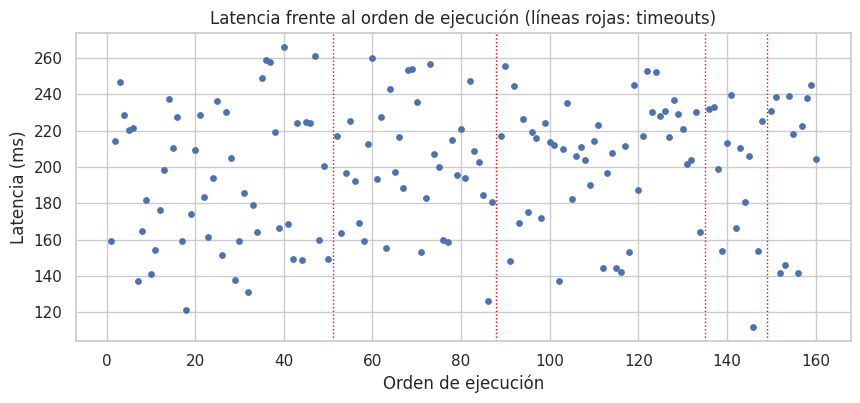

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Configuración estética para gráficos científicos
sns.set_theme(style="whitegrid")

# 1. Cargar los datos generados por el orquestador
df = pd.read_csv('experiment_results_final.csv')
factores = ['Codec', 'Cache', 'Protocolo']
# Ordenamos las filas por los factores para que tablas y gráficos muestren los niveles en el mismo orden
df = df.sort_values(factores + ['orden']).reset_index(drop=True)
print(f"{len(df)} ejecuciones registradas\n")

# 2. Estado de las ejecuciones y valores perdidos
print("Estado de las ejecuciones:")
print(df['estado'].value_counts())
print("\nValores perdidos en la respuesta:", df['Latencia_ms'].isna().sum())

# 3. Balance: réplicas previstas y válidas en cada configuración
balance = df.groupby(factores).agg(previstas=('estado', 'size'),
                                   validas=('Latencia_ms', 'count'))
print("\nRéplicas por configuración:")
print(balance)

# 4. Respuesta frente al orden de ejecución
validas = df['estado'] == 'ok'
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(df.loc[validas, 'orden'], df.loc[validas, 'Latencia_ms'], s=15)
for x in df.loc[~validas, 'orden']:
    ax.axvline(x, color='red', linestyle=':', linewidth=1)
ax.set_xlabel('Orden de ejecución')
ax.set_ylabel('Latencia (ms)')
ax.set_title('Latencia frente al orden de ejecución (líneas rojas: timeouts)')
plt.show()

**Paso 2:** Descriptivos numéricos: calculamos una "Tabla de Resumen" por configuración. Es importante para ver los números exactos detrás de los gráficos.

In [ ]:
# Tabla de descriptivos por configuración
# Agrupamos por todos los factores para ver la media y la desviación de cada combinación
summary_table = (df.groupby(factores)['Latencia_ms']
                   .agg(['mean', 'std', 'count', 'min', 'max']).round(2))

print("--- Tabla de Rendimiento Promedio (Latencia) ---")
print(summary_table)

--- Tabla de Rendimiento Promedio (Latencia) ---
                         mean    std  count     min     max
Codec Cache Protocolo                                      
H.264 Off   HTTP/2     207.44   9.81     19  192.11  227.34
            HTTP/3     179.79   8.14     19  166.50  193.90
      On    HTTP/2     160.41   8.56     20  148.45  185.48
            HTTP/3     141.26  11.92     20  112.00  159.71
H.265 Off   HTTP/2     229.50  11.90     20  210.21  253.34
            HTTP/3     209.06  10.26     20  190.11  230.79
      On    HTTP/2     245.95  14.63     20  216.28  266.19
            HTTP/3     226.36  11.04     18  199.75  249.20


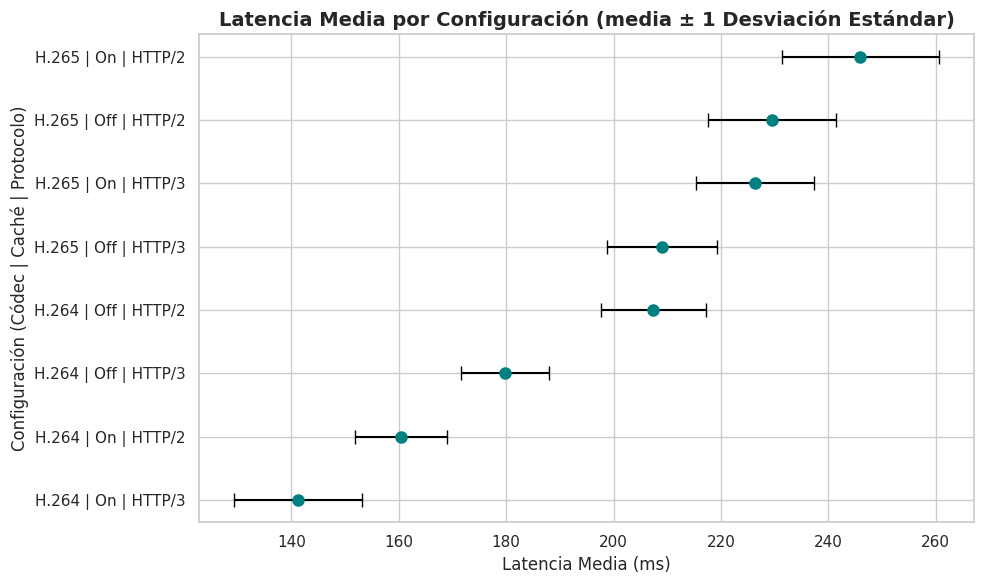

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Resetear el índice del summary_table para poder usar las columnas en seaborn
df_plot = summary_table.reset_index()

# Crear una columna combinada para identificar cada configuración de forma clara en el eje Y
df_plot['Configuracion'] = df_plot['Codec'] + ' | ' + df_plot['Cache'] + ' | ' + df_plot['Protocolo']

# Ordenar por latencia media para facilitar la lectura
df_plot = df_plot.sort_values(by='mean').reset_index(drop=True)

plt.figure(figsize=(10, 6))

# Pintar los puntos con la media y las barras de error correspondientes a +- 1 desviación estándar (std)
plt.errorbar(
    x=df_plot['mean'],
    y=df_plot['Configuracion'],
    xerr=df_plot['std'],
    fmt='o',            # 'o' pinta un punto circular
    color='teal',       # color del punto y de la línea de error
    ecolor='black',     # color de las barras de error
    elinewidth=1.5,     # grosor de la barra de error
    capsize=5,          # tamaño de los topes de las barras
    ms=8                # tamaño del marcador del punto
)

plt.title('Latencia Media por Configuración (media ± 1 Desviación Estándar)', fontsize=14, fontweight='bold')
plt.xlabel('Latencia Media (ms)', fontsize=12)
plt.ylabel('Configuración (Códec | Caché | Protocolo)', fontsize=12)
plt.tight_layout()
plt.show()

**Paso 3:** Análisis Univariante con la respuesta. Antes de comparar, miramos la forma de los datos. Que no veamos una campana de Gauss no significa que no podamos asumir normalidad (ej. multimodalidad); la asimetría sí puede dar indicios. Nos da información sobre posibles outliers a descartar/diferenciar/revisar.

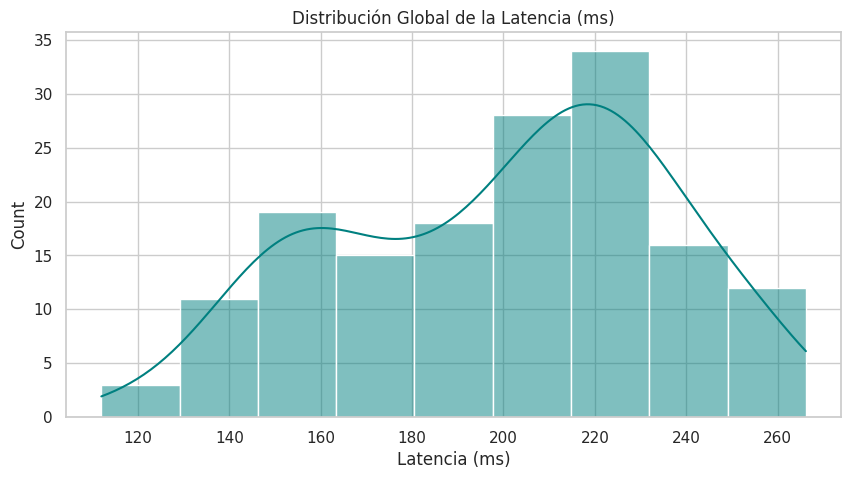

In [ ]:
plt.figure(figsize=(10, 5))
# Histograma con estimación de densidad de kernel (KDE)
sns.histplot(data=df, x='Latencia_ms', kde=True, color='teal')
plt.title('Distribución Global de la Latencia (ms)')
plt.xlabel('Latencia (ms)')
plt.show()

**Paso 4:** Análisis Bivariante con la respuesta: sirve para identificar efectos principales. ¿Qué factor individual es el más importante? Usamos Boxplots para comparar la mediana y la dispersión.

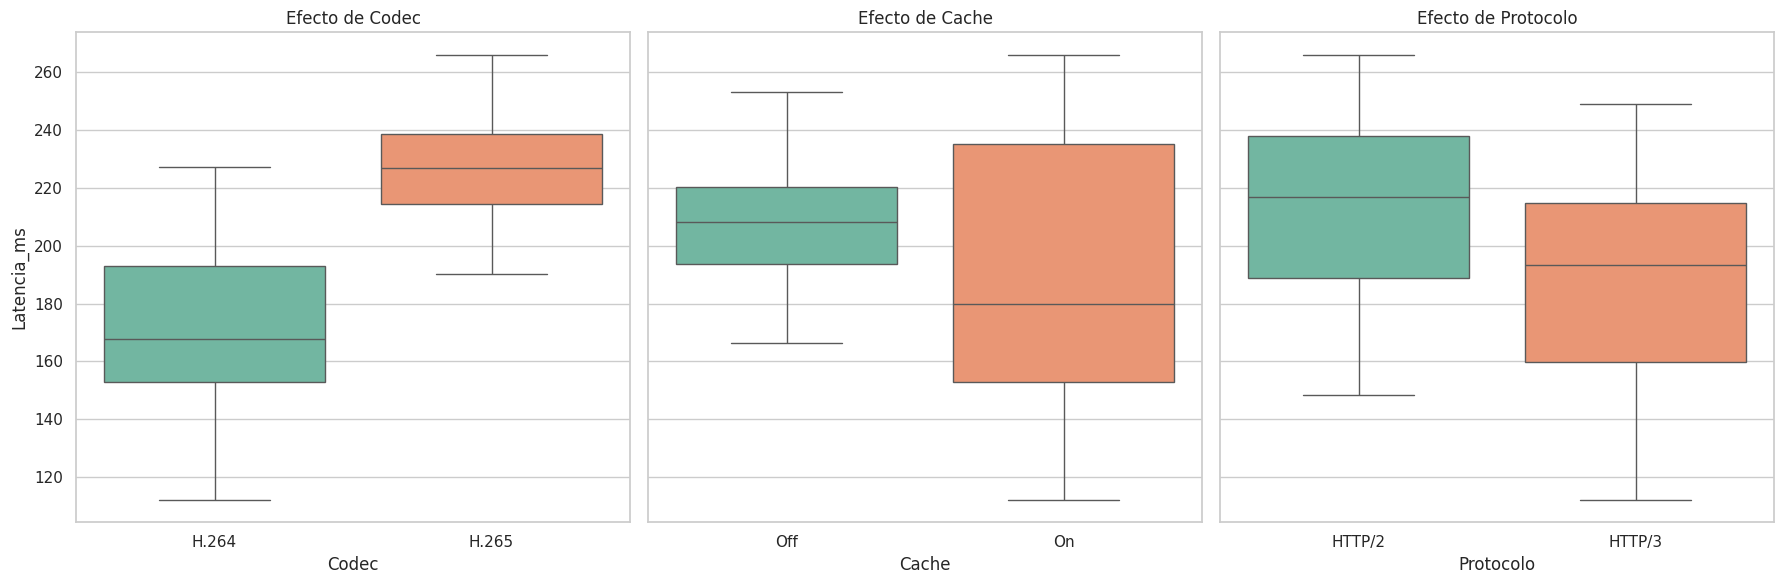

In [ ]:
# Un boxplot por factor para ver cada efecto principal por separado
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for ax, factor in zip(axes, factores):
    sns.boxplot(ax=ax, x=factor, y='Latencia_ms', data=df, hue=factor, palette='Set2', legend=False)
    ax.set_title(f'Efecto de {factor}')
plt.tight_layout()
plt.show()

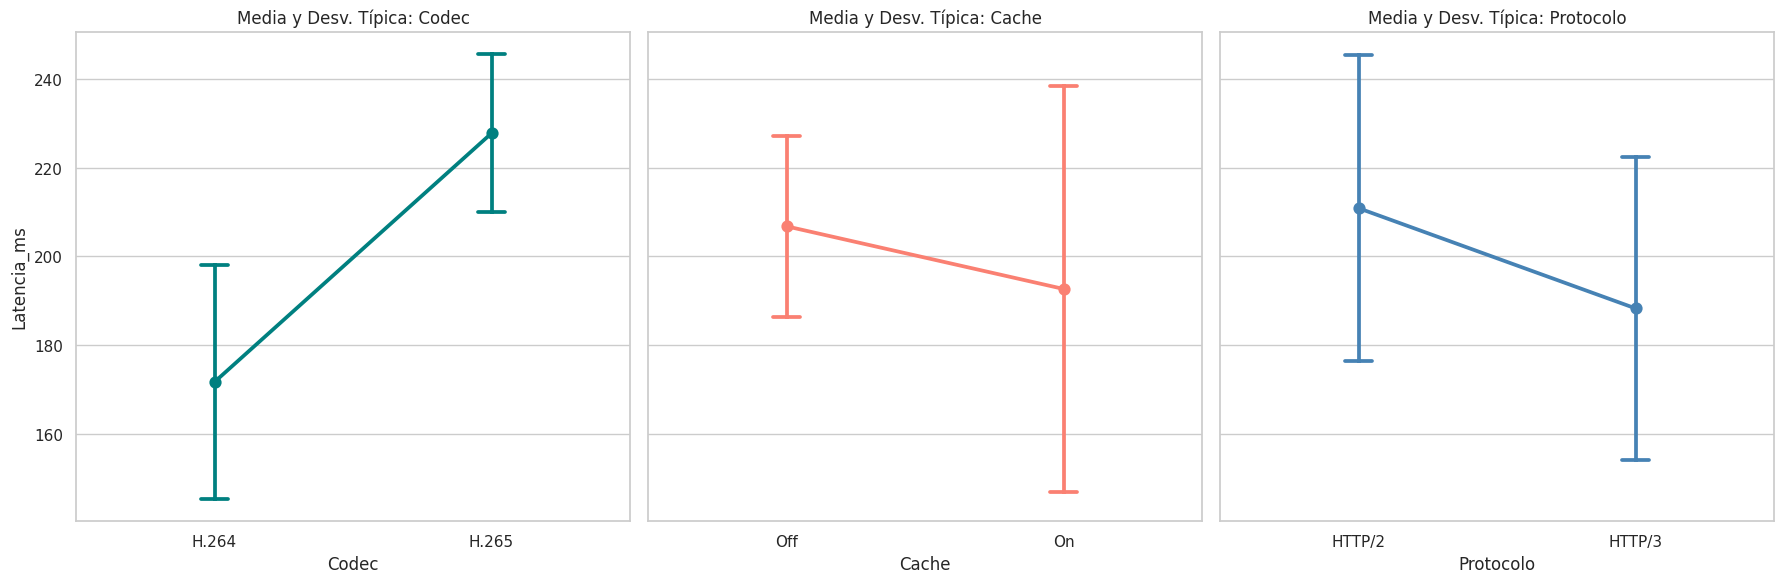

In [ ]:
# Gráficos de líneas con barras de error (media y desviación típica)
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for ax, factor, color in zip(axes, factores, ['teal', 'salmon', 'steelblue']):
    sns.pointplot(ax=ax, x=factor, y='Latencia_ms', data=df,
                  errorbar='sd',    # desviación típica
                  capsize=0.1,      # tamaño de los topes de la barra
                  color=color)
    ax.set_title(f'Media y Desv. Típica: {factor}')
plt.tight_layout()
plt.show()

**Paso 5:** Análisis de Interacciones: gráficos trivariantes con la respuesta, para identificar interacciones de orden 2, cuatrivariantes con la respuesta para interacciones de orden 3 (más difíciles de ver). ¿El Caché funciona igual para ambos Códecs? Usamos `catplot` tipo `point` o `box` con `hue`.

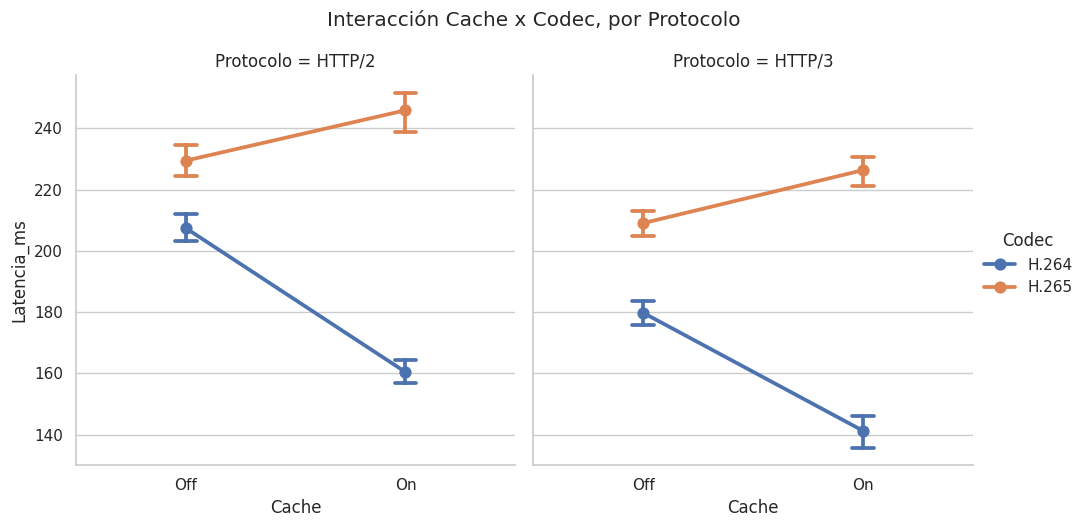

In [ ]:
def grafico_interaccion(datos, respuesta, x, color, columnas=None):
    """Medias (con IC del 95 %) de `respuesta` frente a `x`, con una línea por nivel
    de `color` y, si se indica, un panel por nivel de `columnas`."""
    g = sns.catplot(data=datos, x=x, y=respuesta, hue=color, col=columnas,
                    kind="point", capsize=.1, height=5, aspect=1)
    titulo = f'Interacción {x} x {color}' + (f', por {columnas}' if columnas else '')
    g.figure.suptitle(titulo, y=1.05)
    plt.show()

# ¿El efecto de la caché depende del códec? Un panel por protocolo
grafico_interaccion(df, 'Latencia_ms', x='Cache', color='Codec', columnas='Protocolo')

# El mismo diseño admite otras lecturas cambiando los papeles de los factores:
# grafico_interaccion(df, 'Latencia_ms', x='Protocolo', color='Cache', columnas='Codec')

**Lectura del Gráfico de Puntos**

* Líneas Paralelas: No hay interacción. Los factores son independientes (el beneficio del Caché es el mismo uses el protocolo que uses).

* Líneas que se cruzan o con distinta pendiente: ¡Existe Interacción! (Ejemplo: El Caché reduce mucho la latencia en HTTP/2, pero no hace nada en HTTP/3). Esta es la información más valiosa para un ingeniero.

En nuestros datos las líneas de los dos códecs se cruzan: activar la caché reduce la latencia con `H.264` y la aumenta con `H.265`. El efecto global de la caché que veíamos en el Paso 4 mezclaba dos efectos de signo contrario. El dibujo se repite en los dos paneles: el protocolo desplaza la latencia, pero no cambia el efecto de la caché ni el del códec.

**Paso 6:** Interacciones con heatmaps.

¿Cuál es la configuración ganadora?



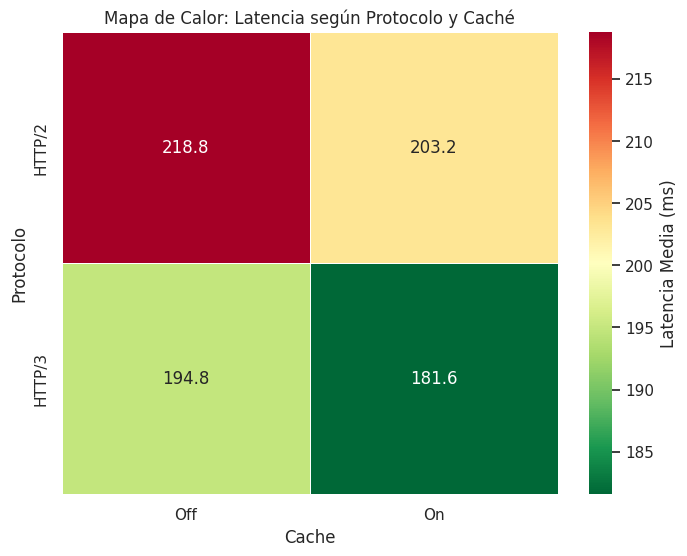

In [ ]:
# Definimos una paleta divergente:
# Rojo = Latencia Alta (Malo), Verde = Latencia Baja (Bueno).
# 'RdYlGn_r' invierte el orden estándar (donde verde suele ser valores altos).
cmap_latencia = "RdYlGn_r"

# 1. Crear tabla pivote: Filas=Protocolo, Columnas=Caché, Valores=Latencia Media
pivot_latency = df.pivot_table(index='Protocolo', columns='Cache', values='Latencia_ms', aggfunc='mean')

plt.figure(figsize=(8, 6))
sns.heatmap(
    pivot_latency,
    annot=True,         # Escribir el valor en la celda
    fmt=".1f",          # Formato con 1 decimal
    cmap=cmap_latencia, # Colores semafóricos
    linewidths=.5,      # Líneas blancas entre celdas para limpieza
    cbar_kws={'label': 'Latencia Media (ms)'}
)
plt.title('Mapa de Calor: Latencia según Protocolo y Caché')
plt.show()

Se aprecia que HTTP/3 supera consistentemente en latencia a HTTP/2, tanto con caché desactivada como activada. Activar la caché parece reducir la latencia media en ambos protocolos. Y al ser los cambios parecidos, parece que protocolo y caché actúan de forma independiente.

**Paso 7:**  Heatmaps Avanzados (Faceted) ¿Y si el mapa cambia según el Códec? Podemos separar los heatmaps.

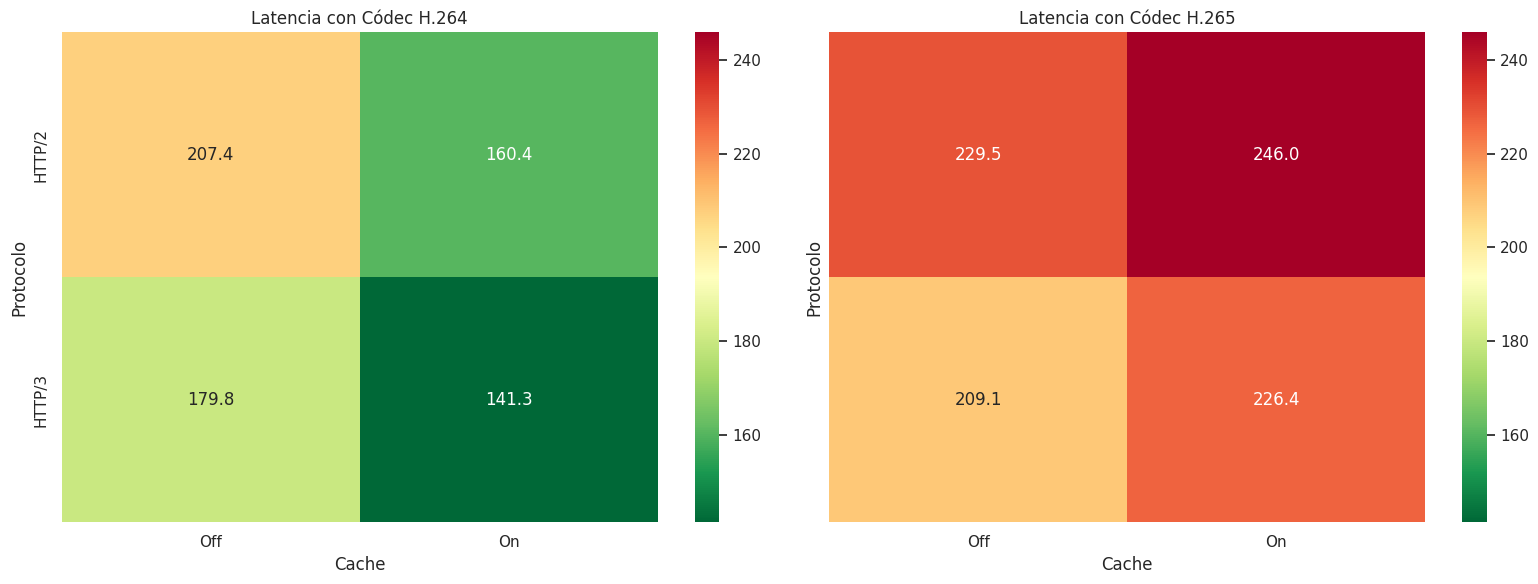

In [ ]:
# Un mapa de calor por nivel del tercer factor, con la misma escala de color en todos
medias = df.groupby(factores)['Latencia_ms'].mean()
vmin, vmax = medias.min(), medias.max()
niveles = sorted(df['Codec'].unique())

fig, ax = plt.subplots(1, len(niveles), figsize=(8 * len(niveles), 6), sharey=True)
for a, nivel in zip(ax, niveles):
    pivote = df[df['Codec'] == nivel].pivot_table(index='Protocolo', columns='Cache',
                                                  values='Latencia_ms')
    sns.heatmap(pivote, annot=True, fmt=".1f", cmap=cmap_latencia, ax=a, vmin=vmin, vmax=vmax)
    a.set_title(f'Latencia con Códec {nivel}')
plt.tight_layout()
plt.show()

Al estratificar por códec, la cocnlusión sobre la caché se invierte por completo según el códec utilizado, lo que revela una interacción fuerte entre caché y códec (y una interacción de tres vías).

- Con códec H.264 activar la caché reduce drásticamente la latencia en los dos protocolos.

- Con códec H.265 activar la caché empeora la latencia en ambos protocolos (sube).

**Paso 8:** Gráficos habituales en la evaluación de algoritmos. Cambiamos de datos: dos algoritmos ejecutados sobre las mismas 12 instancias, de dificultad muy distinta, con 10 semillas cada uno. Los datos son simulados y los nombres genéricos; el código sirve para cualquier tabla con las columnas `instancia`, `semilla`, `algoritmo` y una respuesta.

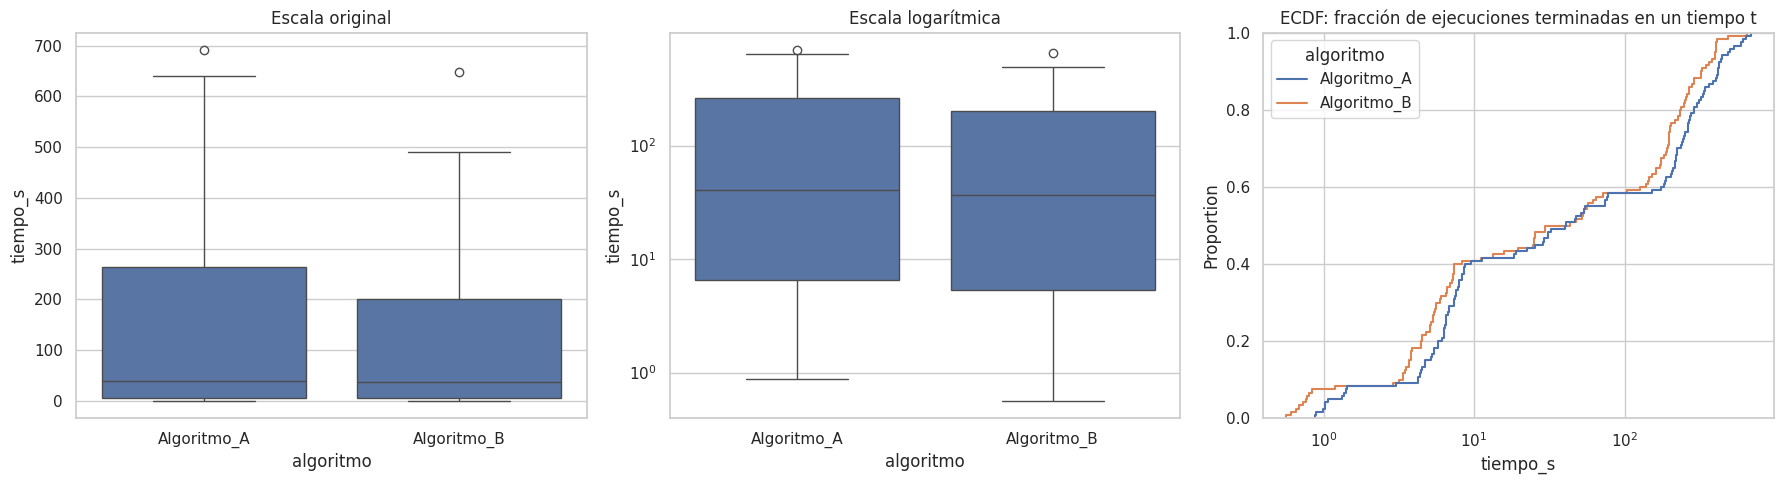

In [ ]:
# Datos simulados: 2 algoritmos x 12 instancias x 10 semillas
rng = np.random.default_rng(7)
instancias = [f'I{i:02d}' for i in range(1, 13)]
dificultad = dict(zip(instancias, np.exp(rng.uniform(np.log(1), np.log(1000), 12))))   # de 1 a 1000 s

filas = []
for inst in instancias:
    for semilla in range(10):
        for alg, factor in [('Algoritmo_A', 1.00), ('Algoritmo_B', 0.80)]:    # B tarda un 20 % menos
            filas.append({'instancia': inst, 'semilla': semilla, 'algoritmo': alg,
                          'tiempo_s': dificultad[inst] * factor * rng.lognormal(0, 0.25)})
df_alg = pd.DataFrame(filas)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df_alg, x='algoritmo', y='tiempo_s', ax=axes[0])
axes[0].set_title('Escala original')
sns.boxplot(data=df_alg, x='algoritmo', y='tiempo_s', ax=axes[1])
axes[1].set_yscale('log')
axes[1].set_title('Escala logarítmica')
sns.ecdfplot(data=df_alg, x='tiempo_s', hue='algoritmo', log_scale=True, ax=axes[2])
axes[2].set_title('ECDF: fracción de ejecuciones terminadas en un tiempo t')
plt.tight_layout()
plt.show()

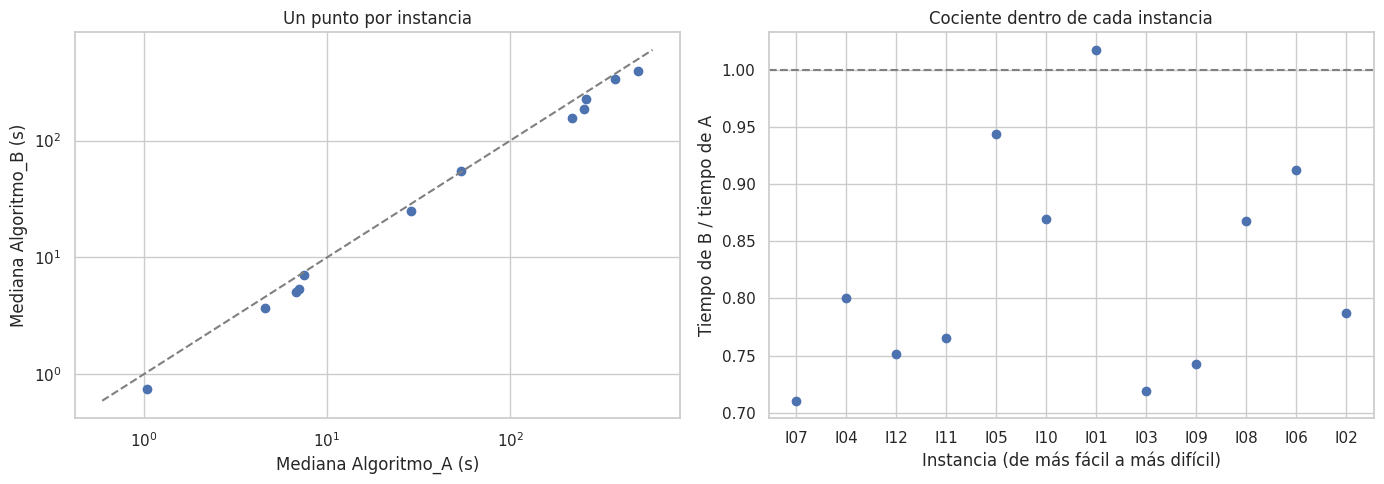

B es más rápido en 11 de 12 instancias; cociente mediano = 0.79


In [ ]:
# Comparación pareada: mediana de cada algoritmo en cada instancia
medianas = df_alg.pivot_table(index='instancia', columns='algoritmo',
                              values='tiempo_s', aggfunc='median')
medianas['cociente_B_A'] = medianas['Algoritmo_B'] / medianas['Algoritmo_A']
medianas = medianas.sort_values('Algoritmo_A')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Izquierda: A frente a B, un punto por instancia. Bajo la diagonal, B es más rápido.
axes[0].scatter(medianas['Algoritmo_A'], medianas['Algoritmo_B'])
limites = [medianas[['Algoritmo_A', 'Algoritmo_B']].min().min() * 0.8,
           medianas[['Algoritmo_A', 'Algoritmo_B']].max().max() * 1.2]
axes[0].plot(limites, limites, color='gray', linestyle='--')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('Mediana Algoritmo_A (s)'); axes[0].set_ylabel('Mediana Algoritmo_B (s)')
axes[0].set_title('Un punto por instancia')

# Derecha: cociente B/A en cada instancia, ordenadas por dificultad
axes[1].scatter(medianas.index, medianas['cociente_B_A'])
axes[1].axhline(1, color='gray', linestyle='--')
axes[1].set_ylabel('Tiempo de B / tiempo de A')
axes[1].set_xlabel('Instancia (de más fácil a más difícil)')
axes[1].set_title('Cociente dentro de cada instancia')
plt.tight_layout()
plt.show()

print(f"B es más rápido en {(medianas['cociente_B_A'] < 1).sum()} de {len(medianas)} instancias; "
      f"cociente mediano = {medianas['cociente_B_A'].median():.2f}")

**Lectura.** En los boxplots conjuntos y en la ECDF los dos algoritmos casi se superponen: la diferencia entre instancias, de tres órdenes de magnitud, tapa la diferencia entre algoritmos. Al comparar dentro de cada instancia, la ventaja de B aparece con claridad. Es el efecto del bloqueo por instancia (Unidad 1, apartado 5), visto en un gráfico.

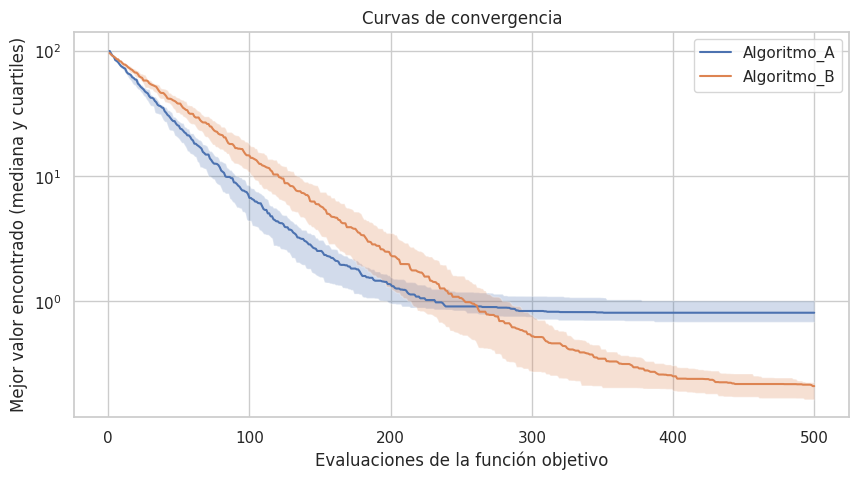

In [ ]:
# Curvas de convergencia simuladas: mejor valor encontrado frente a evaluaciones (20 semillas)
rng = np.random.default_rng(11)
evaluaciones = np.arange(1, 501)

def curvas(ritmo, suelo, n_semillas=20):
    """Cada ejecución desciende hacia un suelo propio; se guarda el mejor valor hasta el momento."""
    resultado = []
    for _ in range(n_semillas):
        valor = suelo * rng.lognormal(0, 0.3) + 100 * np.exp(-ritmo * rng.lognormal(0, 0.2) * evaluaciones)
        valor = valor * rng.lognormal(0, 0.05, len(evaluaciones))
        resultado.append(np.minimum.accumulate(valor))
    return np.array(resultado)

convergencia = {'Algoritmo_A': curvas(ritmo=0.03, suelo=1.0),    # rápido, pero se estanca antes
                'Algoritmo_B': curvas(ritmo=0.02, suelo=0.2)}    # lento, pero llega más lejos

fig, ax = plt.subplots(figsize=(10, 5))
for nombre, c in convergencia.items():
    q1, mediana, q3 = np.percentile(c, [25, 50, 75], axis=0)
    ax.plot(evaluaciones, mediana, label=nombre)
    ax.fill_between(evaluaciones, q1, q3, alpha=0.25)
ax.set_yscale('log')
ax.set_xlabel('Evaluaciones de la función objetivo')
ax.set_ylabel('Mejor valor encontrado (mediana y cuartiles)')
ax.set_title('Curvas de convergencia')
ax.legend()
plt.show()

**Lectura.** Las curvas se cruzan: con un presupuesto pequeño gana A y con uno grande gana B. Una comparación a un único presupuesto habría contado solo la mitad de la historia.

## 🟢 **4. Diseños de Superficie de Respuesta**

### 🚀 **Reto**

**La Búsqueda del Óptimo (RSM)**

Estás entrenando un modelo de Deep Learning (un Transformer costoso) que tarda 12 horas por entrenamiento. Has realizado un diseño factorial previo ($2^3$) y luego hiciste un experimento más justo en el medio de todo para ver qué pasaba, y has notado algo interesante: el rendimiento en el "punto central" fue mejor que en todas las esquinas.

Esto significa que hay **curvatura**. El óptimo está "dentro" de tu región actual, no en los bordes. Un modelo lineal ya no te sirve; necesitas ajustar una parábola para encontrar el pico exacto.

Crees que el óptimo se encuentra dentro de estos rangos:
- Learning Rate: Entre 0.001 y 0.01.
- Batch Size: Entre 32 y 128.
- Dropout: Entre 0.1 y 0.5.

¿Cómo puedes encontrarlo?

###  🧰 **Herramientas**

#### **Diseños de Superficie de Respuesta (RSM,** Response Surface Methodology)

Son útiles cuando el objetivo pasa de “descubrir qué factores importan” (screening) a “afinar y optimizar” el rendimiento. Los diseños factoriales ($2^k$) que hemos visto hasta ahora son excelentes para discernir efectos de un modo simple, pero tienen un defecto: asumen linealidad. Sin embargo, en la realidad (y en computación), los óptimos suelen ser picos de una montaña (curvas). Si tu modelo es plano, nunca podrás detectar un pico.

La RSM se basa en aproximar esa "montaña" desconocida mediante un polinomio de segundo grado (Modelo Cuadrático):

$$ Y = \beta_0 + \sum_i \beta_i x_i + \sum_i \beta_{ii} x_i^2 + \sum_{i<j}\sum_j \beta_{ij}x_ix_j + \epsilon$$

donde:
- $\beta_i x_i$: Efecto lineal (pendiente).
- $\beta_{ii} x_i^2$: Efecto cuadrático (Curvatura). Esto es lo que permite encontrar máximos o mínimos.
- $\beta_{ij} x_i x_j$: Interacción (torsión de la superficie).

Para estimar los términos al cuadrado ($\beta_{ii}$), necesitamos al menos 3 niveles por factor (bajo, medio, alto), si bien lo recomendable son 5. El diseño más robusto y utilizado es el **Diseño Central Compuesto (CCD)**, *Central Composite Design*, si bien también es habitual el **Diseño de Box-Behnken (BBD)**, que requiere al menos 3 factores y es muy eficiente para problemas con 3-4 variables, y evita puntos donde todos los factores están al máximo o mínimo a la vez. Box-Behnken es recomendable cuando no puedes salirte de los límites, mientras que CCD te permite probar valores fuera de tus rangos normales.

Un CCD se construye sumando tres partes:
- La Parte Factorial ($2^k$): Los puntos de las esquinas del cubo (Niveles -1 y +1). Estiman los efectos lineales e interacciones.
- Puntos Centrales ($n_c$): Puntos repetidos en el centro (0,0). Estiman el error experimental puro y detectan si existe curvatura.
- Puntos Axiales o "Estrella" ($2k$): Puntos situados fuera de la caja factorial, a una distancia $\alpha$ del centro. Estos son los responsables de estimar con precisión los coeficientes cuadráticos.

Esto genera 5 valores distintos para cada factor:
- $-\alpha$ (Punto estrella negativo, el más bajo de todos)
- $-1$ (Límite bajo factorial)
- $0$ (Centro)
- $+1$ (Límite alto factorial)
- $+\alpha$ (Punto estrella positivo, el más alto de todos)

**El concepto de Rotabilidad**:
A menudo verás que los puntos estrella están a una distancia $\alpha = 2^{k/4}$ (para k=2 factores, $\alpha = 1.414$). Esto se hace para que el diseño sea rotable: significa que la precisión de la predicción depende solo de la distancia al centro, sin importar la dirección.

La recomendación para plantear un diseño de superficie de respuesta, RSD, es seguir los siguientes pasos:

1. Tras un diseño de screening, se seleccionan los factores clave (2-3).

1. Se construye un CCD o BBD alrededor de un centro razonable del espacio.

1. Se configura el diseño, se ajusta un modelo cuadrático de superficie de respuesta, y se usa para localizar numéricamente el óptimo y dibujar  mapas de contorno y perfiles de respuesta que ayudan a recomendar rangos operativos robustos en lugar de un único punto frágil.


El diseño CCD puede ser de tres tipos, que se especifican al construir la matriz de diseño, y se detallan en la tabla a continuación:
|Tipo de CCD|Niveles|¿Cuándo usarlo?|
|--|--|--|
|CCC (Circumscribed)|5|El mejor matemáticamente. Úsalo si tu sistema permite valores extremos fuera del rango estándar.|
|CCI (Inscribed)|5|Cuando quieres rotabilidad (precisión circular) pero no puedes salirte de los límites extremos. |
|CCF (Face-Centered)|3|Cuando solo tienes 3 configuraciones posibles o es imposible exceder los límites operativos.|

<br>

La librería `pyDOE3` tiene una función específica para el diseño CCD llamada `ccdesign` y otra para el diseño Box-Behnken `bbdesign`. Se recomienda consultar la [documentación de pyDOE3](https://pydoe3.readthedocs.io/en/stable/rsm.html).

#### **Del cribado a la superficie: un flujo secuencial**

Para pasar de un factorial a un CCD no hace falta empezar de cero:

1. **Cribado** con un factorial $2^k$ (o fraccional) para quedarse con 2 o 3 factores.
2. **Puntos centrales** añadidos a ese factorial: si la respuesta en el centro se aleja de la media de las esquinas, hay curvatura.
3. **Ampliación**: se añaden solo los puntos estrella (y algún punto central más). Las ejecuciones del factorial se reutilizan y forman, junto a las nuevas, el CCD completo. Conviene tratar las dos tandas como **bloques** en el análisis, por si las condiciones cambiaron entre una y otra.

#### **Tres precauciones con parámetros de algoritmos**

- **Límites que no se pueden cruzar.** Una probabilidad no puede ser negativa ni un tamaño valer cero. Con un CCC los puntos estrella caen fuera del rango ($\pm\alpha$): comprueba los valores reales antes de ejecutar y, si alguno es imposible, usa CCI, CCF o Box-Behnken.
- **Factores enteros o en escala logarítmica.** Un factor entero (tamaño de lote, número de hilos) admite solo ciertos valores: redondea los niveles o elige un diseño de 3 niveles (CCF, Box-Behnken) cuyos niveles sean valores válidos. Los parámetros que varían en órdenes de magnitud se codifican sobre su logaritmo.
- **Réplicas en el centro.** En RSM no se suele replicar el diseño entero: las repeticiones del punto central estiman el error experimental. Si cada ejecución es cara, es preferible gastar el presupuesto en puntos centrales que en replicar todas las configuraciones. Si el algoritmo es barato y muy ruidoso, se puede replicar el diseño completo y trabajar con la media de cada configuración.


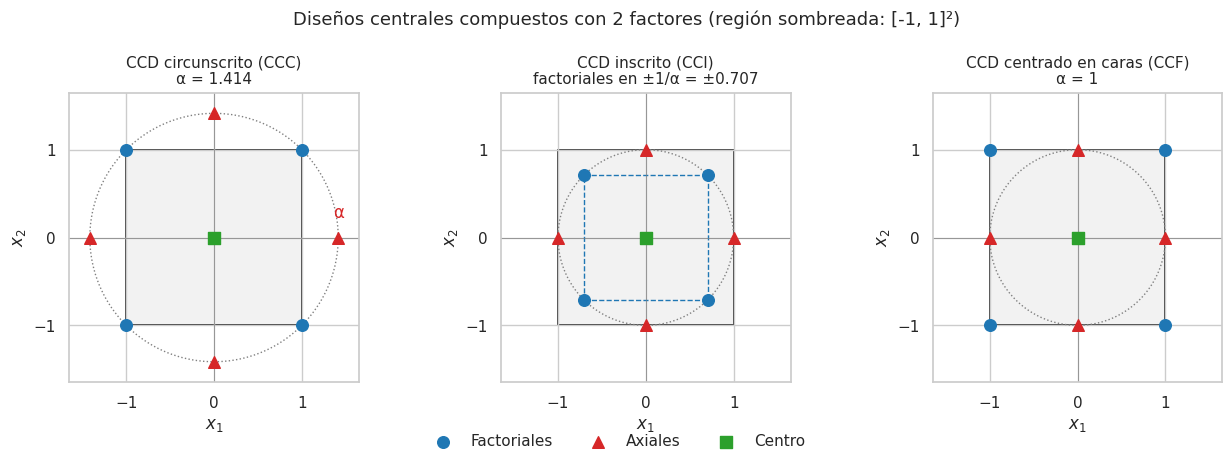

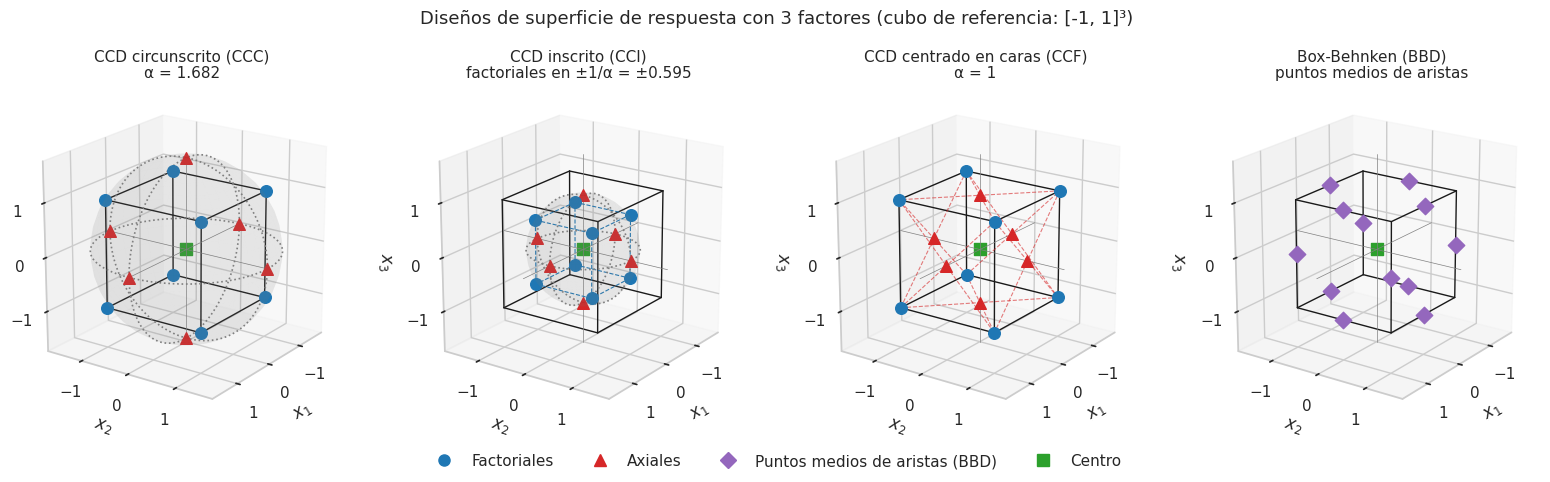

In [ ]:
# @title Ilustración de los Diseños de Superficie de Respuesta (RSD)
"""
Comparación visual de diseños de superficie de respuesta en unidades codificadas.
- Figura 1: CCD con 2 factores (circunscrito, inscrito, centrado en caras)
- Figura 2: CCD con 3 factores (las tres variantes) + Box-Behnken

Todos los paneles comparten la región de referencia [-1, 1]^k (cuadrado o cubo)
y los mismos límites de ejes, de modo que las diferencias de alcance sean visibles.
"""
import itertools
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Estilo común
# ---------------------------------------------------------------------------
COL = {"factorial": "#1f77b4", "axial": "#d62728", "centro": "#2ca02c", "bbd": "#9467bd"}
MS = 70  # tamaño de marcador


def alpha_rotable(k):
    """alpha para un CCD rotable: (2^k)^(1/4)."""
    return (2 ** k) ** 0.25


def ccd(k, tipo):
    """Devuelve (factoriales, axiales, centro) en unidades codificadas.
    tipo: 'CCC' (circunscrito), 'CCI' (inscrito), 'CCF' (centrado en caras)."""
    a = alpha_rotable(k)
    fact = np.array(list(itertools.product([-1, 1], repeat=k)), dtype=float)
    ax = np.vstack([s * np.eye(k)[i] for i in range(k) for s in (-1, 1)])
    if tipo == "CCC":
        ax = ax * a
    elif tipo == "CCI":
        fact = fact / a           # los vértices se encogen para que los axiales queden en ±1
    elif tipo == "CCF":
        pass                      # alpha = 1
    centro = np.zeros((1, k))
    return fact, ax, centro


def bbd3():
    """Box-Behnken para 3 factores: puntos medios de las 12 aristas + centro."""
    pts = []
    for i, j in itertools.combinations(range(3), 2):
        for a, b in itertools.product([-1, 1], repeat=2):
            p = np.zeros(3)
            p[i], p[j] = a, b
            pts.append(p)
    return np.array(pts), np.zeros((1, 3))


TITULOS = {
    "CCC": "CCD circunscrito (CCC)\nα = {a:.3f}",
    "CCI": "CCD inscrito (CCI)\nfactoriales en ±1/α = ±{f:.3f}",
    "CCF": "CCD centrado en caras (CCF)\nα = 1",
}

# ---------------------------------------------------------------------------
# Figura 1: 2 factores
# ---------------------------------------------------------------------------
k = 2
a2 = alpha_rotable(k)
lim = 1.65
fig, axs = plt.subplots(1, 3, figsize=(13, 4.6))
for axp, tipo in zip(axs, ["CCC", "CCI", "CCF"]):
    fact, axl, cen = ccd(k, tipo)
    # región de referencia [-1,1]^2
    axp.add_patch(plt.Rectangle((-1, -1), 2, 2, fill=True, fc="#f2f2f2",
                                ec="k", lw=1.2, zorder=0))
    # circunferencia de radio alpha (rotabilidad) como guía
    r = a2 if tipo == "CCC" else 1
    t = np.linspace(0, 2 * np.pi, 300)
    axp.plot(r * np.cos(t), r * np.sin(t), ls=":", c="grey", lw=1)
    # cuadrado de los factoriales en el CCI
    if tipo == "CCI":
        f = 1 / a2
        axp.add_patch(plt.Rectangle((-f, -f), 2 * f, 2 * f, fill=False,
                                    ec=COL["factorial"], ls="--", lw=1))
    axp.scatter(*fact.T, s=MS, c=COL["factorial"], label="Factoriales", zorder=3)
    axp.scatter(*axl.T, s=MS, c=COL["axial"], marker="^", label="Axiales", zorder=3)
    axp.scatter(*cen.T, s=MS, c=COL["centro"], marker="s", label="Centro", zorder=3)
    axp.axhline(0, c="grey", lw=0.5); axp.axvline(0, c="grey", lw=0.5)
    axp.set_xlim(-lim, lim); axp.set_ylim(-lim, lim)
    axp.set_aspect("equal")
    axp.set_xticks([-1, 0, 1]); axp.set_yticks([-1, 0, 1])
    if tipo == "CCC":  # rotular la distancia axial
        axp.annotate("α", (a2, 0), xytext=(a2, 0.22), ha="center", color=COL["axial"])
    axp.set_xlabel("$x_1$"); axp.set_ylabel("$x_2$")
    axp.set_title(TITULOS[tipo].format(a=a2, f=1 / a2), fontsize=11)
h2, l2 = axs[0].get_legend_handles_labels()
fig.legend(h2, l2, loc="lower center", ncol=3, frameon=False)
fig.suptitle("Diseños centrales compuestos con 2 factores (región sombreada: [-1, 1]²)", fontsize=13)
fig.subplots_adjust(left=0.05, right=0.98, top=0.80, bottom=0.17, wspace=0.25)
fig.savefig("ccd_2factores.png", dpi=200, bbox_inches="tight")

# ---------------------------------------------------------------------------
# Figura 2: 3 factores (CCC, CCI, CCF, BBD)
# ---------------------------------------------------------------------------
k = 3
a3 = alpha_rotable(k)
lim3 = 1.75


def dibujar_cubo(axp, h=1.0, **kw):
    for s, e in itertools.combinations(np.array(list(itertools.product([-h, h], repeat=3))), 2):
        if np.sum(np.abs(s - e)) == 2 * h:      # sólo aristas
            axp.plot3D(*zip(s, e), **kw)


def dibujar_circulos(axp, r, color="grey"):
    """Circunferencias de radio r en los tres planos coordenados y esfera translúcida."""
    t = np.linspace(0, 2 * np.pi, 200)
    c, s_, z = r * np.cos(t), r * np.sin(t), np.zeros_like(t)
    for xs, ys, zs in [(c, s_, z), (c, z, s_), (z, c, s_)]:
        axp.plot3D(xs, ys, zs, ls=":", c=color, lw=1.2)
    u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
    axp.plot_surface(r * np.cos(u) * np.sin(v), r * np.sin(u) * np.sin(v), r * np.cos(v),
                     color=color, alpha=0.08, linewidth=0, shade=False)


def dibujar_diagonales_caras(axp, h=1.0, **kw):
    """Dos diagonales en cada una de las 6 caras del cubo [-h, h]^3."""
    for i in range(3):
        j, l = [m for m in range(3) if m != i]
        for s in (-h, h):
            for d in ((-h, -h, h, h), (-h, h, h, -h)):
                p = np.zeros((2, 3))
                p[:, i] = s
                p[:, j] = d[0], d[2]
                p[:, l] = d[1], d[3]
                axp.plot3D(*p.T, **kw)


def preparar_eje(axp, titulo):
    dibujar_cubo(axp, 1.0, c="k", lw=1)
    for i in range(3):  # ejes por el centro
        p = np.zeros((2, 3)); p[:, i] = [-lim3, lim3]
        axp.plot3D(*p.T, c="grey", lw=0.5)
    axp.set_xlim(-lim3, lim3); axp.set_ylim(-lim3, lim3); axp.set_zlim(-lim3, lim3)
    axp.set_box_aspect((1, 1, 1))
    ticks = [-1, 0, 1]
    axp.set_xticks(ticks); axp.set_yticks(ticks); axp.set_zticks(ticks)
    axp.set_xlabel("$x_1$"); axp.set_ylabel("$x_2$"); axp.set_zlabel("$x_3$")
    axp.set_title(titulo, fontsize=11)
    axp.view_init(elev=20, azim=35)


fig = plt.figure(figsize=(16, 4.8))
for n, tipo in enumerate(["CCC", "CCI", "CCF"], start=1):
    axp = fig.add_subplot(1, 4, n, projection="3d")
    fact, axl, cen = ccd(k, tipo)
    preparar_eje(axp, TITULOS[tipo].format(a=a3, f=1 / a3))
    if tipo == "CCI":
        dibujar_cubo(axp, 1 / a3, c=COL["factorial"], lw=0.8, ls="--")
    if tipo == "CCF":
        dibujar_diagonales_caras(axp, 1.0, c=COL["axial"], lw=0.8, ls="--", alpha=0.6)
    if tipo in ("CCC", "CCI"):
        dibujar_circulos(axp, a3 if tipo == "CCC" else 1.0)
    axp.scatter(*fact.T, s=MS, c=COL["factorial"], depthshade=False, label="Factoriales")
    axp.scatter(*axl.T, s=MS, c=COL["axial"], marker="^", depthshade=False, label="Axiales")
    axp.scatter(*cen.T, s=MS, c=COL["centro"], marker="s", depthshade=False, label="Centro")

axp = fig.add_subplot(1, 4, 4, projection="3d")
pts, cen = bbd3()
preparar_eje(axp, "Box-Behnken (BBD)\npuntos medios de aristas")
axp.scatter(*pts.T, s=MS, c=COL["bbd"], marker="D", depthshade=False, label="Aristas (BBD)")
axp.scatter(*cen.T, s=MS, c=COL["centro"], marker="s", depthshade=False)

h = [plt.Line2D([], [], ls="", marker=m, c=c, ms=8, label=l) for m, c, l in
     [("o", COL["factorial"], "Factoriales"), ("^", COL["axial"], "Axiales"),
      ("D", COL["bbd"], "Puntos medios de aristas (BBD)"), ("s", COL["centro"], "Centro")]]
fig.legend(handles=h, loc="lower center", ncol=4, frameon=False)
fig.suptitle("Diseños de superficie de respuesta con 3 factores (cubo de referencia: [-1, 1]³)", fontsize=13)
fig.subplots_adjust(left=0.01, right=0.99, top=0.82, bottom=0.12, wspace=0.05)
fig.savefig("ccd_bbd_3factores.png", dpi=200, bbox_inches="tight")
plt.show()

### 📚 **Referencias**

* **Myers, R. H., Montgomery, D. C., & Anderson-Cook, C. M.** (2016). Response surface methodology: Process and product optimization using designed experiments (4.ª ed.). John Wiley & Sons. ISBN 978-1-118-91601-8.

  💎 **Interés:** Es el estándar mundial sobre el tema. Mientras que el libro general de Montgomery (que ya tienes) dedica un capítulo a esto, este libro  dedica 700 páginas exclusivamente a la optimización. Es imprescindible si tu tesis implica encontrar el punto exacto de máximo rendimiento (tuning fino) y necesitas entender a fondo la geometría de los diseños Centrales Compuestos (CCD) y Box-Behnken.

### 🔑 **Solución**

Generamos con `pyDOE3` un Diseño Central Compuesto (CCD) para los tres factores. Antes de elegir el tipo de CCD hay que mirar qué valores reales produce cada uno, porque aquí los límites importan:

- **Learning Rate** (0.001 a 0.01): varía en un orden de magnitud; lo codificamos sobre su logaritmo.
- **Batch Size** (32 a 128): es entero y suele ser potencia de 2; lo codificamos sobre $\log_2$, de modo que los niveles $-1$, $0$ y $+1$ son 32, 64 y 128.
- **Dropout** (0.1 a 0.5): escala lineal; no puede ser negativo.

La librería devuelve la matriz de diseño en unidades codificadas, que hay que convertir a unidades reales. Para tu problema, basta con cambiar el diccionario `rangos`.

In [ ]:
from pyDOE3 import ccdesign

# Rangos de interés: (mínimo, máximo, escala)
rangos = {
    'Learning_Rate': (0.001, 0.01, 'log10'),
    'Batch_Size':    (32, 128, 'log2'),
    'Dropout':       (0.1, 0.5, 'lineal'),
}

def codificado_a_real(codificado, rangos):
    """Convierte un diseño codificado (-1 = mínimo, +1 = máximo) a unidades reales."""
    real = pd.DataFrame(index=codificado.index)
    for col, (nombre, (minimo, maximo, escala)) in zip(codificado.columns, rangos.items()):
        if escala == 'lineal':
            a, b = minimo, maximo
        else:
            base = 10 if escala == 'log10' else 2
            a, b = np.log(minimo) / np.log(base), np.log(maximo) / np.log(base)
        valor = (a + b) / 2 + codificado[col] * (b - a) / 2
        real[nombre] = valor if escala == 'lineal' else base ** valor
    return real

# Tipos de CCD:
# 'ccc': circunscrito. Los puntos estrella salen del rango (5 niveles).
# 'cci': inscrito. Todo el diseño se encoge para caber en el rango (5 niveles).
# 'ccf': centrado en las caras. Los puntos estrella están en el límite del rango (3 niveles).
for tipo in ['ccc', 'cci', 'ccf']:
    # alpha='r': distancia de los puntos estrella que hace el diseño rotable
    cod = pd.DataFrame(ccdesign(3, center=(2, 2), alpha='r', face=tipo), columns=['x1', 'x2', 'x3'])
    real = codificado_a_real(cod, rangos)
    print(f"\n--- CCD tipo '{tipo}': {len(cod)} ejecuciones ---")
    print("Niveles codificados:", np.round(np.sort(cod['x1'].unique()), 3))
    for nombre in rangos:
        print(f"  {nombre:14s}", np.round(np.sort(real[nombre].unique()), 4))


--- CCD tipo 'ccc': 18 ejecuciones ---
Niveles codificados: [-1.682 -1.     0.     1.     1.682]
  Learning_Rate  [0.0005 0.001  0.0032 0.01   0.0219]
  Batch_Size     [ 19.9485  32.      64.     128.     205.3289]
  Dropout        [-0.0364  0.1     0.3     0.5     0.6364]

--- CCD tipo 'cci': 18 ejecuciones ---
Niveles codificados: [-1.    -0.595  0.     0.595  1.   ]
  Learning_Rate  [0.001  0.0016 0.0032 0.0063 0.01  ]
  Batch_Size     [ 32.      42.3825  64.      96.6437 128.    ]
  Dropout        [0.1    0.1811 0.3    0.4189 0.5   ]

--- CCD tipo 'ccf': 18 ejecuciones ---
Niveles codificados: [-1.  0.  1.]
  Learning_Rate  [0.001  0.0032 0.01  ]
  Batch_Size     [ 32.  64. 128.]
  Dropout        [0.1 0.3 0.5]


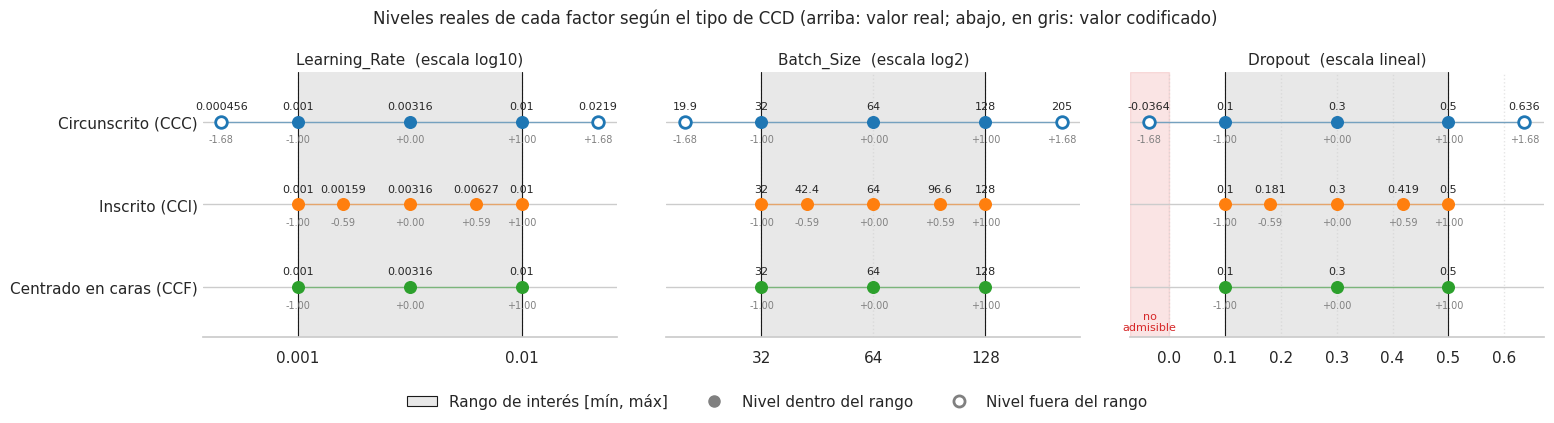

In [ ]:
# @title Ilustración diseños CCD
"""
Niveles reales que proporcionan los CCD circunscrito, inscrito y centrado en caras.
Un panel por factor: cada fila es un diseño, cada punto un nivel distinto.
La banda sombreada es el rango de interés [mínimo, máximo] definido en `rangos`.
Los factores en escala log se dibujan con eje logarítmico (en esa escala el diseño es simétrico).
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pyDOE3 import ccdesign

# Rangos de interés: (mínimo, máximo, escala)
rangos = {
    'Learning_Rate': (0.001, 0.01, 'log10'),
    'Batch_Size':    (32, 128, 'log2'),
    'Dropout':       (0.1, 0.5, 'lineal'),
}


def codificado_a_real(codificado, rangos):
    """Convierte un diseño codificado (-1 = mínimo, +1 = máximo) a unidades reales."""
    real = pd.DataFrame(index=codificado.index)
    for col, (nombre, (minimo, maximo, escala)) in zip(codificado.columns, rangos.items()):
        if escala == 'lineal':
            a, b = minimo, maximo
        else:
            base = 10 if escala == 'log10' else 2
            a, b = np.log(minimo) / np.log(base), np.log(maximo) / np.log(base)
        valor = (a + b) / 2 + codificado[col] * (b - a) / 2
        real[nombre] = valor if escala == 'lineal' else base ** valor
    return real


# ---------------------------------------------------------------------------
# Generar los tres diseños
# ---------------------------------------------------------------------------
TIPOS = {'ccc': 'Circunscrito (CCC)', 'cci': 'Inscrito (CCI)', 'ccf': 'Centrado en caras (CCF)'}
k = len(rangos)
disenos = {}
for tipo in TIPOS:
    cod = pd.DataFrame(ccdesign(k, center=(2, 2), alpha='r', face=tipo),
                       columns=[f'x{i + 1}' for i in range(k)])
    disenos[tipo] = (cod, codificado_a_real(cod, rangos))

# ---------------------------------------------------------------------------
# Gráfico
# ---------------------------------------------------------------------------
COLORES = {'ccc': '#1f77b4', 'cci': '#ff7f0e', 'ccf': '#2ca02c'}
fig, axs = plt.subplots(1, k, figsize=(5.2 * k, 4.2))
filas = list(TIPOS)[::-1]  # CCC arriba

for ax, (nombre, (minimo, maximo, escala)) in zip(axs, rangos.items()):
    ax.axvspan(minimo, maximo, color='#e8e8e8', zorder=0, label='Rango de interés')
    ax.axvline(minimo, c='k', lw=0.8); ax.axvline(maximo, c='k', lw=0.8)
    for y, tipo in enumerate(filas):
        cod, real = disenos[tipo]
        niveles = np.sort(real[nombre].unique())
        cod_niv = np.sort(cod[cod.columns[list(rangos).index(nombre)]].unique())
        fuera = (niveles < minimo - 1e-12) | (niveles > maximo + 1e-12)
        ax.plot(niveles, [y] * len(niveles), c=COLORES[tipo], lw=1, alpha=0.5)
        ax.scatter(niveles[~fuera], [y] * (~fuera).sum(), s=70, c=COLORES[tipo], zorder=3)
        ax.scatter(niveles[fuera], [y] * fuera.sum(), s=70, facecolors='white',
                   edgecolors=COLORES[tipo], linewidths=2, zorder=3)
        for v, c in zip(niveles, cod_niv):
            ax.annotate(f'{v:.3g}', (v, y), xytext=(0, 9), textcoords='offset points',
                        ha='center', fontsize=8)
            ax.annotate(f'{c:+.2f}', (v, y), xytext=(0, -15), textcoords='offset points',
                        ha='center', fontsize=7, color='grey')
    # Valores no admisibles (p. ej. dropout < 0)
    if escala == 'lineal' and nombre.lower().startswith('dropout'):
        x0 = ax.get_xlim()[0]
        if x0 < 0:
            ax.axvspan(x0, 0, color='#d62728', alpha=0.12, zorder=0)
            ax.text(x0 / 2, -0.55, 'no\nadmisible', ha='center', va='bottom',
                    fontsize=8, color='#d62728')
            ax.set_xlim(left=x0)
    if escala != 'lineal':
        ax.set_xscale('log', base=10 if escala == 'log10' else 2)
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.set_yticks(range(len(filas)))
    ax.set_yticklabels([TIPOS[t] for t in filas] if ax is axs[0] else [])
    ax.set_ylim(-0.6, len(filas) - 0.4)
    ax.set_title(f'{nombre}  (escala {escala})', fontsize=11)
    ax.grid(axis='x', ls=':', alpha=0.5)
    for s in ('top', 'right', 'left'):
        ax.spines[s].set_visible(False)
    ax.tick_params(axis='y', length=0)

h = [plt.Rectangle((0, 0), 1, 1, fc='#e8e8e8', ec='k', lw=0.8, label='Rango de interés [mín, máx]'),
     plt.Line2D([], [], ls='', marker='o', mfc='grey', mec='grey', ms=8, label='Nivel dentro del rango'),
     plt.Line2D([], [], ls='', marker='o', mfc='white', mec='grey', mew=2, ms=8, label='Nivel fuera del rango')]
fig.legend(handles=h, loc='lower center', ncol=3, frameon=False)
fig.suptitle('Niveles reales de cada factor según el tipo de CCD '
             '(arriba: valor real; abajo, en gris: valor codificado)', fontsize=12)
fig.subplots_adjust(left=0.12, right=0.98, top=0.83, bottom=0.2, wspace=0.12)
fig.savefig('ccd_niveles_reales.png', dpi=200, bbox_inches='tight')
plt.show()

**Lectura de la comparación**

- Con `ccc` el *dropout* mínimo es negativo: esa ejecución es imposible. El diseño circunscrito solo vale si el sistema admite valores fuera del rango inicial.
- Con `cci` todo cabe en el rango, pero el tamaño de lote toma valores no enteros que habría que redondear.
- Con `ccf` los tres niveles de cada factor son valores válidos (32, 64 y 128 para el tamaño de lote). Se pierde la rotabilidad, pero es el diseño que se puede ejecutar tal cual.

Nos quedamos con `ccf`. Como el factorial $2^3$ y su punto central ya están ejecutados (así empieza el reto), solo hay que lanzar el bloque nuevo: los puntos estrella y sus puntos centrales.

> No obstante, al ejecutar en momentos distintos, cabe incluir n efecto `bloque`  y los centros de ambos bloques sireven para detectar si ha habido un desplazamiento entre ambas tandas.

In [ ]:
cod = pd.DataFrame(ccdesign(3, center=(2, 2), face='ccf'), columns=['x1', 'x2', 'x3'])
df_ccd = codificado_a_real(cod, rangos)
df_ccd['Batch_Size'] = df_ccd['Batch_Size'].round().astype(int)

# ccdesign devuelve primero el bloque factorial (8 esquinas + 2 centros)
# y después el bloque estrella (6 puntos axiales + 2 centros)
n_factorial = 2**3 + 2
df_ccd.insert(0, 'bloque', ['factorial (ya ejecutado)'] * n_factorial +
                           ['estrella (nuevo)'] * (len(df_ccd) - n_factorial))
print("Diseño completo en unidades reales:")
display(df_ccd.round(4))

# Plan de ejecución del bloque nuevo, sin réplicas (los puntos centrales ya lo son)
nuevo = df_ccd[df_ccd['bloque'] == 'estrella (nuevo)'].drop(columns='bloque')
plan_rsm = construir_plan(nuevo, n_replicas=1, semilla=42)
print("\nPlan de ejecución del bloque nuevo:")
display(plan_rsm)

horas = 12
print(f"Bloque nuevo: {len(plan_rsm)} entrenamientos = {len(plan_rsm) * horas / 24:.0f} días de cómputo.")
print(f"CCD completo desde cero: {len(df_ccd)} entrenamientos = {len(df_ccd) * horas / 24:.0f} días.")
print(f"Replicar 20 veces todo el diseño: {20 * len(df_ccd)} entrenamientos = {20 * len(df_ccd) * horas / 24:.0f} días.")

Diseño completo en unidades reales:


,bloque,Learning_Rate,Batch_Size,Dropout
0,factorial (ya ejecutado),0.0010,32,0.1
1,factorial (ya ejecutado),0.0010,32,0.5
2,factorial (ya ejecutado),0.0010,128,0.1
3,factorial (ya ejecutado),0.0010,128,0.5
4,factorial (ya ejecutado),0.0100,32,0.1
5,factorial (ya ejecutado),0.0100,32,0.5
6,factorial (ya ejecutado),0.0100,128,0.1
7,factorial (ya ejecutado),0.0100,128,0.5
8,factorial (ya ejecutado),0.0032,64,0.3
9,factorial (ya ejecutado),0.0032,64,0.3



Plan de ejecución del bloque nuevo:


,orden,id_config,Learning_Rate,Batch_Size,Dropout,replica,semilla
0,1,5,0.003162,64,0.1,1,1691623607
1,2,2,0.010000,64,0.3,1,2669555309
2,3,4,0.003162,128,0.3,1,3581440988
3,4,7,0.003162,64,0.3,1,1184028159
4,5,1,0.001000,64,0.3,1,3444837047
5,6,8,0.003162,64,0.3,1,862288241
6,7,3,0.003162,32,0.3,1,2046530742
7,8,6,0.003162,64,0.5,1,2099784219


Bloque nuevo: 8 entrenamientos = 4 días de cómputo.
CCD completo desde cero: 18 entrenamientos = 9 días.
Replicar 20 veces todo el diseño: 360 entrenamientos = 180 días.


**Alternativa: Box-Behnken.** Tres niveles por factor y ninguna ejecución en las esquinas (nunca están todos los factores en un extremo a la vez). No contiene el factorial $2^3$, así que no permite reutilizar las ejecuciones del cribado: es una opción cuando se parte de cero.

In [ ]:
from pyDOE3 import bbdesign

cod_bb = pd.DataFrame(bbdesign(3, center=3), columns=['x1', 'x2', 'x3'])
df_bb = codificado_a_real(cod_bb, rangos)
df_bb['Batch_Size'] = df_bb['Batch_Size'].round().astype(int)

print(f"Box-Behnken: {len(df_bb)} ejecuciones")
display(df_bb.round(4))
print("Ejecuciones en el centro:", int((cod_bb == 0).all(axis=1).sum()))
print("Ejecuciones con los tres factores en un extremo a la vez:",
      int((cod_bb.abs() == 1).all(axis=1).sum()))

Box-Behnken: 15 ejecuciones


,Learning_Rate,Batch_Size,Dropout
0,0.0010,32,0.3
1,0.0010,128,0.3
2,0.0100,32,0.3
3,0.0100,128,0.3
4,0.0010,64,0.1
5,0.0010,64,0.5
6,0.0100,64,0.1
7,0.0100,64,0.5
8,0.0032,32,0.1
9,0.0032,32,0.5


Ejecuciones en el centro: 3
Ejecuciones con los tres factores en un extremo a la vez: 0


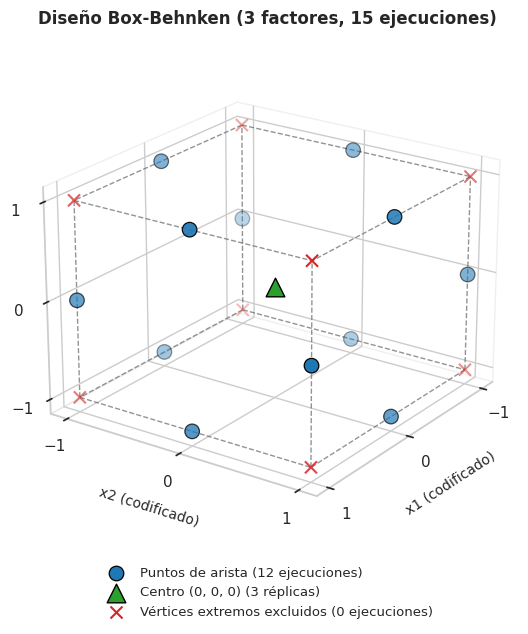

In [ ]:
# @title Ilustración diseño BBD
import itertools
import numpy as np
import matplotlib.pyplot as plt

def graficar_box_behnken_3d(cod_bb):
    fig = plt.figure(figsize=(8.5, 6.5))
    fig.patch.set_facecolor("white")
    ax = fig.add_subplot(111, projection="3d")

    # 1. Dibujar las 12 aristas del cubo [-1, 1]^3
    r = [-1, 1]
    for s, e in itertools.combinations(np.array(list(itertools.product(r, r, r))), 2):
        if np.sum(np.abs(s - e)) == 2:
            ax.plot3D(*zip(s, e), color="#666666", linestyle="--", linewidth=1.0, alpha=0.7)

    # 2. Separar puntos de borde (aristas) y puntos centrales de cod_bb
    es_centro = (cod_bb == 0).all(axis=1)
    aristas = cod_bb[~es_centro]
    n_centros = int(es_centro.sum())

    # 3. Graficar puntos de borde (12 ejecuciones)
    ax.scatter(
        aristas["x1"], aristas["x2"], aristas["x3"],
        s=110, c="#1f77b4", marker="o", edgecolors="black", linewidth=0.9,
        label=f"Puntos de arista ({len(aristas)} ejecuciones)", zorder=4
    )

    # 4. Graficar punto central (0, 0, 0)
    ax.scatter(
        [0], [0], [0],
        s=180, c="#2ca02c", marker="^", edgecolors="black", linewidth=1.0,
        label=f"Centro (0, 0, 0) ({n_centros} réplicas)", zorder=5
    )

    # 5. Marcar los 8 vértices extremos excluidos (±1, ±1, ±1)
    vertices = np.array(list(itertools.product([-1, 1], repeat=3)))
    ax.scatter(
        vertices[:, 0], vertices[:, 1], vertices[:, 2],
        s=75, c="#d62728", marker="x", linewidth=1.5,
        label="Vértices extremos excluidos (0 ejecuciones)", zorder=3
    )

    # 6. Estética, ejes y leyenda
    ax.set_title(
        f"Diseño Box-Behnken (3 factores, {len(cod_bb)} ejecuciones)",
        fontsize=12, fontweight="bold", pad=14
    )
    ax.set_xlabel("x1 (codificado)", fontsize=10, labelpad=8)
    ax.set_ylabel("x2 (codificado)", fontsize=10, labelpad=8)
    ax.set_zlabel("x3 (codificado)", fontsize=10, labelpad=8)

    for axis in (ax.set_xticks, ax.set_yticks, ax.set_zticks):
        axis([-1, 0, 1])

    ax.set_xlim(-1.15, 1.15)
    ax.set_ylim(-1.15, 1.15)
    ax.set_zlim(-1.15, 1.15)
    ax.view_init(elev=22, azim=35)

    # Fondo limpio en los paneles 3D
    for pane in (ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane):
        pane.fill = False
        pane.set_edgecolor("#E0E0E0")

    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=1, frameon=False, fontsize=9.5)
    plt.tight_layout()
    plt.show()

graficar_box_behnken_3d(cod_bb)

##  🔵 **5. Diseños de Relleno de Espacio**

### 🚀 **Reto**

**El Oráculo Determinista (Space-Filling Design)**

Tienes un simulador de tráfico para una Smart City. Cada simulación tarda 3 horas en ejecutarse y el resultado es determinista (no hay ruido). Tienes presupuesto de tiempo para solo 5 ejecuciones. Tienes dos variables: Densidad_Coches (0 a 100) y Duración_Semáforo (10 a 60s).

El Problema: Si eliges valores al azar (Random Sampling), podrías tener mala suerte y probar solo casos de tráfico bajo, dejando sin explorar los casos críticos de saturación.

Reflexiona sobre cómo podría funcionar la experimentación si utilizas 5 puntos aleatorios, o si empleas el muestreo de hipercubo latino. Para ello:

- Genera 5 puntos aleatorios simples.

- Genera 5 puntos usando Latin Hypercube Sampling (LHS).

- Grafica ambos (Scatter plot) y observa visualmente cuál deja menos "huecos" en el espacio 2D.



###  🧰 **Herramientas**

#### **Diseños de Relleno de Espacio (Space-Filling)**

En los experimentos con **simuladores y modelos de ML caros**, los factores suelen ser **continuos** y el objetivo inicial es **explorar el espacio** más que comparar unos pocos niveles fijos. Al no existir ruido aleatorio que filtrar (estos sistemas son inherentemente deterministas: la misma entrada produce siempre la misma salida), el principal enemigo no es la varianza, sino el desconocimiento de la superficie de respuesta (sesgo). Por tanto, la estrategia óptima no es asegurar la precisión en un punto mediante replicación, sino maximizar la cobertura del espacio para detectar tendencias y óptimos locales que un diseño rígido pasaría por alto.  


Un diseño se llama **de relleno de espacio (space-filling)** cuando sus puntos:

- Se **dispersan bien** por toda la región de interés; ofrecen mejor cobertura marginal que el muestreo aleatorio.
- Evitan que haya grandes “huecos” sin observar.
- Mantienen buenas proyecciones en dimensiones bajas (toda variable se explora bien marginalmente).
- Mejoran las probabilidades de encontrar buenas regiones con el mismo presupuesto de ejecuciones.


> A diferencia de los diseños de superficie de respuesta que asumen un modelo cuadrático para explicar la respuesta en función de los factores, estos diseños de relleno de espacio no asumen ninguna forma de la respuesta, y su objetivo es repartir los puntos de forma homogénea por toda la región para que no queden huecos donde pueda esconderse un comportamiento inesperado.

Los ejemplos más usados en informática y experimentos de ordenador son:

- **Latin Hypercube Sampling (LHS)**  
  - Genera $n$ puntos en $[0,1)^d$ de forma **aleatoria estratificada**.
  - **Filosofía:** divide cada dimensión en $n$ intervalos de igual tamaño y coloca exactamente un punto en cada intervalo de cada dimensión, de modo que cada factor queda explorado en todo su rango con $n$ niveles distintos (McKay et al., 1979).
  - *Ventajas:* muy sencillo; escala bien a muchas dimensiones; admite cualquier $n$; si un factor resulta irrelevante, los puntos no se colapsan en réplicas.
  - *Limitaciones:* solo garantiza uniformidad en cada dimensión por separado, por lo que en dos o más dimensiones puede dejar huecos (se mitiga con variantes optimizadas, como *maximin*); no es extensible, ya que $n$ se fija de antemano.

- **Secuencia de Halton**  
  - Genera $n$ puntos en $[0,1)^d$ de forma **determinista** (secuencia de baja discrepancia).
  - **Filosofía:** cada nuevo punto se coloca en el mayor hueco que dejan los anteriores. Cada dimensión se construye con una base numérica prima distinta (2, 3, 5, …), lo que evita que las dimensiones se repitan entre sí (Halton, 1960).
  - *Ventajas:* sencilla; extensible (se pueden añadir puntos sin rehacer el diseño); admite cualquier $n$.
  - *Limitaciones:* en dimensión alta ($d > 10$, aprox.) aparecen correlaciones y alineaciones entre dimensiones; conviene usar la versión aleatorizada (*scrambling*).

- **Secuencia de Sobol**  
  - Genera $n$ puntos en $[0,1)^d$ de forma **determinista** (secuencia de baja discrepancia).
  - **Filosofía:** reparte los puntos de forma que, cuando $n$ es potencia de 2, cada subcaja de igual volumen del espacio contenga exactamente el número de puntos que le corresponde (Sobol', 1967; Joe y Kuo, 2008).
  - *Ventajas:* la mejor uniformidad en dimensión media y alta; extensible duplicando $n$; muy rápida; con aleatorización (Owen, 1995) permite estimar la variabilidad mediante "réplicas".
  - *Limitaciones:* sus propiedades solo se garantizan con $n = 2^m$; sin aleatorizar puede mostrar patrones regulares.

**Limitación común: factores enteros y categóricos**  
  - Los tres métodos generan valores continuos en $[0,1)^d$. Los parámetros enteros (p. ej., tamaño de lote, número de capas) o categóricos (p. ej., tipo de operador, función de activación) obligan a **discretizar** cada coordenada, normalmente dividiendo $[0,1)$ en tantos intervalos como niveles tenga el factor.
  - Al discretizar se pierde parte de la uniformidad: aparecen **puntos repetidos** (las mismas combinaciones de niveles) y la cobertura del espacio deja de ser equilibrada, sobre todo cuando el factor tiene pocos niveles y $n$ es grande.
  - En escalas logarítmicas, la discretización se hace sobre la escala transformada (p. ej., $\log_2$ del tamaño de lote), redondeando después al valor válido más cercano.
  - Posibles soluciones:
    - Usar diseños **mixtos**: tomar un factorial completo (o fraccional) en los factores categóricos y combinarlo con un LHS o una secuencia de baja discrepancia en los continuos.
    - Usar LHS con $n$ múltiplo del número de niveles, para que cada nivel aparezca el mismo número de veces.

Estos diseños están disponibles en `Scipy` y `pyDOE3`. En concreto, el muestreo de hipercubos latinos se puede consultar en la documentación de [`Scipy-Stats`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.qmc.LatinHypercube.html#scipy.stats.qmc.LatinHypercube) o  [`pyDOE3`](https://pydoe3.readthedocs.io/en/stable/randomized.html#latin-hypercube).

#### **¿Cuánto llena un diseño? La discrepancia**

La cobertura, además de mirarse, se puede medir. La **discrepancia** compara la proporción de puntos que cae en cada subregión del espacio con el volumen de esa subregión: cuanto más baja, más uniforme es el reparto. `scipy.stats.qmc.discrepancy` la calcula para cualquier conjunto de puntos en $[0,1]^d$ y permite comparar diseños con el mismo número de puntos.

#### **¿Y si el algoritmo es estocástico?**

Los diseños de relleno nacieron para simuladores deterministas, donde repetir un punto no aporta nada. Con un algoritmo estocástico hay que repartir el presupuesto entre **puntos** (configuraciones distintas) y **réplicas** (semillas por configuración):

- Para **explorar** qué región del espacio es prometedora, suelen rendir más muchos puntos con pocas réplicas (2 o 3 bastan para tener una idea del ruido): el modelo que se ajuste después promedia el ruido entre puntos vecinos.
- Para **comparar** unas pocas configuraciones finalistas, se invierte el reparto: pocas configuraciones y muchas réplicas (Unidad 4, apartado 1).

En los dos casos el plan se construye igual: los puntos del diseño son las configuraciones, y `construir_plan` añade réplicas, semillas y orden.

📖 **Lectura opcional. Diseños secuenciales y configuración automática.** Todos los diseños de esta unidad fijan las configuraciones antes de ejecutar. Los métodos de configuración automática deciden cada tanda a la vista de los resultados anteriores: las **carreras** (*racing*, por ejemplo `irace`) descartan pronto las configuraciones claramente peores y concentran las ejecuciones en las candidatas; la **optimización bayesiana** (por ejemplo `SMAC`) ajusta un modelo de la respuesta y propone el siguiente punto a evaluar. Suelen arrancar con un diseño de relleno de espacio como los de este apartado.


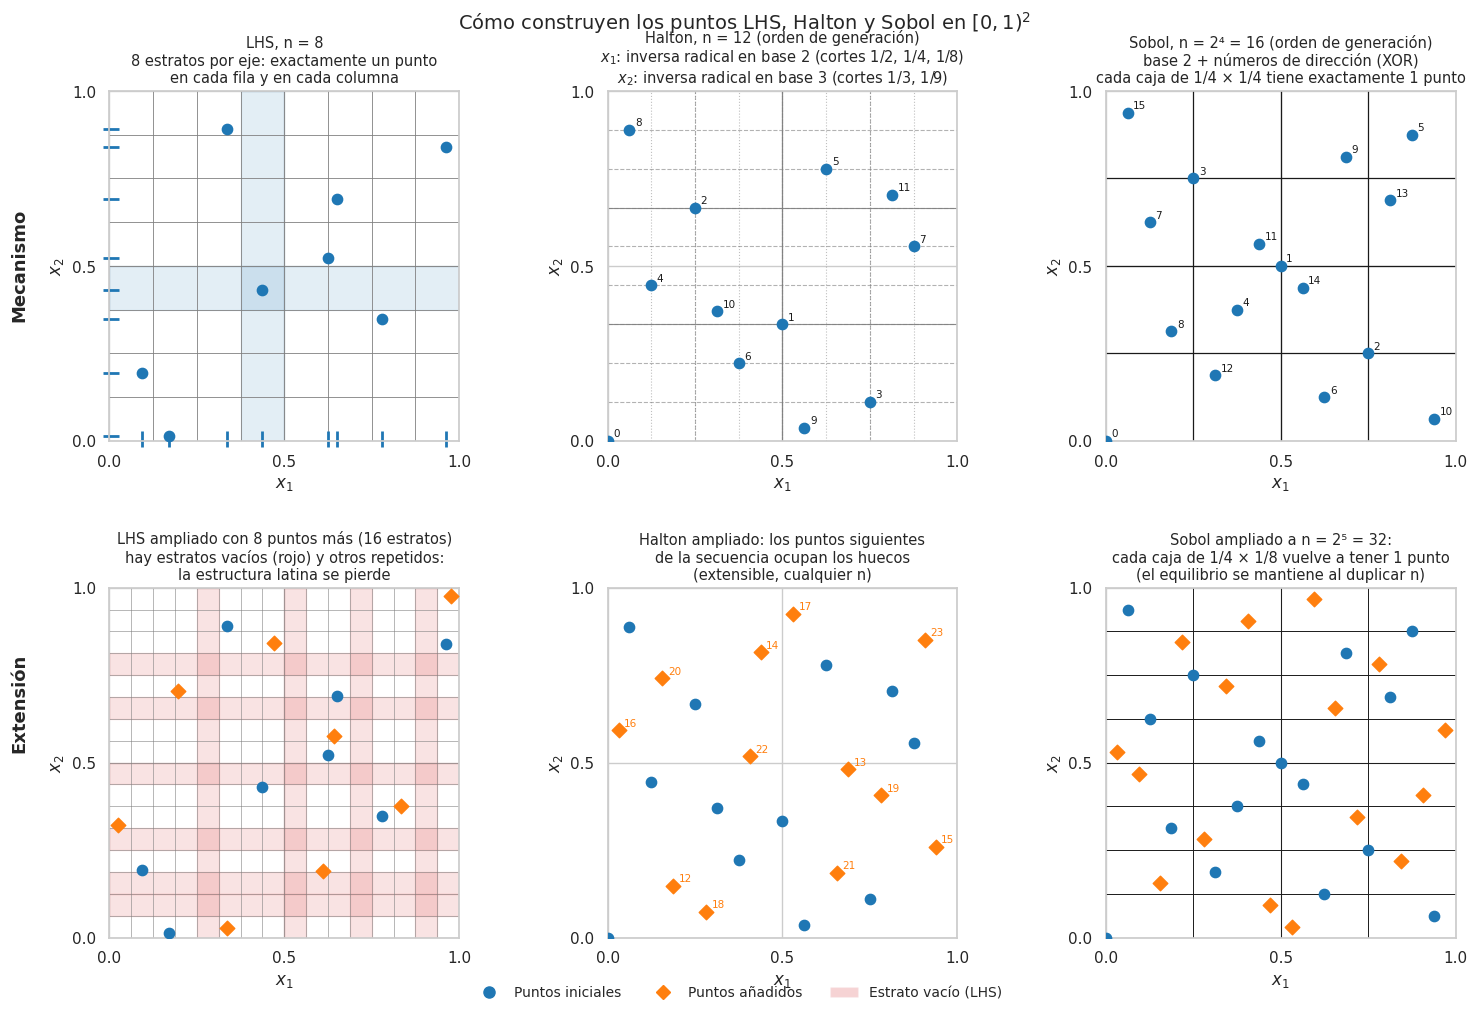

In [ ]:
# @title Ilustración de los diseños de relleno de espacio
"""
Cómo funcionan LHS, Halton y Sobol en 2D.
Fila 1 (mecanismo): la estructura que garantiza cada método.
Fila 2 (extensión): qué ocurre al añadir el mismo número de puntos nuevos.
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import qmc

C_ORIG, C_NUEVO, C_VACIO = "#1f77b4", "#ff7f0e", "#d62728"
SEM = 7


def marco(ax, titulo):
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.set_xticks([0, 0.5, 1]); ax.set_yticks([0, 0.5, 1])
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_title(titulo, fontsize=10.5)


def rejilla(ax, nx, ny, **kw):
    kw = {"c": "grey", "lw": 0.6, **kw}
    for v in np.arange(1, nx) / nx:
        ax.axvline(v, **kw)
    for v in np.arange(1, ny) / ny:
        ax.axhline(v, **kw)


def numerar(ax, P, ini=0, color="k"):
    for i, (x, y) in enumerate(P, start=ini):
        ax.annotate(str(i), (x, y), xytext=(4, 3), textcoords="offset points",
                    fontsize=7.5, color=color)


fig, axs = plt.subplots(2, 3, figsize=(15, 10.2))

# ---------------------------------------------------------------------------
# LHS
# ---------------------------------------------------------------------------
n = 8
lhs = qmc.LatinHypercube(d=2, seed=SEM).random(n)
ax = axs[0, 0]
rejilla(ax, n, n)
# resaltar un estrato por dimensión y el punto que lo ocupa
# elegir el punto más alejado de los bordes de su estrato (para que se vea claro)
frac = lhs * n - np.floor(lhs * n)
p = lhs[np.argmax(np.min(np.minimum(frac, 1 - frac), axis=1))]
jx, jy = int(p[0] * n), int(p[1] * n)
ax.axvspan(jx / n, (jx + 1) / n, color=C_ORIG, alpha=0.12)
ax.axhspan(jy / n, (jy + 1) / n, color=C_ORIG, alpha=0.12)
ax.scatter(*lhs.T, s=55, c=C_ORIG, zorder=3)
# marcas en los márgenes: una por estrato
ax.plot(lhs[:, 0], np.full(n, 0.005), "|", c=C_ORIG, ms=12, mew=2, clip_on=False)
ax.plot(np.full(n, 0.005), lhs[:, 1], "_", c=C_ORIG, ms=12, mew=2, clip_on=False)
marco(ax, f"LHS, n = {n}\n{n} estratos por eje: exactamente un punto\nen cada fila y en cada columna")

# Extensión: añadir 8 puntos LHS nuevos -> 16 puntos, 16 estratos
ax = axs[1, 0]
lhs2 = qmc.LatinHypercube(d=2, seed=SEM + 1).random(n)
todos = np.vstack([lhs, lhs2])
m = 2 * n
rejilla(ax, m, m, lw=0.4)
for dim, span in ((0, ax.axvspan), (1, ax.axhspan)):
    cuenta = np.bincount((todos[:, dim] * m).astype(int), minlength=m)
    for j in np.where(cuenta == 0)[0]:
        span(j / m, (j + 1) / m, color=C_VACIO, alpha=0.13)
ax.scatter(*lhs.T, s=55, c=C_ORIG, zorder=3)
ax.scatter(*lhs2.T, s=55, c=C_NUEVO, marker="D", zorder=3)
marco(ax, "LHS ampliado con 8 puntos más (16 estratos)\nhay estratos vacíos (rojo) y otros repetidos:\nla estructura latina se pierde")

# ---------------------------------------------------------------------------
# Halton
# ---------------------------------------------------------------------------
n_h = 12
hal = qmc.Halton(d=2, scramble=False).random(2 * n_h)
ax = axs[0, 1]
for k, (ls, a) in enumerate([("-", 0.9), ("--", 0.6), (":", 0.5)], start=1):
    for v in np.arange(1, 2 ** k) / 2 ** k:
        ax.axvline(v, c="grey", ls=ls, lw=0.8, alpha=a)
for k, (ls, a) in enumerate([("-", 0.9), ("--", 0.6)], start=1):
    for v in np.arange(1, 3 ** k) / 3 ** k:
        ax.axhline(v, c="grey", ls=ls, lw=0.8, alpha=a)
ax.scatter(*hal[:n_h].T, s=55, c=C_ORIG, zorder=3)
numerar(ax, hal[:n_h])
marco(ax, f"Halton, n = {n_h} (orden de generación)\n$x_1$: inversa radical en base 2 (cortes 1/2, 1/4, 1/8)\n"
          "$x_2$: inversa radical en base 3 (cortes 1/3, 1/9)")

ax = axs[1, 1]
ax.scatter(*hal[:n_h].T, s=55, c=C_ORIG, zorder=3, label=f"puntos 0–{n_h - 1}")
ax.scatter(*hal[n_h:].T, s=55, c=C_NUEVO, marker="D", zorder=3, label=f"puntos {n_h}–{2 * n_h - 1}")
numerar(ax, hal[n_h:], ini=n_h, color=C_NUEVO)
marco(ax, "Halton ampliado: los puntos siguientes\nde la secuencia ocupan los huecos\n(extensible, cualquier n)")

# ---------------------------------------------------------------------------
# Sobol
# ---------------------------------------------------------------------------
sob = qmc.Sobol(d=2, scramble=False).random_base2(m=5)  # 32 puntos
n_s = 16
ax = axs[0, 2]
rejilla(ax, 4, 4, c="k", lw=0.9)
ax.scatter(*sob[:n_s].T, s=55, c=C_ORIG, zorder=3)
numerar(ax, sob[:n_s])
marco(ax, f"Sobol, n = 2⁴ = {n_s} (orden de generación)\nbase 2 + números de dirección (XOR)\n"
          "cada caja de 1/4 × 1/4 tiene exactamente 1 punto")

ax = axs[1, 2]
rejilla(ax, 4, 8, c="k", lw=0.7)
ax.scatter(*sob[:n_s].T, s=55, c=C_ORIG, zorder=3)
ax.scatter(*sob[n_s:].T, s=55, c=C_NUEVO, marker="D", zorder=3)
marco(ax, "Sobol ampliado a n = 2⁵ = 32:\ncada caja de 1/4 × 1/8 vuelve a tener 1 punto\n"
          "(el equilibrio se mantiene al duplicar n)")

h = [plt.Line2D([], [], ls="", marker="o", c=C_ORIG, ms=8, label="Puntos iniciales"),
     plt.Line2D([], [], ls="", marker="D", c=C_NUEVO, ms=7, label="Puntos añadidos"),
     plt.Rectangle((0, 0), 1, 1, fc=C_VACIO, alpha=0.2, label="Estrato vacío (LHS)")]
fig.legend(handles=h, loc="lower center", ncol=3, frameon=False, fontsize=10)
fig.text(0.01, 0.73, "Mecanismo", rotation=90, fontsize=13, va="center", weight="bold")
fig.text(0.01, 0.30, "Extensión", rotation=90, fontsize=13, va="center", weight="bold")
fig.suptitle("Cómo construyen los puntos LHS, Halton y Sobol en $[0,1)^2$", fontsize=14)
fig.subplots_adjust(left=0.06, right=0.99, top=0.9, bottom=0.07, hspace=0.42, wspace=0.25)
fig.savefig("relleno_espacio_mecanismo.png", dpi=200, bbox_inches="tight")
plt.show()

### 📚 **Referencias**

* **Santner, T. J., Williams, B. J., & Notz, W. I.** (2018). The design and analysis of computer experiments (2.ª ed.). Springer. https://doi.org/10.1007/978-1-4939-8847-1.

  💎 **Interés:** Es la biblia de los experimentos computacionales. Formaliza la diferencia entre experimentos físicos (con ruido) y simulaciones deterministas, y explica por qué los diseños de relleno de espacio (LHS, secuencias de baja discrepancia) combinados con procesos gaussianos (*kriging*) son la alternativa natural a la superficie de respuesta clásica.

* **McKay, M. D., Beckman, R. J., & Conover, W. J.** (1979). A comparison of three methods for selecting values of input variables in the analysis of output from a computer code. Technometrics, 21(2), 239–245. https://doi.org/10.1080/00401706.1979.10489755.

  💎 **Interés:** Artículo seminal del LHS y fuente primaria para citar su origen y su ventaja sobre el muestreo Monte Carlo simple. Lectura corta y muy esclarecedora.

* **Halton, J. H.** (1960). On the efficiency of certain quasi-random sequences of points in evaluating multi-dimensional integrals. Numerische Mathematik, 2(1), 84–90. https://doi.org/10.1007/BF01386213.

  💎 **Interés:** Artículo original de la secuencia de Halton. Referencia para citar el método.

* **Sobol', I. M.** (1967). On the distribution of points in a cube and the approximate evaluation of integrals. USSR Computational Mathematics and Mathematical Physics, 7(4), 86–112. https://doi.org/10.1016/0041-5553(67)90144-9.

  💎 **Interés:** Artículo original de la secuencia de Sobol. Referencia para citar el método.

* **Joe, S., & Kuo, F. Y.** (2008). Constructing Sobol sequences with better two-dimensional projections. SIAM Journal on Scientific Computing, 30(5), 2635–2654. https://doi.org/10.1137/070709359.

  💎 **Interés:** Proporciona los números de dirección que usan las implementaciones actuales de Sobol (p. ej., SciPy). Útil si se trabaja con muchos parámetros.

* **Owen, A. B.** (1995). Randomly permuted (t,m,s)-nets and (t,s)-sequences. En H. Niederreiter & P. J.-S. Shiue (Eds.), Monte Carlo and quasi-Monte Carlo methods in scientific computing (pp. 299–315). Springer. https://doi.org/10.1007/978-1-4612-2552-2_19.

  💎 **Interés:** Introduce la aleatorización (*scrambling*) de las secuencias de baja discrepancia, que conserva su uniformidad y permite estimar la variabilidad de los resultados (lectura opcional, de carácter técnico).

* **Bergstra, J., & Bengio, Y.** (2012). Random search for hyper-parameter optimization. Journal of Machine Learning Research, 13, 281–305. ([Open Access](https://www.jmlr.org/papers/v13/bergstra12a.html)).

  💎 **Interés:** Muestra por qué la búsqueda aleatoria supera a la rejilla cuando solo unos pocos hiperparámetros importan. Es la referencia del ejercicio 1.

* **López-Ibáñez, M., Dubois-Lacoste, J., Pérez Cáceres, L., Birattari, M., & Stützle, T.** (2016). The irace package: Iterated racing for automatic algorithm configuration. Operations Research Perspectives, 3, 43–58. https://doi.org/10.1016/j.orp.2016.09.002.

  💎 **Interés:** Referencia de la configuración automática de algoritmos por carreras (lectura opcional).

###  🔑 **Solución**



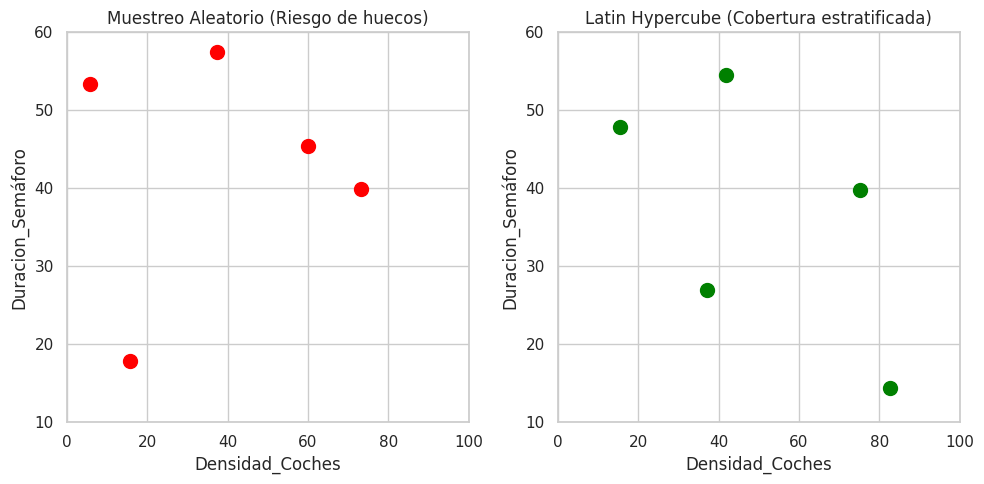

Observa cómo LHS evita que dos puntos compartan la misma fila o columna virtual.

 -- 

Random Sampling:
   Densidad_Coches  Duracion_Semáforo
0        37.454012          57.535715
1        73.199394          39.932924
2        15.601864          17.799726
3         5.808361          53.308807
4        60.111501          45.403629

 -- 

Latin Hypercube Sampling:
   Densidad_Coches  Duracion_Semáforo
0        82.562273          14.388784
1        15.479121          47.860643
2        41.883547          54.503859
3        75.222794          39.756224
4        37.171958          26.973680


In [ ]:
# @title Comparación muestreo aleatorio e hipercubo latino
# Comparación de muestreo aleatorio con muestreo de hipercubos latinos con pyDOE3
# https://pydoe3.readthedocs.io/en/stable/randomized.html#latin-hypercube

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import qmc # Quasi-Monte Carlo submodule
try:
 import pyDOE3 # Importar pyDOE3
except ImportError:
  !pip install pyDOE3
  import pyDOE3
from pyDOE3 import lhs # Importar la función lhs

# 1. Random Sampling (El enfoque ingenuo)
np.random.seed(42)
# Generamos muestras uniformes (0,1)
random_points_unit = np.random.rand(5, 2)

# Definimos cotas inferiores y superiores de las variables
l_bounds = [0, 10]
u_bounds= [100, 60]

# Escalamos las muestras entre las cotas (sin la función qm.scale)
random_points = random_points_unit.copy()
for i in range(len(l_bounds)):
  random_points[:,i]= random_points_unit[:,i]*(u_bounds[i]-l_bounds[i])+l_bounds[i]
random_points = pd.DataFrame(random_points, columns=['Densidad_Coches', 'Duracion_Semáforo'])

# 2. Latin Hypercube Sampling (El enfoque profesional) - Usando pyDOE3.lhs
# Generar la muestra en el hipercubo unitario usando pyDOE3.lhs
lhs_points_unit = lhs(n=2, samples=5, seed=42)
lhs_points = lhs_points_unit.copy()
# Escalar los puntos LHS a rangos reales para el plotting
for i in range(len(l_bounds)):
  lhs_points[:,i]= lhs_points_unit[:,i]*(u_bounds[i]-l_bounds[i])+l_bounds[i]
lhs_points = pd.DataFrame(lhs_points, columns=['Densidad_Coches', 'Duracion_Semáforo'])

# Visualización
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,5))

# Plot Random
ax1.scatter(random_points['Densidad_Coches'], random_points['Duracion_Semáforo'], c='red', s=100)
ax1.set_title("Muestreo Aleatorio (Riesgo de huecos)")
ax1.set_xlabel('Densidad_Coches')
ax1.set_ylabel('Duracion_Semáforo')
ax1.set_xlim(l_bounds[0], u_bounds[0]); ax1.set_ylim(l_bounds[1], u_bounds[1]) # Ajustar límites a los valores reales
ax1.grid(True)

# Plot LHS
ax2.scatter(lhs_points['Densidad_Coches'], lhs_points['Duracion_Semáforo'], c='green', s=100)
ax2.set_title("Latin Hypercube (Cobertura estratificada)")
ax2.set_xlabel('Densidad_Coches')
ax2.set_ylabel('Duracion_Semáforo')
ax2.set_xlim(l_bounds[0], u_bounds[0]); ax2.set_ylim(l_bounds[1], u_bounds[1]) # Ajustar límites a los valores reales
ax2.grid(True)

plt.tight_layout()
plt.show()
print("Observa cómo LHS evita que dos puntos compartan la misma fila o columna virtual.")
print("\n -- \n")
print("Random Sampling:")
print(random_points)
print("\n -- \n")
print("Latin Hypercube Sampling:")
print(lhs_points)

**¿Cuál llena mejor?** Lo medimos con la discrepancia (más baja = reparto más uniforme). Con solo 5 puntos el resultado de un sorteo concreto varía mucho, así que repetimos el sorteo 1.000 veces.

In [ ]:
from scipy.stats import qmc

n_puntos, n_sorteos = 5, 1000
rng = np.random.default_rng(42)
disc_aleatorio = np.array([qmc.discrepancy(rng.random((n_puntos, 2))) for _ in range(n_sorteos)])
disc_lhs = np.array([qmc.discrepancy(qmc.LatinHypercube(d=2, seed=rng).random(n_puntos))
                     for _ in range(n_sorteos)])

print(f"Discrepancia del diseño aleatorio dibujado arriba: {qmc.discrepancy(random_points_unit):.3f}")
print(f"Discrepancia del LHS dibujado arriba:              {qmc.discrepancy(lhs_points_unit):.3f}")
print(f"\nMediana en {n_sorteos} sorteos -> aleatorio: {np.median(disc_aleatorio):.3f} | LHS: {np.median(disc_lhs):.3f}")
print(f"El LHS llena mejor que el aleatorio en el {np.mean(disc_lhs < disc_aleatorio):.0%} de los sorteos.")

Discrepancia del diseño aleatorio dibujado arriba: 0.065
Discrepancia del LHS dibujado arriba:              0.020

Mediana en 1000 sorteos -> aleatorio: 0.065 | LHS: 0.020
El LHS llena mejor que el aleatorio en el 99% de los sorteos.


📖 **Opcional. Secuencias de Sobol y Halton** con `scipy.stats.qmc`. Su ventaja práctica es que son *ampliables*: si después de ejecutar 16 puntos hay presupuesto para 16 más, se continúa la secuencia y los 32 siguen llenando bien el espacio. Un LHS no se puede ampliar así.

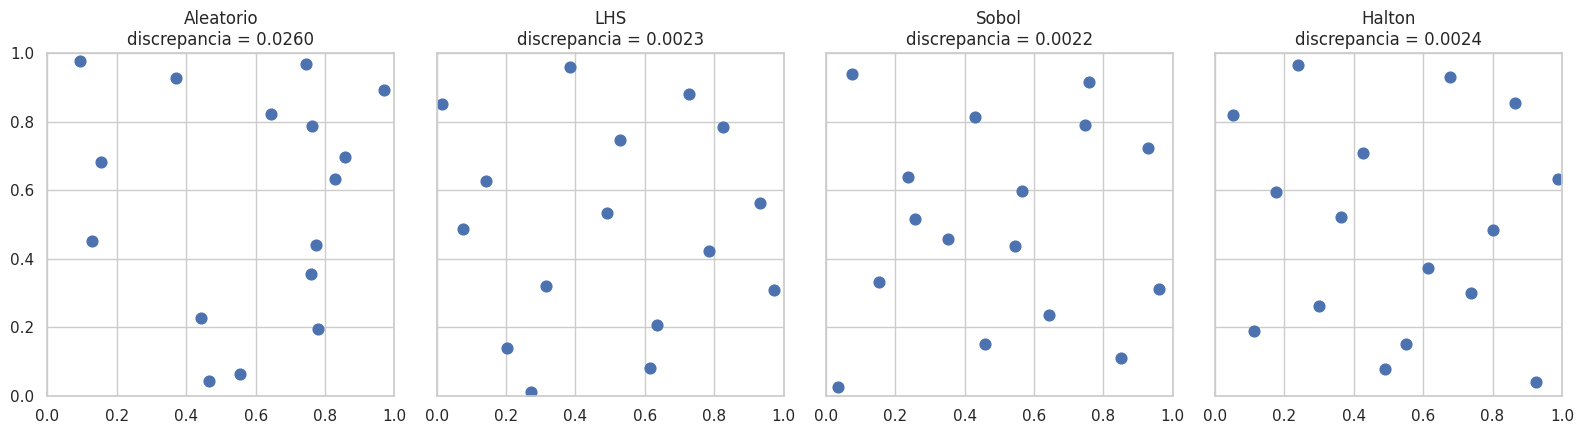

,Densidad_Coches,Duracion_Semáforo
0,43.1,50.7
1,96.2,25.6
2,56.5,39.9
3,3.5,11.3
4,23.8,42.0


In [ ]:
n = 16
disenos = {
    'Aleatorio': np.random.default_rng(42).random((n, 2)),
    'LHS':       qmc.LatinHypercube(d=2, seed=42).random(n),
    'Sobol':     qmc.Sobol(d=2, scramble=True, seed=42).random_base2(m=4),    # 2^4 = 16 puntos
    'Halton':    qmc.Halton(d=2, scramble=True, seed=42).random(n),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), sharey=True)
for ax, (nombre, puntos) in zip(axes, disenos.items()):
    ax.scatter(puntos[:, 0], puntos[:, 1], s=60)
    ax.set_title(f"{nombre}\ndiscrepancia = {qmc.discrepancy(puntos):.4f}")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

# Del cubo unidad a los rangos reales del reto, con qmc.scale
sobol_real = pd.DataFrame(qmc.scale(disenos['Sobol'], l_bounds, u_bounds),
                          columns=['Densidad_Coches', 'Duracion_Semáforo'])
display(sobol_real.head().round(1))

**Plantilla: relleno de espacio con réplicas** para un algoritmo estocástico. Los puntos del LHS son las configuraciones; `construir_plan` añade réplicas, semillas y orden.

In [ ]:
# PLANTILLA: cambia los rangos, el número de puntos y las réplicas
rangos_lhs = {'param_A': (10, 100), 'param_B': (0.1, 0.5)}     # (mínimo, máximo)
n_puntos, n_replicas = 20, 3

unitario = qmc.LatinHypercube(d=len(rangos_lhs), seed=42).random(n_puntos)
minimos = [r[0] for r in rangos_lhs.values()]
maximos = [r[1] for r in rangos_lhs.values()]
puntos = pd.DataFrame(qmc.scale(unitario, minimos, maximos), columns=list(rangos_lhs))

plan_lhs = construir_plan(puntos, n_replicas=n_replicas, semilla=42)
print(f"{n_puntos} configuraciones x {n_replicas} réplicas = {len(plan_lhs)} ejecuciones")
display(plan_lhs.head())

20 configuraciones x 3 réplicas = 60 ejecuciones


,orden,id_config,param_A,param_B,replica,semilla
0,1,12,64.131859,0.162138,3,3132050763
1,2,8,48.504636,0.215455,2,408731928
2,3,18,97.886999,0.416211,1,4178181242
3,4,5,54.423489,0.310992,1,1691623607
4,5,20,58.478908,0.286604,3,997242548


# 🛠️ **EJERCICIOS: El Detective de Datos**

En esta unidad, nos ponemos el sombrero de ingenieros de datos. Antes de intentar probar hipótesis, debemos asegurarnos de que:
1.  Hemos recolectado los datos de forma eficiente (Diseño).
2.  Los datos están limpios y estructurados (Tidy Data).
3.  Entendemos la "forma" de los datos (EDA).

A continuación, encontrarás retos para practicar estas habilidades críticas.

Todos los ejercicios se plantean sin resolver. Las soluciones están al final del cuaderno, en celdas plegadas.

In [ ]:
# Módulos necesarios para los ejercicios (por si empiezas el cuaderno por aquí)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 🟢 **BLOQUE 1: Estrategias de Muestreo y Diseño**


#### **Ejercicio 1:** La Maldición de la Dimensionalidad (Grid Search vs Random Search)
**Situación:** Quieres optimizar los hiperparámetros de un algoritmo genético. Tienes 6 parámetros, cada uno con 5 niveles posibles.

**Reto:**
1.  Calcula cuántos experimentos requiere un factorial completo (*grid search*) y cuánto tardaría a 1 minuto por experimento.
1.  En dos dimensiones, genera:
  - una rejilla completa con 10 puntos por dimensión,
  - una búsqueda aleatoria (*random search*) con la mitad de puntos,
  - un LHS con la mitad de puntos.
1.  Visualiza los tres diseños.
1.  Cuenta cuántos valores distintos de cada hiperparámetro prueba cada diseño. ¿Qué ocurre con la rejilla si uno de los dos hiperparámetros resulta no influir?

In [ ]:
n_factores = 6
n_niveles = 5
puntos_grid_por_eje = 10

# TU CÓDIGO AQUÍ:
# 1. total_experimentos = ...
# 2. grid_points (np.linspace + np.meshgrid), random_points (np.random.rand)
#    y lhs_points (pyDOE3.lhs), todos en el cuadrado [0, 1] x [0, 1].
# 3. Tres gráficos de dispersión, uno por diseño.
# 4. Valores distintos por eje: len(np.unique(puntos[:, 0]))

### **Ejercicio 2:** Screening de Factores (Plackett-Burman)

Situación: Tienes 7 variables de configuración en tu servidor y no sabes cuáles importan. Solo puedes permitirte unas pocas pruebas.

Reto:
1. Genera un diseño de Plackett-Burman para los 7 factores (`pbdesign`). ¿Cuántas configuraciones tiene, frente a las $2^7$ del factorial completo?
1. Construye el plan con 3 réplicas (`construir_plan`) y ejecútalo sobre la caja negra `servidor_caja_negra` (`ejecutar_plan`).
1. Estima el efecto de cada factor como la diferencia entre la respuesta media en su nivel alto ($+1$) y en su nivel bajo ($-1$).
1. Dibuja los efectos ordenados por su valor absoluto e identifica los "Pocos Vitales" (Pareto) frente a los "Muchos Triviales". Aquí solo describimos; el contraste de si un efecto es significativo llega en la Unidad 3.

In [ ]:
factores_srv = ['CPU_Cores', 'RAM_Size', 'Disk_Type', 'Network_Bandwidth',
                'Cache_Policy', 'IO_Scheduler', 'Thread_Pool']

def servidor_caja_negra(fila):
    """Rendimiento del servidor (peticiones/s) para una configuración codificada en -1/+1.
    No mires dentro: el ejercicio consiste en descubrir qué factores importan."""
    rng = np.random.default_rng(fila['semilla'])
    ocultos = [0.5, 8.2, 5.1, 0.3, 0.1, 0.8, 0.2]
    y = 100 + sum(e / 2 * fila[f] for e, f in zip(ocultos, factores_srv)) + rng.normal(0, 1.5)
    return {'Rendimiento': y}

# TU CÓDIGO AQUÍ:
# 1. diseno_pb = pd.DataFrame(pbdesign(7), columns=factores_srv)
# 2. plan_pb = construir_plan(...);  res_pb = ejecutar_plan(plan_pb, servidor_caja_negra, ['Rendimiento'])
# 3. Para cada factor: media de 'Rendimiento' cuando vale +1 menos media cuando vale -1.
# 4. Gráfico de barras de los efectos en valor absoluto, de mayor a menor.

## 🟡 **BLOQUE 2: Limpieza y "Tidy Data"**

### **Ejercicio 3:** Del Excel al DataFrame (Melt)

Situación: Tu compañero te pasa los resultados de sus simulaciones en un formato "ancho" (típico de Excel humano).

Reto: Las librerías de Python (seaborn, statsmodels) odian este formato. Transfórmalo a formato "Largo" (Tidy) usando pd.melt.

In [ ]:
# Generación del dataset "Sucio" (Wide Format)
df_wide = pd.DataFrame({
    'Algoritmo': ['Algo_A', 'Algo_B', 'Algo_C'],
    'Run_1': [100, 110, 95],
    'Run_2': [102, 108, 96],
    'Run_3': [101, 109, 94],
    'Run_4': [99, 111, 95]
})

print("--- Formato Original (Wide) ---")
print(df_wide)

# TU CÓDIGO AQUÍ:
# Usa pd.melt para convertir las columnas Run_1...Run_4 en una variable 'Run' y otra 'Valor'.
# El resultado debe tener 3 columnas: Algoritmo, Run_ID, Tiempo.

# df_long = df_wide.melt(...)
# print("\n--- Formato Tidy (Long) ---")
# print(df_long)

--- Formato Original (Wide) ---
  Algoritmo  Run_1  Run_2  Run_3  Run_4
0    Algo_A    100    102    101     99
1    Algo_B    110    108    109    111
2    Algo_C     95     96     94     95


## 🔴 **BLOQUE 3: Análisis Exploratorio Visual (EDA)**

### **Ejercicio 4:** La Mentira del Promedio (Distribuciones Asimétricas)

Situación: Estás midiendo la latencia de una API. Tu jefe te pide el "tiempo promedio de respuesta".

Reto: Los datos de latencia suelen seguir una distribución Log-Normal o Gamma (cola larga). Calcula la Media y la Mediana. ¿Cuál representa mejor al usuario típico?

In [ ]:
np.random.seed(99)
# Generamos latencias (skewed): La mayoría rápidas (50ms), algunas muy lentas.
latencias = np.random.lognormal(mean=4.0, sigma=1.0, size=1000)

print(f"Media Aritmética: {np.mean(latencias):.2f} ms")
print(f"Mediana (P50):    {np.median(latencias):.2f} ms")

# TU CÓDIGO AQUÍ:
# 1. Dibuja un Histograma (sns.histplot) con kde=True.
# 2. Añade líneas verticales para la media (rojo) y mediana (verde).
# 3. Reflexiona: Si optimizas para bajar la media, ¿podrías estar ignorando a la mayoría de usuarios?

Media Aritmética: 97.35 ms
Mediana (P50):    57.21 ms


### **Ejercicio 5:** El Cuarteto de Anscombe (Versión IT)

Situación: Tienes dos servidores (Server A y Server B). Ambos tienen prácticamente la misma media de carga de CPU y la misma desviación estándar. ¿Son iguales?

Reto: Visualiza los datos para descubrir que tienen comportamientos radicalmente distintos.

In [ ]:
np.random.seed(5)
n = 200
# Server A: carga estable alrededor del 50 % (Normal)
server_a = np.random.normal(50, 10, n)

# Server B: bimodal (alterna entre dos regímenes: en torno al 40 % y en torno al 60 %)
# Tiene la misma media (~50) y una desviación similar, pero su comportamiento es otro.
server_b = np.concatenate([np.random.normal(40, 2, n//2), np.random.normal(60, 2, n//2)])

df_servers = pd.DataFrame({
    'Carga_CPU': np.concatenate([server_a, server_b]),
    'Server': ['Server A']*n + ['Server B']*n
})

print("--- Estadísticas Descriptivas ---")
print(df_servers.groupby('Server')['Carga_CPU'].agg(['mean', 'std']))

# TU CÓDIGO AQUÍ:
# Usa un Violin Plot (sns.violinplot) o un Boxplot para comparar los dos servidores.
# ¿Cuál de los dos gráficos deja ver la diferencia?

--- Estadísticas Descriptivas ---
               mean        std
Server                        
Server A  50.593792   9.859425
Server B  50.022616  10.470038


### **Ejercicio 6**: Correlación vs. Causalidad (Heatmaps)

Situación: Estás analizando logs de un clúster. Quieres ver qué métricas están relacionadas.

Reto: Genera una matriz de correlación y visualízala con un Heatmap. Detecta redundancia (variables que miden lo mismo).

In [ ]:
# Generación de datos correlacionados
np.random.seed(21)
n = 100
usuarios = np.random.randint(100, 1000, n)
peticiones = usuarios * 5 + np.random.normal(0, 50, n) # Correlación total con usuarios
cpu_temp = 40 + peticiones * 0.01 + np.random.normal(0, 2, n) # Correlación con peticiones
fan_speed = cpu_temp * 50 # Correlación total con temperatura
hora_dia = np.random.randint(0, 24, n) # Ruido, sin correlación

data = pd.DataFrame({
    'Usuarios_Conectados': usuarios,
    'Peticiones_Seg': peticiones,
    'Temp_CPU': cpu_temp,
    'Fan_RPM': fan_speed,
    'Hora': hora_dia
})

# TU CÓDIGO AQUÍ:
# 1. Calcula la matriz de correlación: corr = data.corr()
# 2. Pinta el mapa de calor: sns.heatmap(corr, annot=True, cmap='coolwarm')
# 3. Pregunta: Si 'Fan_RPM' y 'Temp_CPU' tienen corr=1.0, ¿necesitas incluir ambas en tu modelo de Machine Learning?

## 🧠 **RETO FINAL: El Arqueólogo de Datos**

### **Ejercicio 7:** Detectando Outliers e Inconsistencias

Situación: Te han pasado un dataset de tiempos de ejecución de una Query SQL. Te dicen que está "limpio".

Reto:

- Encuentra el valor imposible (Outlier físico).

- Encuentra el valor perdido (NaN) camuflado.

- Decide qué hacer con ellos.

In [ ]:
# Dataset sucio
np.random.seed(123)
tiempos_query = np.random.gamma(2, 20, 100) # Datos normales
tiempos_query[10] = -50.0  # IMPOSIBLE: Tiempo negativo (Error de log)
tiempos_query[50] = 99999  # OUTLIER: Probablemente un timeout o código de error
tiempos_query[80] = np.nan # VALOR PERDIDO

df_dirty = pd.DataFrame({'Query_ID': range(100), 'Tiempo_ms': tiempos_query})

# TU CÓDIGO AQUÍ:
# 1. Usa df_dirty.describe() para ver mínimos y máximos sospechosos.
# 2. Filtra los datos: Quita negativos y NaNs.
# 3. Haz un Boxplot para ver si el 99999 aplasta el gráfico.

# 🔑 **SOLUCIONES DE LOS EJERCICIOS**

Intenta cada ejercicio antes de abrir su solución. En Colab las celdas aparecen plegadas: despliégalas con «Mostrar código». Ejecútalas después de la celda de su enunciado, porque usan sus datos.

--- ANÁLISIS DE COSTES ---
Factores: 6
Niveles por factor: 5
Total de experimentos (Full Factorial): 5^6 = 15,625
Si cada exp tarda 1 minuto: 10.9 días de cómputo.
------------------------------


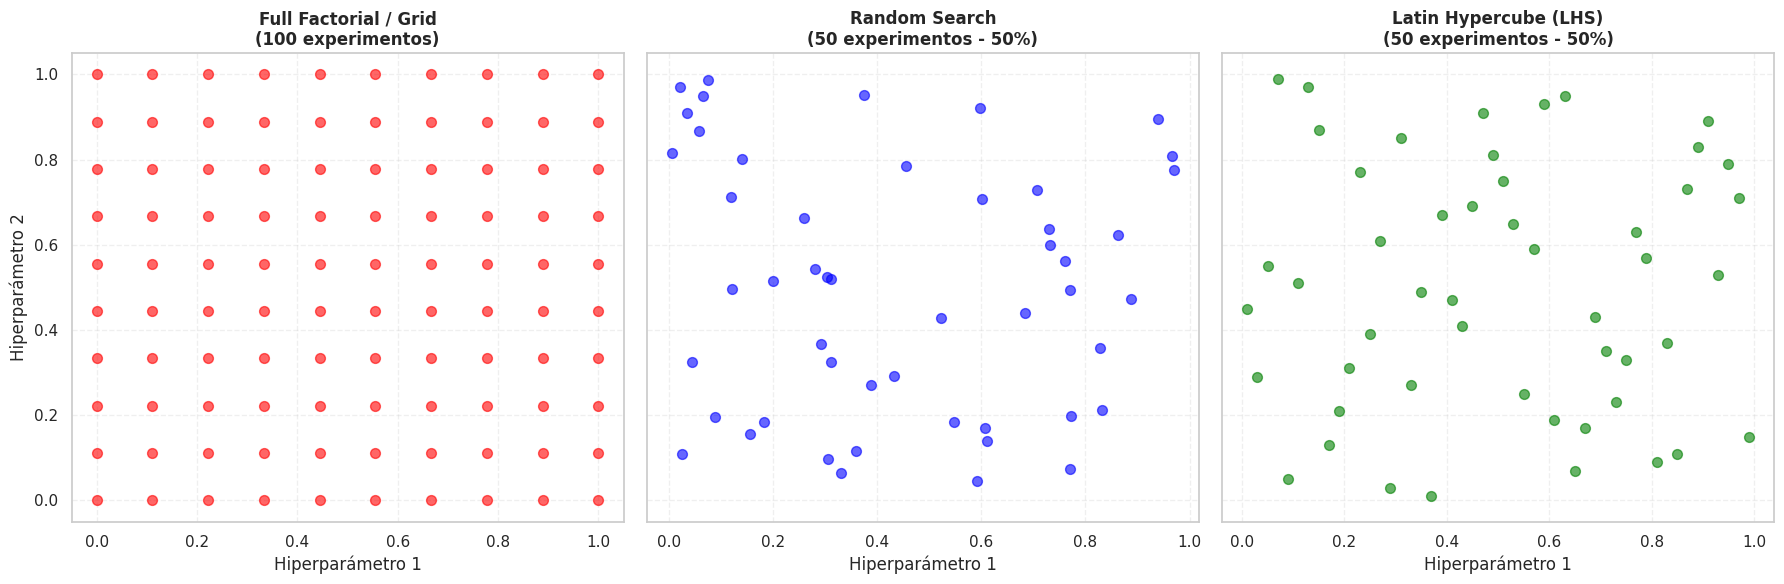

Grid   : 100 experimentos, 10 valores distintos del hiperparámetro 1
Random :  50 experimentos, 50 valores distintos del hiperparámetro 1
LHS    :  50 experimentos, 50 valores distintos del hiperparámetro 1


In [ ]:
# @title Solución del ejercicio 1
import numpy as np
import matplotlib.pyplot as plt
from pyDOE3 import lhs  # Asegúrate de tener: pip install pyDOE3

# ==========================================
# PARTE 1: El Cálculo Teórico (La Maldición)
# ==========================================
n_factores = 6
n_niveles = 5

# Cálculo de combinaciones
total_experimentos = n_niveles ** n_factores

print(f"--- ANÁLISIS DE COSTES ---")
print(f"Factores: {n_factores}")
print(f"Niveles por factor: {n_niveles}")
print(f"Total de experimentos (Full Factorial): {n_niveles}^{n_factores} = {total_experimentos:,}")
print(f"Si cada exp tarda 1 minuto: {total_experimentos/60/24:.1f} días de cómputo.")
print("-" * 30)


# ==========================================
# PARTE 2: Simulación y Visualización en 2D
# ==========================================

# Configuración del experimento 2D
puntos_grid_por_eje = 10
total_puntos_grid = puntos_grid_por_eje ** 2  # 100 puntos
total_puntos_optimizados = total_puntos_grid // 2  # 50 puntos (La mitad)

# 1. GRID SEARCH (10x10)
x = np.linspace(0, 1, puntos_grid_por_eje)
y = np.linspace(0, 1, puntos_grid_por_eje)
xx, yy = np.meshgrid(x, y)
grid_points = np.c_[xx.ravel(), yy.ravel()]

# 2. RANDOM SEARCH (50 puntos)
np.random.seed(42)
# Generación aleatoria uniforme
random_points = np.random.rand(total_puntos_optimizados, 2)

# 3. LATIN HYPERCUBE SAMPLING - LHS (50 puntos)
# lhs(n_factores, samples=n_muestras)
lhs_points = lhs(2, samples=total_puntos_optimizados,criterion='centermaximin')

# ==========================================
# PARTE 3: Graficar los resultados
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

# Plot Grid
axes[0].scatter(grid_points[:, 0], grid_points[:, 1], c='red', alpha=0.6, s=50)
axes[0].set_title(f'Full Factorial / Grid\n({total_puntos_grid} experimentos)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Hiperparámetro 1')
axes[0].set_ylabel('Hiperparámetro 2')
axes[0].grid(True, linestyle='--', alpha=0.3)

# Plot Random
axes[1].scatter(random_points[:, 0], random_points[:, 1], c='blue', alpha=0.6, s=50)
axes[1].set_title(f'Random Search\n({total_puntos_optimizados} experimentos - 50%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Hiperparámetro 1')
axes[1].grid(True, linestyle='--', alpha=0.3)

# Plot LHS
axes[2].scatter(lhs_points[:, 0], lhs_points[:, 1], c='green', alpha=0.6, s=50)
axes[2].set_title(f'Latin Hypercube (LHS)\n({total_puntos_optimizados} experimentos - 50%)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Hiperparámetro 1')
axes[2].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# PARTE 4: Valores distintos de cada hiperparámetro
# ==========================================
for nombre, puntos in [('Grid', grid_points), ('Random', random_points), ('LHS', lhs_points)]:
    print(f"{nombre:7s}: {len(puntos):3d} experimentos, "
          f"{len(np.unique(puntos[:, 0]))} valores distintos del hiperparámetro 1")
# La rejilla gasta 100 experimentos para probar solo 10 valores de cada hiperparámetro.
# Si el hiperparámetro 2 no influye, 90 de esos 100 experimentos son repeticiones.
# Random y LHS prueban 50 valores distintos de cada uno con la mitad de experimentos.

8 configuraciones (factorial completo: 128)
RAM_Size             8.15
Disk_Type            6.01
IO_Scheduler         1.49
Thread_Pool          1.46
CPU_Cores            1.23
Cache_Policy         0.88
Network_Bandwidth   -0.61
dtype: float64


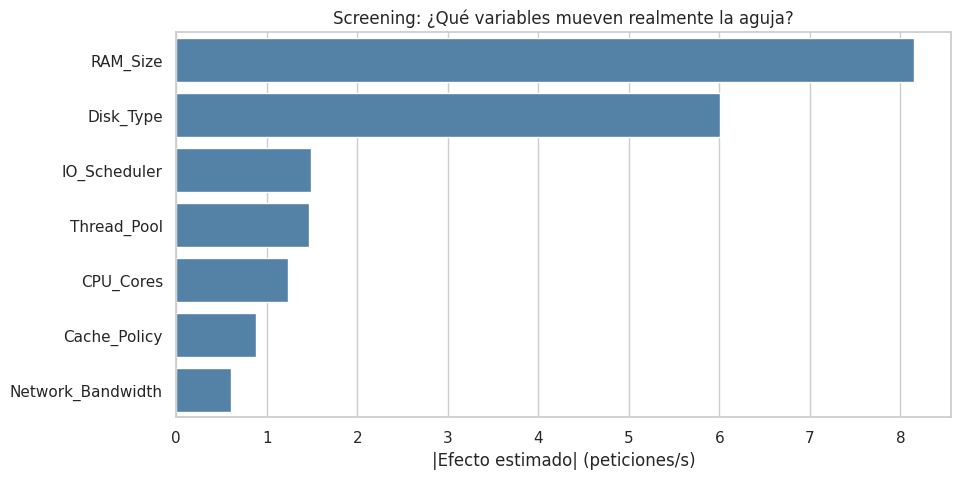

In [ ]:
# @title Solución del ejercicio 2
from pyDOE3 import pbdesign

# 1. Diseño de Plackett-Burman
diseno_pb = pd.DataFrame(pbdesign(7), columns=factores_srv)
print(f"{len(diseno_pb)} configuraciones (factorial completo: {2**7})")

# 2. Plan con 3 réplicas y ejecución
plan_pb = construir_plan(diseno_pb, n_replicas=3, semilla=1)
res_pb = ejecutar_plan(plan_pb, servidor_caja_negra, ['Rendimiento'])

# 3. Efecto de cada factor: media en el nivel alto menos media en el nivel bajo
efectos = pd.Series({f: res_pb.loc[res_pb[f] == 1, 'Rendimiento'].mean()
                        - res_pb.loc[res_pb[f] == -1, 'Rendimiento'].mean()
                     for f in factores_srv})
efectos = efectos.reindex(efectos.abs().sort_values(ascending=False).index)
print(efectos.round(2))

# 4. Gráfico de Pareto de los efectos
plt.figure(figsize=(10, 5))
sns.barplot(x=efectos.abs().values, y=efectos.index, color='steelblue')
plt.xlabel('|Efecto estimado| (peticiones/s)')
plt.ylabel('')
plt.title("Screening: ¿Qué variables mueven realmente la aguja?")
plt.show()
# RAM_Size y Disk_Type destacan sobre el resto; los demás efectos son del tamaño del ruido.

In [ ]:
# @title Solución del ejercicio 3
df_long = df_wide.melt(id_vars='Algoritmo', var_name='Run_ID', value_name='Tiempo')
print("--- Formato Tidy (Long) ---")
print(df_long)

--- Formato Tidy (Long) ---
   Algoritmo Run_ID  Tiempo
0     Algo_A  Run_1     100
1     Algo_B  Run_1     110
2     Algo_C  Run_1      95
3     Algo_A  Run_2     102
4     Algo_B  Run_2     108
5     Algo_C  Run_2      96
6     Algo_A  Run_3     101
7     Algo_B  Run_3     109
8     Algo_C  Run_3      94
9     Algo_A  Run_4      99
10    Algo_B  Run_4     111
11    Algo_C  Run_4      95


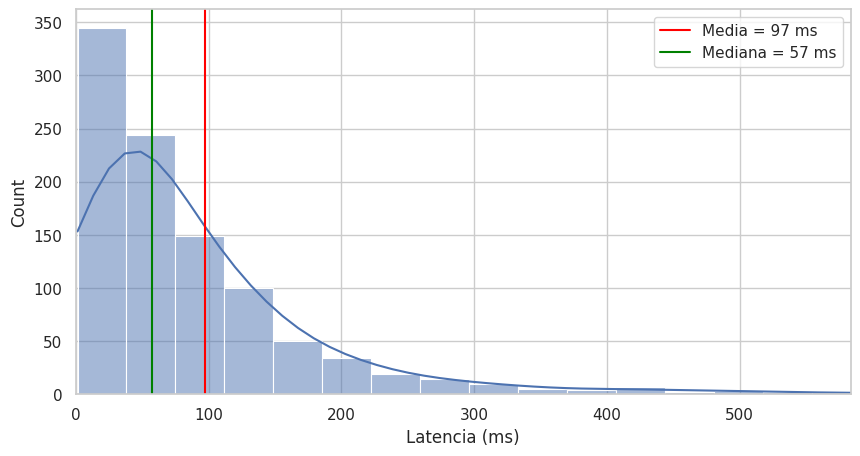

Peticiones más rápidas que la media: 69%


In [ ]:
# @title Solución del ejercicio 4
plt.figure(figsize=(10, 5))
sns.histplot(latencias, kde=True)
plt.axvline(np.mean(latencias), color='red', label=f'Media = {np.mean(latencias):.0f} ms')
plt.axvline(np.median(latencias), color='green', label=f'Mediana = {np.median(latencias):.0f} ms')
plt.xlim(0, np.percentile(latencias, 99))
plt.xlabel('Latencia (ms)')
plt.legend()
plt.show()

print(f"Peticiones más rápidas que la media: {np.mean(latencias < np.mean(latencias)):.0%}")
# La cola larga arrastra la media hacia arriba: la mediana representa mejor al usuario típico.
# Bajar la media puede lograrse recortando solo los casos extremos, sin que la mayoría note nada.

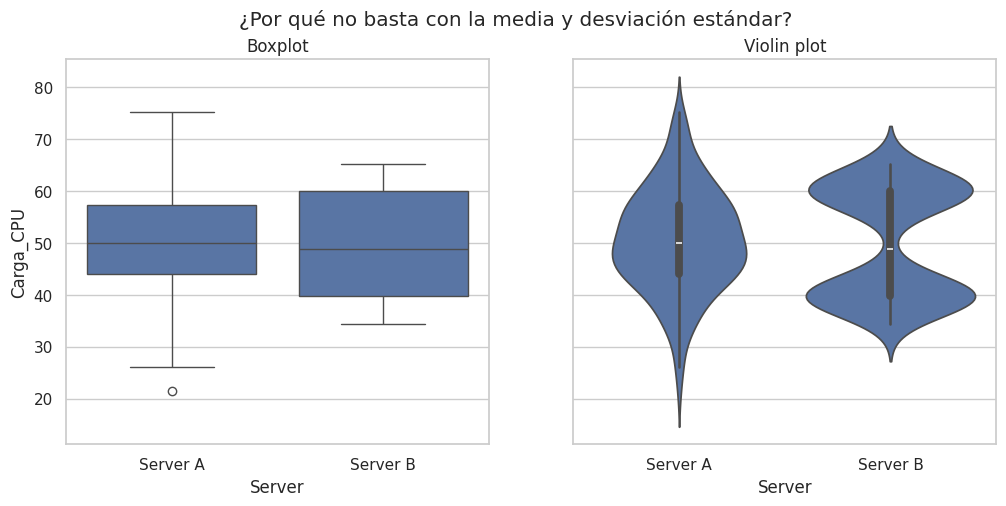

In [ ]:
# @title Solución del ejercicio 5
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
sns.boxplot(data=df_servers, x='Server', y='Carga_CPU', ax=axes[0])
axes[0].set_title('Boxplot')
sns.violinplot(data=df_servers, x='Server', y='Carga_CPU', ax=axes[1])
axes[1].set_title('Violin plot')
fig.suptitle("¿Por qué no basta con la media y desviación estándar?")
plt.show()
# El violin plot muestra las dos modas del Server B; el boxplot las esconde.

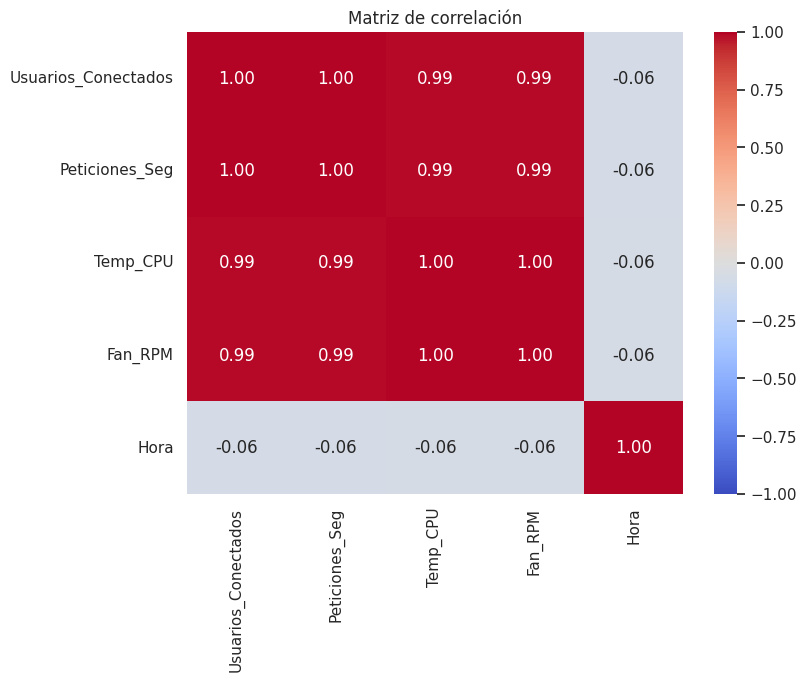

In [ ]:
# @title Solución del ejercicio 6
corr = data.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlación')
plt.show()
# Fan_RPM y Temp_CPU tienen correlación 1: miden lo mismo y basta con incluir una en el modelo.
# Correlación no es causalidad: los usuarios no "causan" las revoluciones del ventilador
# directamente, sino a través de las peticiones y la temperatura.

count       99.0
mean      1050.9
std      10046.2
min        -50.0
25%         20.8
50%         33.9
75%         58.9
max      99999.0
Name: Tiempo_ms, dtype: float64

Valores perdidos: 1
Tiempos negativos: 1
Tiempos iguales a 99999: 1

Filas originales: 100 | filas analizables: 97 | timeouts de los que informar: 1


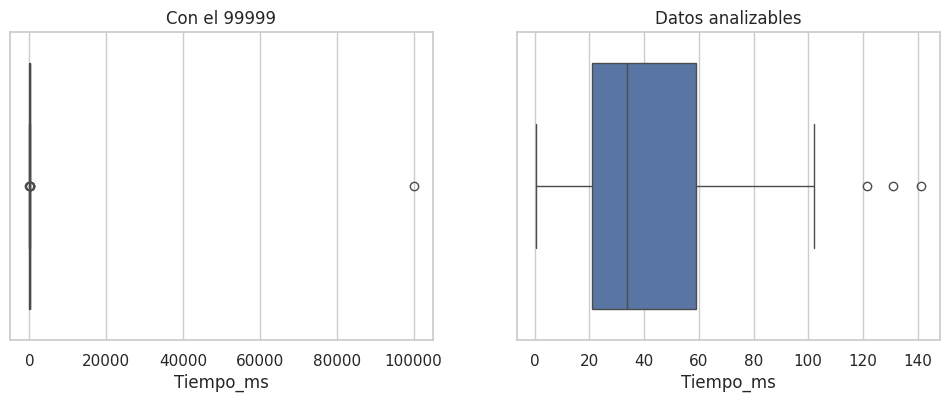

In [ ]:
# @title Solución del ejercicio 7
# 1. Descriptivos: el mínimo y el máximo delatan los valores sospechosos
print(df_dirty['Tiempo_ms'].describe().round(1))
print("\nValores perdidos:", df_dirty['Tiempo_ms'].isna().sum())
print("Tiempos negativos:", (df_dirty['Tiempo_ms'] < 0).sum())
print("Tiempos iguales a 99999:", (df_dirty['Tiempo_ms'] == 99999).sum())

# 2. Decisiones, de las que se deja constancia:
#    - negativo: valor imposible (error de registro) -> se elimina
#    - NaN: valor perdido -> se elimina
#    - 99999: probable código de timeout -> no es un tiempo observado; se aparta y se informa
df_clean = df_dirty[(df_dirty['Tiempo_ms'] >= 0) & (df_dirty['Tiempo_ms'] < 99999)]
print(f"\nFilas originales: {len(df_dirty)} | filas analizables: {len(df_clean)} | "
      f"timeouts de los que informar: {(df_dirty['Tiempo_ms'] == 99999).sum()}")

# 3. El 99999 aplasta el gráfico; sin él se ve la distribución
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df_dirty['Tiempo_ms'], ax=axes[0])
axes[0].set_title('Con el 99999')
sns.boxplot(x=df_clean['Tiempo_ms'], ax=axes[1])
axes[1].set_title('Datos analizables')
plt.show()